<a href="https://colab.research.google.com/github/Carmen10-171/07MIAR_Redes-Neuronales/blob/main/EntregaPracticasGrupo1RNN_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

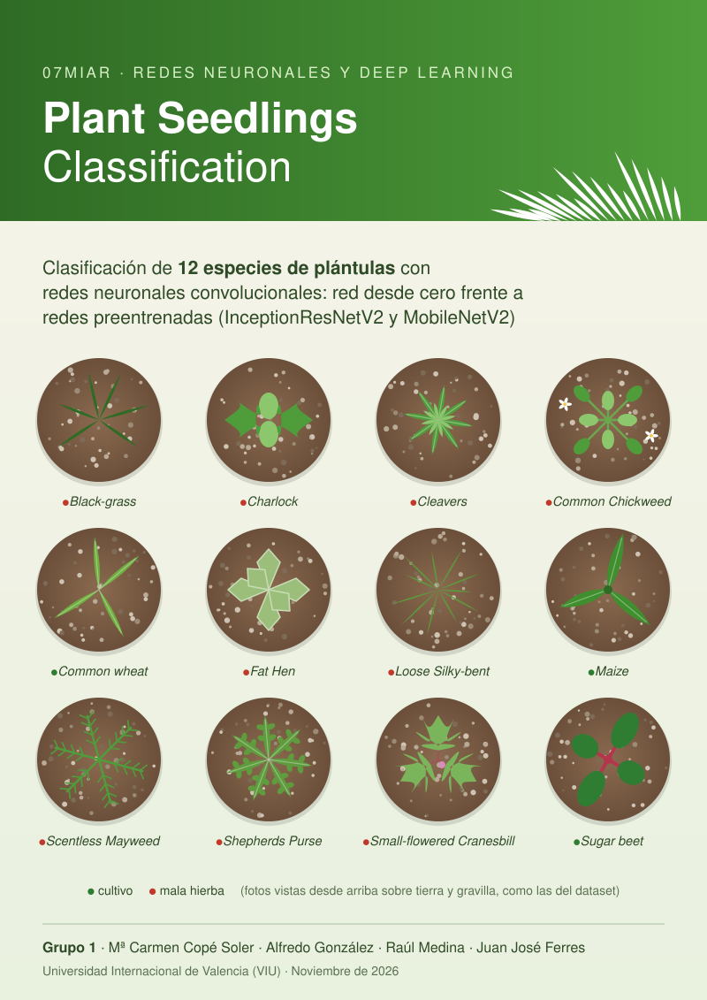

In [ ]:
# @title Portada: las 12 especies del dataset, vistas desde arriba como en las fotos
import math, random
from IPython.display import SVG, display

def portada_svg():
    rnd = random.Random(4096)
    W, H = 800, 1131   # proporción de un A4
    VERDE, VERDE_OSC, VERDE_CLA = "#4f9d3a", "#2f6b25", "#8cc66d"
    out = []
    add = out.append

    def hoja(cx, cy, ang, largo, ancho, color, nervio=True, punta=0.5):
        """Hoja lanceolada que sale de (cx, cy) con un ángulo (grados)."""
        a = math.radians(ang)
        ux, uy = math.cos(a), math.sin(a)
        px, py = -uy, ux
        tx, ty = cx + ux * largo, cy + uy * largo
        mx, my = cx + ux * largo * punta, cy + uy * largo * punta
        c1 = (mx + px * ancho, my + py * ancho)
        c2 = (mx - px * ancho, my - py * ancho)
        add(f'<path d="M{cx:.1f},{cy:.1f} Q{c1[0]:.1f},{c1[1]:.1f} {tx:.1f},{ty:.1f} '
            f'Q{c2[0]:.1f},{c2[1]:.1f} {cx:.1f},{cy:.1f}Z" fill="{color}"/>')
        if nervio:
            add(f'<path d="M{cx:.1f},{cy:.1f} L{cx + ux * largo * 0.92:.1f},{cy + uy * largo * 0.92:.1f}" '
                f'stroke="#ffffff" stroke-opacity="0.35" stroke-width="1.2"/>')

    def ovalo(cx, cy, ang, dist, rx, ry, color, tallo=None):
        a = math.radians(ang)
        x, y = cx + math.cos(a) * dist, cy + math.sin(a) * dist
        if tallo:
            add(f'<line x1="{cx}" y1="{cy}" x2="{x:.1f}" y2="{y:.1f}" stroke="{tallo}" stroke-width="2.5"/>')
        add(f'<ellipse cx="{x:.1f}" cy="{y:.1f}" rx="{rx}" ry="{ry}" fill="{color}" '
            f'transform="rotate({ang:.0f} {x:.1f} {y:.1f})"/>')

    def lobulada(x, y, r, lobulos, color, giro=0):
        """Hoja redonda con lóbulos (cranesbill, charlock)."""
        pts = []
        for i in range(lobulos * 2):
            a = math.radians(giro + i * 180 / lobulos)
            rr = r if i % 2 == 0 else r * 0.62
            pts.append(f"{x + math.cos(a) * rr:.1f},{y + math.sin(a) * rr:.1f}")
        add(f'<path d="M{pts[0]} ' + " ".join(f"T{p}" for p in pts[1:]) + f' T{pts[0]}Z" fill="{color}"/>')

    # Cada especie, dibujada en una baldosa de tierra centrada en (x, y)
    def black_grass(x, y):
        for ang in (-110, -70, -20, 35, 150, 200):
            hoja(x, y, ang + rnd.uniform(-8, 8), rnd.uniform(48, 62), 3.2, VERDE_OSC, nervio=False)
    def charlock(x, y):
        for ang in (-90, 90):
            ovalo(x, y, ang, 16, 15, 11, VERDE_CLA)
        for ang in (0, 180):
            a = math.radians(ang)
            lobulada(x + math.cos(a) * 28, y + math.sin(a) * 28, 22, 5, VERDE, giro=ang)
    def cleavers(x, y):
        for k in range(8):
            hoja(x, y, k * 45 + 10, 40, 6, VERDE)
        for k in range(8):
            hoja(x, y, k * 45 + 32, 20, 4, VERDE_CLA, nervio=False)
    def chickweed(x, y):
        for k, (ang, d) in enumerate([(0, 22), (90, 22), (180, 22), (270, 22), (45, 42), (225, 42), (135, 42), (315, 42)]):
            ovalo(x, y, ang, d, 11, 7, VERDE_CLA if k < 4 else VERDE, tallo="#6aa84f")
        for ang in (20, 200):
            a = math.radians(ang)
            fx, fy = x + math.cos(a) * 52, y + math.sin(a) * 52
            for p in range(5):
                ovalo(fx, fy, p * 72, 4, 4, 1.8, "#ffffff")
            add(f'<circle cx="{fx:.1f}" cy="{fy:.1f}" r="2" fill="#f2c94c"/>')
    def wheat(x, y):
        for ang in (-100, -40, 60, 150):
            hoja(x, y, ang + rnd.uniform(-6, 6), 60, 6, "#6fae3f")
    def fat_hen(x, y):
        for ang in (0, 90, 180, 270, 45, 225):
            d = 26 if ang % 90 == 0 else 14
            a = math.radians(ang)
            hx, hy = x + math.cos(a) * d, y + math.sin(a) * d
            add(f'<path d="M{x},{y} L{hx + math.cos(a + 1.2) * 14:.1f},{hy + math.sin(a + 1.2) * 14:.1f} '
                f'L{hx + math.cos(a) * 20:.1f},{hy + math.sin(a) * 20:.1f} '
                f'L{hx + math.cos(a - 1.2) * 14:.1f},{hy + math.sin(a - 1.2) * 14:.1f}Z" '
                f'fill="#9bbf7a" stroke="#c9dcb7" stroke-width="1.5" stroke-linejoin="round"/>')
    def silky_bent(x, y):
        for k in range(11):
            hoja(x, y, k * 33 + rnd.uniform(-10, 10), rnd.uniform(38, 60), 1.8, "#5c9a3c", nervio=False)
    def maize(x, y):
        for ang, l in ((-75, 66), (40, 62), (160, 58)):
            hoja(x, y, ang, l, 13, "#3f8f2f", punta=0.45)
        add(f'<circle cx="{x}" cy="{y}" r="5" fill="#2f6b25"/>')
    def mayweed(x, y):
        for k in range(6):
            a = math.radians(k * 60 + 15)
            ex, ey = x + math.cos(a) * 52, y + math.sin(a) * 52
            add(f'<line x1="{x}" y1="{y}" x2="{ex:.1f}" y2="{ey:.1f}" stroke="{VERDE}" stroke-width="2.4"/>')
            for t in (0.35, 0.55, 0.75, 0.92):
                bx, by = x + math.cos(a) * 52 * t, y + math.sin(a) * 52 * t
                for s in (1, -1):
                    b = a + s * 0.9
                    add(f'<line x1="{bx:.1f}" y1="{by:.1f}" x2="{bx + math.cos(b) * 10:.1f}" '
                        f'y2="{by + math.sin(b) * 10:.1f}" stroke="{VERDE}" stroke-width="1.6" stroke-linecap="round"/>')
    def shepherds_purse(x, y):
        for k in range(7):
            ang = k * 360 / 7 + 8
            a = math.radians(ang)
            hoja(x, y, ang, 50, 8, "#5e9c3e")
            for t in (0.45, 0.7):
                bx, by = x + math.cos(a) * 50 * t, y + math.sin(a) * 50 * t
                for s in (1, -1):
                    ovalo(bx, by, ang + s * 70, 6, 5, 3.2, "#5e9c3e")
    def cranesbill(x, y):
        for k, ang in enumerate((-90, 30, 150)):
            a = math.radians(ang)
            hx, hy = x + math.cos(a) * 30, y + math.sin(a) * 30
            add(f'<line x1="{x}" y1="{y}" x2="{hx:.1f}" y2="{hy:.1f}" stroke="#a0525c" stroke-width="2"/>')
            lobulada(hx, hy, 20, 7, "#7ab55c", giro=ang)
        add(f'<circle cx="{x + 4}" cy="{y + 6}" r="4" fill="#d48fb5"/>')
    def sugar_beet(x, y):
        for ang in (-60, 120, 30, 210):
            a = math.radians(ang)
            add(f'<line x1="{x}" y1="{y}" x2="{x + math.cos(a) * 20:.1f}" y2="{y + math.sin(a) * 20:.1f}" '
                f'stroke="#b3364d" stroke-width="4" stroke-linecap="round"/>')
            ovalo(x, y, ang, 38 if ang in (-60, 120) else 30, 22 if ang in (-60, 120) else 16, 13, "#2e7d32")
        add(f'<circle cx="{x}" cy="{y}" r="5" fill="#b3364d"/>')

    especies = [("Black-grass", black_grass, False), ("Charlock", charlock, False), ("Cleavers", cleavers, False),
                ("Common Chickweed", chickweed, False), ("Common wheat", wheat, True), ("Fat Hen", fat_hen, False),
                ("Loose Silky-bent", silky_bent, False), ("Maize", maize, True), ("Scentless Mayweed", mayweed, False),
                ("Shepherds Purse", shepherds_purse, False), ("Small-flowered Cranesbill", cranesbill, False),
                ("Sugar beet", sugar_beet, True)]

    # Fondo, franja superior y textos
    add(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {W} {H}" width="100%" '
        f'font-family="Helvetica Neue, Helvetica, Arial, sans-serif">')
    add('<defs><linearGradient id="fondo" x1="0" y1="0" x2="0" y2="1">'
        '<stop offset="0" stop-color="#f7f4ea"/><stop offset="1" stop-color="#e9f1df"/></linearGradient>'
        '<radialGradient id="tierra"><stop offset="0" stop-color="#8a6a4f"/><stop offset="1" stop-color="#6b4f3a"/></radialGradient>'
        '<linearGradient id="banda" x1="0" y1="0" x2="1" y2="0">'
        '<stop offset="0" stop-color="#2f6b25"/><stop offset="1" stop-color="#4f9d3a"/></linearGradient></defs>')
    add(f'<rect width="{W}" height="{H}" fill="url(#fondo)"/>')
    add(f'<rect width="{W}" height="250" fill="url(#banda)"/>')
    for k in range(18):  # hojitas decorativas en la franja
        hoja(W - 30 - k * 9, 250, -100 - k * 4, 40 + (k % 5) * 12, 5, "#ffffff", nervio=False)
    add('<text x="48" y="88" fill="#d9f0c8" font-size="17" letter-spacing="3">07MIAR · REDES NEURONALES Y DEEP LEARNING</text>')
    add('<text x="48" y="150" fill="#ffffff" font-size="48" font-weight="700">Plant Seedlings</text>')
    add('<text x="48" y="205" fill="#ffffff" font-size="48" font-weight="300">Classification</text>')

    add('<text x="48" y="310" fill="#2f4a26" font-size="21">Clasificación de <tspan font-weight="700">12 especies de plántulas</tspan> con</text>')
    add('<text x="48" y="338" fill="#2f4a26" font-size="21">redes neuronales convolucionales: red desde cero frente a</text>')
    add('<text x="48" y="366" fill="#2f4a26" font-size="21">redes preentrenadas (InceptionResNetV2 y MobileNetV2)</text>')

    # Rejilla 4 × 3 de baldosas
    x0, y0, paso_x, paso_y, r = 112, 475, 192, 192, 70
    for i, (nombre, dibujar, cultivo) in enumerate(especies):
        cx, cy = x0 + (i % 4) * paso_x, y0 + (i // 4) * paso_y
        add(f'<circle cx="{cx}" cy="{cy + 3}" r="{r + 2}" fill="#000000" opacity="0.12"/>')
        add(f'<circle cx="{cx}" cy="{cy}" r="{r}" fill="url(#tierra)"/>')
        for _ in range(45):  # gravilla como en las fotos del dataset
            a, d = rnd.uniform(0, 2 * math.pi), r * math.sqrt(rnd.random()) * 0.95
            gris = rnd.choice(["#b9ab98", "#9c8b76", "#cfc4b3", "#7d6a57"])
            add(f'<circle cx="{cx + math.cos(a) * d:.1f}" cy="{cy + math.sin(a) * d:.1f}" '
                f'r="{rnd.uniform(1.2, 3.2):.1f}" fill="{gris}"/>')
        add(f'<clipPath id="c{i}"><circle cx="{cx}" cy="{cy}" r="{r}"/></clipPath><g clip-path="url(#c{i})">')
        dibujar(cx, cy)
        add('</g>')
        color = "#2e7d32" if cultivo else "#c0392b"
        add(f'<text x="{cx}" y="{cy + r + 27}" text-anchor="middle" fill="#2f4a26" font-size="14.5">'
            f'<tspan fill="{color}" font-size="13">● </tspan><tspan font-style="italic">{nombre}</tspan></text>')

    # Leyenda y pie
    add(f'<text x="{W / 2}" y="1012" text-anchor="middle" fill="#2f4a26" font-size="14">'
        '<tspan fill="#2e7d32">●</tspan> cultivo<tspan dx="18" fill="#c0392b">●</tspan> mala hierba'
        '<tspan dx="18" fill="#5b7052">(fotos vistas desde arriba sobre tierra y gravilla, como las del dataset)</tspan></text>')
    add(f'<line x1="48" y1="1045" x2="{W - 48}" y2="1045" stroke="#2f6b25" stroke-opacity="0.35"/>')
    add('<text x="48" y="1077" fill="#2f4a26" font-size="16"><tspan font-weight="700">Grupo 1</tspan> · '
        'Mª Carmen Copé Soler · Alfredo González · Raúl Medina · Juan José Ferres</text>')
    add('<text x="48" y="1103" fill="#5b7052" font-size="14">Universidad Internacional de Valencia (VIU) · Noviembre de 2026</text>')
    add('</svg>')
    return "\n".join(out)

display(SVG(portada_svg()))

<div style="break-before: page;"></div>

## Índice

**[Parte I · Enunciado del ejercicio](#Parte-I-%C2%B7-Enunciado-del-ejercicio)**

- [1. Enunciado](#1.-Enunciado)
- [2. Normas a seguir](#2.-Normas-a-seguir)
- [3. Tips para realizar la actividad con éxito](#3.-Tips-para-realizar-la-actividad-con-%C3%A9xito)
- [4. Criterios de evaluación](#4.-Criterios-de-evaluaci%C3%B3n)

**[Entrega de la práctica](#Entrega-de-la-pr%C3%A1ctica)**

- [0. Trabajo en grupo y repositorio](#0.-Trabajo-en-grupo-y-repositorio)
- [1. Carga del conjunto de datos](#1.-Carga-del-conjunto-de-datos)
    - [1.1 El dataset](#1.1-El-dataset)
- [2. Inspección del conjunto de datos](#2.-Inspecci%C3%B3n-del-conjunto-de-datos)
    - [2.1 Las 12 especies y su reparto](#2.1-Las-12-especies-y-su-reparto) · [2.2 Desbalanceo de clases](#2.2-Desbalanceo-de-clases) · [2.3 Cómo son las imágenes](#2.3-C%C3%B3mo-son-las-im%C3%A1genes) · [2.4 Características técnicas](#2.4-Caracter%C3%ADsticas-t%C3%A9cnicas) · [2.5 Qué decisiones justifica la inspección](#2.5-Qu%C3%A9-decisiones-justifica-la-inspecci%C3%B3n)
- [3. Acondicionamiento del conjunto de datos](#3.-Acondicionamiento-del-conjunto-de-datos)
    - [3.1 Partición en entrenamiento y validación](#3.1-Partici%C3%B3n-en-entrenamiento-y-validaci%C3%B3n) · [3.2 Redimensionado a 224 × 224](#3.2-Redimensionado-a-224-%C3%97-224) · [3.3 Normalización y preparación de los lotes](#3.3-Normalizaci%C3%B3n-y-preparaci%C3%B3n-de-los-lotes) · [3.4 Data augmentation](#3.4-Data-augmentation) · [3.5 Funciones comunes de evaluación](#3.5-Funciones-comunes-de-evaluaci%C3%B3n)
- [4. Estrategia 1, red desde cero](#4.-Estrategia-1,-red-desde-cero)
    - [4.1 Experimento 1, red base](#4.1-Experimento-1,-red-base) · [4.2 Experimento 2, con data augmentation](#4.2-Experimento-2,-con-data-augmentation) · [4.3 Experimento 3, con batch normalization](#4.3-Experimento-3,-con-batch-normalization) · [4.4 Experimento 4, con Dropout](#4.4-Experimento-4,-con-Dropout) · [4.5 Experimento 5, con regularización L2](#4.5-Experimento-5,-con-regularizaci%C3%B3n-L2) · [4.6 Modelo final de la Estrategia 1](#4.6-Modelo-final-de-la-Estrategia-1) · [4.7 Comprobación con las fotos de test de Kaggle](#4.7-Comprobaci%C3%B3n-con-las-fotos-de-test-de-Kaggle)
- [5. Estrategia 2, redes preentrenadas](#5.-Estrategia-2,-redes-preentrenadas)
    - [5.1 InceptionResNetV2](#5.1-InceptionResNetV2) · [5.2 MobileNetV2](#5.2-MobileNetV2) · [5.3 Selección de la red preentrenada con mayor precisión](#5.3-Selecci%C3%B3n-de-la-red-preentrenada-con-mayor-precisi%C3%B3n)
- [6. Comparación de las dos estrategias](#6.-Comparaci%C3%B3n-de-las-dos-estrategias)
    - [6.1 Métricas globales y coste](#6.1-M%C3%A9tricas-globales-y-coste) · [6.2 Comparación por especie](#6.2-Comparaci%C3%B3n-por-especie) · [6.3 Qué muestra la comparación](#6.3-Qu%C3%A9-muestra-la-comparaci%C3%B3n)
- [7. Discusión y conclusiones](#7.-Discusi%C3%B3n-y-conclusiones)
    - [7.1 Resumen de resultados](#7.1-Resumen-de-resultados) · [7.2 Lo que hemos aprendido con la Estrategia 1](#7.2-Lo-que-hemos-aprendido-con-la-Estrategia-1) · [7.3 Lo que hemos aprendido con la Estrategia 2](#7.3-Lo-que-hemos-aprendido-con-la-Estrategia-2) · [7.4 ¿Se podría hacer fine-tuning de nuestra red?](#7.4-%C2%BFSe-podr%C3%ADa-hacer-fine-tuning-de-nuestra-red?) · [7.5 Limitaciones](#7.5-Limitaciones) · [7.6 Posibles mejoras](#7.6-Posibles-mejoras) · [7.7 Conclusión final](#7.7-Conclusi%C3%B3n-final)

<div style="break-after: page;"></div>

# Entrega de prácticas · Grupo 1 · Redes Neuronales

**Asignatura** 07MIAR Redes Neuronales y Deep Learning ·
**Proyecto** *Deep Vision in classification tasks* ·
**Dataset** Plant Seedlings Classification (Kaggle)

**Integrantes:** Raúl Medina, Alfredo González, Mª Carmen Copé Soler, Juan José Ferres.

En este proyecto hemos usado asistentes de inteligencia artificial como apoyo (Claude, Codex y Gemini). Las decisiones, los experimentos y las conclusiones son del grupo y hemos revisado y entendido todo el contenido del cuaderno. Pero la IA ha sido de inestimable ayuda para preparar el código, los gráficos y las tablas.

# Parte I · Enunciado del ejercicio

## 1. Enunciado

En esta actividad, el alumno debe evaluar y comparar dos estrategias para la clasificación de imágenes empleando el dataset asignado. El/La alumnx deberá resolver el reto proponiendo una solución válida basada en aprendizaje profundo, más concretamente en redes neuronales convolucionales (CNNs). Será indispensable que la solución propuesta siga el pipeline visto en clase para resolver este tipo de tareas de inteligencia artificial:

1. Carga del conjunto de datos
2. Inspección del conjunto de datos
3. Acondicionamiento del conjunto de datos
4. Desarrollo de la arquitectura de red neuronal y entrenamiento de la solución
5. Monitorización del proceso de entrenamiento para la toma de decisiones
6. Evaluación del modelo predictivo y planteamiento de la siguiente prueba experimental

### 1.1 Estrategia 1: Entrenar desde cero o *from scratch*

La primera estrategia a comparar será una red neuronal profunda que el alumno debe diseñar, entrenar y optimizar. Se debe justificar empíricamente las decisiones que llevaron a la selección de la arquitectura e hiperparámetros final. Se espera que el alumno utilice todas las técnicas de regularización mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (weight regularization, dropout, batch normalization, data augmentation, etc.).

### 1.2 Estrategia 2: Red pre-entrenada

La segunda estrategia a comparar debe incluir la utilización de una red preentrenada con el dataset ImageNet, llevando a cabo tareas de transfer learning y fine-tuning para resolver la tarea de clasificación asignada. Deben compararse al menos dos tipos de arquitecturas (VGGs, ResNet50, Xception, InceptionV3, InceptionResNetV2, MobileNetV2, DenseNet, ResNet) y se debe seleccionar la que mayor precisión proporcione (información sobre las arquitecturas disponibles en https://keras.io/applications/). Se espera que el/la alumnx utilice todas las técnicas de regularización mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (weight regularization, dropout, batch normalization, data augmentation, etc.).

## 2. Normas a seguir

* Será indispensable realizar el trabajo por parejas. Dichas parejas de alumnxs se generarán de manera automática teniendo en cuenta el pais de residencia con el objetivo de facilitar el trabajo en equipo.
* Se debe entregar un ÚNICO FICHERO PDF POR ALUMNO que incluya las instrucciones presentes en el Colab Noteboook y su EJECUCIÓN!!!. Debe aparecer todo el proceso llevado a cabo en cada estrategia (i.e. carga de datos, inspección de datos, acondicionamiento, proceso de entrenamiento y proceso de validación del modelo).
* La memoria del trabajo (el fichero PDF mencionado en el punto anterior) deberá subirla cada integrante del grupo (aunque se trate de un documento idéntico) a la actividad que se habilitará en CampusVIU.
* Se recomienda trabajar respecto a un directorio base (BASE_FOLDER) para facilitar el trabajo en equipo. En este notebook se incluye un ejemplo de cómo almacenar/cargar datos utilizando un directorio base.
* Las redes propuestas deben estar entrenadas (y EVIDENCIAR este proceso en el documento PDF). La entrega de una red sin entrenar supondrá perdida de puntos.
* Si se desea evidenciar alguna métrica del proceso de entrenamiento (precisión, pérdida, etc.), estas deben ser generadas.
* Todos los gráficos que se deseen mostrar deberán generarse en el Colab Notebook para que tras la conversión aparezcan en el documento PDF.

## 3. Tips para realizar la actividad con éxito

* Los datos se cargarán directamente desde la plataforma Kaggle mediante su API (https://github.com/Kaggle/kaggle-api). En este Notebook se incluye un ejemplo de como hacerlo. Se recomienda generar una función que aborde esta tarea.
* El documento PDF a entregar como solución de la actividad se debe generar automáticamente desde el fichero ".ipynb". En este Notebook se incluye un ejemplo de como hacerlo.
* Generar secciones y subsecciones en el Colab Notebook supondrá que el documento PDF generado queda totalmente ordenado facilitando la evaluación al docente.
* Se recomienda encarecidamente incluir comentarios concisos pero aclaratorios.
* Es muy recomendable crear una última sección de texto en el Colab Notebook en la que se discutan los diferentes modelos obtenidos y se extraigan las conclusiones pertinentes.

## 4. Criterios de evaluación

* Seguimiento de las normas establecidas en la actividad (detalladas anteriormente).
* Creación de una solución que resuelva la tarea de clasificación, i.e. que las figuras de mérito empleadas para medir la bondad del modelo predictivo evidencien un performance superior al rendimiento estocástico.
* Claridad en la creación de la solución, en las justificaciones sobre la toma de decisiones llevada a cabo así como en las comparativas y conclusiones finales.
* Efectividad al presentar las comparaciones entre métricas de evaluación de ambas estrategias.
* Demostración de la utilización de técnicas de regularización para mejorar el rendimiento de los modelos.

# Entrega de la práctica

## 0. Trabajo en grupo y repositorio

**Todos los miembros del grupo han trabajado activamente en el proyecto.** Las decisiones de diseño (la semilla común, el tamaño de las imágenes, el protocolo de entrenamiento, la arquitectura de la red propia o las redes preentrenadas que íbamos a probar) las tomamos entre todos en **cuatro sesiones de trabajo por teleconferencia**.

**Reparto del trabajo.** Dividimos el cuaderno en seis partes y cada integrante se encargó de la suya. Al principio de cada apartado se indica quién es su responsable.

| Parte | Contenido | Responsable |
|---|---|---|
| 01 | 1. Carga · 2. Inspección · 3. Acondicionamiento | Carmen |
| 02 | 4. Introducción de la Estrategia 1, Exp. 1 y 2 | Alfredo |
| 03 | Exp. 3 y 4 | Raúl |
| 04 | Exp. 5 | Alfredo |
| 05 | 4.6 Modelo final, 5. Estrategia 2 y 6. Comparación | Juan José |
| 06 | 7. Discusión y conclusiones | Todo el grupo (por subapartados) |

**Repositorio.** Cada uno subió su parte al repositorio del grupo en GitHub ([github.com/07MIAR-grupo1-plantseedlings/Proyecto-CNN-PlantSeedlings](https://github.com/07MIAR-grupo1-plantseedlings/Proyecto-CNN-PlantSeedlings)). Después unimos las partes en **un único cuaderno de Google Colab**, que es este documento.

**Cómo ejecutar el cuaderno sin volver a entrenar.** Los modelos entrenados (ficheros `.keras`) pesan demasiado para GitHub, así que están en **Google Drive**. Sus historiales de entrenamiento (`*_historial.json`) sí están en el repositorio, en `resultados/`. Si se colocan los dos ficheros de cada modelo en su carpeta, la función `entrenar()` carga el modelo en lugar de entrenarlo y el cuaderno da exactamente los resultados de este documento. Si falta alguno, ese modelo se entrena de nuevo.

| Modelo | Fichero en Google Drive | Tamaño | Carpeta donde colocarlo |
|---|---|---|---|
| Exp. 1, red base | [`exp1_red_base.keras`](https://drive.google.com/file/d/19nuHnqJd8rn0ru6pH3ZOLwvEaN6AgFg3/view?usp=sharing) | 155 MB | `resultados/estrategia1/` |
| Exp. 2, con data augmentation | [`exp2_augmentation.keras`](https://drive.google.com/file/d/1TQ40K0kxwuPwt1lW9evOB3k6jYR0PrpP/view?usp=sharing) | 155 MB | `resultados/estrategia1/` |
| Exp. 3, con batch normalization | [`exp3_batchnorm.keras`](https://drive.google.com/file/d/1x_kpbs1VHIbjeFeL5top0fQ5l4uTqt77/view?usp=sharing) | 155 MB | `resultados/estrategia1/` |
| Exp. 4, con Dropout (modelo final E1) | [`exp4_dropout.keras`](https://drive.google.com/file/d/1q2t56rqnlL3NmGfTxcmIWMeW_q92eJuu/view?usp=sharing) | 155 MB | `resultados/estrategia1/` |
| Exp. 5, con regularización L2 | [`exp5_l2.keras`](https://drive.google.com/file/d/1QNA2UipqqVeKeq1_Ss0oGkQ38Wa--QKB/view?usp=sharing) | 155 MB | `resultados/estrategia1/` |
| InceptionResNetV2 · transfer learning | [`irv2_transfer_learning.keras`](https://drive.google.com/file/d/1IUBhxV0XeAqWUqG-dZdS70SF0irgK-Vd/view?usp=sharing) | 220 MB | `resultados/estrategia2/` |
| InceptionResNetV2 · fine-tuning (modelo final E2) | [`irv2_fine_tuning.keras`](https://drive.google.com/file/d/1ksolBaWmL7tgd1zLD7zyf5ZmXphW4IzY/view?usp=sharing) | 409 MB | `resultados/estrategia2/` |
| MobileNetV2 · transfer learning | [`mnv2_transfer_learning.keras`](https://drive.google.com/file/d/1sXokGx8VHIcvSYTTF3ROcrLOvvGu-6PV/view?usp=sharing) | 10 MB | `resultados/estrategia2/` |
| MobileNetV2 · fine-tuning | [`mnv2_fine_tuning.keras`](https://drive.google.com/file/d/1njI-oQEe2rxpf4bnXd8sjkfhUUa6GaMA/view?usp=sharing) | 23 MB | `resultados/estrategia2/` |

* **En local**, las carpetas están dentro del proyecto (la que contiene `codigo/`).
* **En Colab**, dentro de la carpeta `PlantSeedlings` de Google Drive (`MyDrive/PlantSeedlings/resultados/…`), que el cuaderno monta al empezar.
* El modelo de la prueba de 100 épocas del apartado 4.6 (`exp4_dropout_100_epocas`) es opcional. Si no está, esa celda lo entrena de nuevo.


## 1. Carga del conjunto de datos

**Responsable.** Carmen

**Cómo se ha trabajado.** El cuaderno sigue el procedimiento que indica la práctica. Los datos se cargan desde Kaggle con su API, se usa un directorio base (`BASE_FOLDER`), todo el proceso (carga, inspección, acondicionamiento, entrenamiento y validación) se ejecuta en el propio cuaderno, y todas las gráficas se generan con código. **El mismo cuaderno funciona en Google Colab** sin cambiar nada, porque la primera celda detecta dónde se ejecuta. Por simplicidad, **los modelos se entrenaron en local**, en nuestros propios equipos (más rápidos que Colab), y el cuaderno los vuelve a cargar desde la carpeta `resultados/` en lugar de entrenarlos otra vez.

**Carga de los datos con la API de Kaggle.** La función `cargar_dataset()` busca el dataset en la carpeta `plant-seedlings/` del proyecto y, si no está, lo **descarga de Kaggle con su API** (https://github.com/Kaggle/kaggle-api) y lo descomprime. Son 1,7 GB. Para descargarlo es necesario un **token de la API de Kaggle**.

**Directorio base.** `BASE_FOLDER` es la carpeta del dataset dentro del proyecto. En local, el proyecto es la carpeta que contiene `codigo/`. En Colab, es la carpeta `PlantSeedlings` de Google Drive, que se monta al empezar para que los datos y los modelos no se borren al cerrar la sesión.

**Modelos ya entrenados.** Cada modelo se guarda en `resultados/` con su historial de entrenamiento, y la función `entrenar()` lo carga si ya existe (apartado 4). Así el cuaderno se ejecuta en pocos minutos y da **exactamente los mismos resultados** que aparecen en el texto; si se reentrenara, las cifras cambiarían un poco, porque la GPU no es determinista. Los modelos están también en Google Drive (enlaces en el apartado 0 y en cada experimento). Para usarlos en Colab basta con copiarlos, con sus historiales, a `PlantSeedlings/resultados/` de Drive. Si no están, el cuaderno los entrena de nuevo.

La configuración común del grupo es la **semilla 4096**, imágenes de 224 × 224 y batch de 32.

In [ ]:
import os
import sys
import contextlib
import subprocess
import zipfile
from pathlib import Path

# ¿Se ejecuta en Google Colab o en local?
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # Cliente de la API de Kaggle (en local ya está en requirements.txt)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")                                   # el proyecto se guarda en Google Drive

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # oculta los mensajes informativos de TensorFlow (antes de importarlo)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

@contextlib.contextmanager
def sin_mensajes_del_sistema():
    # Silencia temporalmente los mensajes internos de TensorFlow/Metal que se escriben en stderr
    original, nulo = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    os.dup2(nulo, 2)
    try:
        yield
    finally:
        os.dup2(original, 2); os.close(original); os.close(nulo)

with sin_mensajes_del_sistema():
    tf.constant(0)   # inicializa la GPU aquí, sin mensajes; las celdas siguientes ya no los muestran

# Configuración común del grupo 1 de prácticas
SEED = 4096
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2

# Carpeta del proyecto: en Colab, una carpeta de Google Drive; en local, la que contiene codigo/
if EN_COLAB:
    PROYECTO = Path("/content/drive/MyDrive/PlantSeedlings")
    PROYECTO.mkdir(parents=True, exist_ok=True)
else:
    PROYECTO = next(c for c in [Path.cwd(), *Path.cwd().parents] if (c / "codigo").is_dir())

def descargar_de_kaggle(destino, competicion="plant-seedlings-classification"):
    """Descarga los datos de la competición con la API de Kaggle y los descomprime en `destino`."""
    if EN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")   # token guardado en los Secrets de Colab
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()                       # usa el token de ~/.kaggle/access_token o de KAGGLE_API_TOKEN
    destino.mkdir(parents=True, exist_ok=True)
    api.competition_download_files(competicion, path=destino, quiet=False)
    archivo = destino / f"{competicion}.zip"
    with zipfile.ZipFile(archivo) as z:
        z.extractall(destino)                # train/ (una carpeta por especie), test/ y sample_submission.csv
    archivo.unlink()

def cargar_dataset(nombre="plant-seedlings"):
    """Devuelve la carpeta del dataset. Si no está en el proyecto, la descarga de Kaggle con su API."""
    carpeta = PROYECTO / nombre
    if not (carpeta / "train").is_dir():
        print("El dataset no está en el proyecto: se descarga de Kaggle con su API (1,7 GB)...")
        descargar_de_kaggle(carpeta)
    return carpeta

# En Google Colab usamos la ruta local de descompresión rápida
if EN_COLAB:
    BASE_FOLDER = Path("/content/plant-seedlings")
else:
    BASE_FOLDER = cargar_dataset()

TRAIN_PATH = BASE_FOLDER / "train"
TEST_PATH = BASE_FOLDER / "test"

keras.utils.set_random_seed(SEED)
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU") or "ninguna")
print("BASE_FOLDER:", BASE_FOLDER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno: Google Colab | TensorFlow 2.21.0 | GPU: ninguna
BASE_FOLDER: /content/plant-seedlings


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, zipfile

# 1. Cargamos tu token de los Secretos de Colab
from google.colab import userdata
try:
    token = userdata.get("KAGGLE_API_TOKEN")
    os.environ["KAGGLE_API_TOKEN"] = token
except Exception:
    pass

# 2. Instalamos Kaggle y descargamos la competición
!pip install -q --upgrade kaggle
!mkdir -p /content/plant-seedlings

print("Descargando el dataset desde Kaggle (1,7 GB)...")
!kaggle competitions download -c plant-seedlings-classification -p /content/plant-seedlings

# 3. Descomprimimos el archivo descargado
archivo_zip = "/content/plant-seedlings/plant-seedlings-classification.zip"
if os.path.exists(archivo_zip):
    print("Descomprimiendo imágenes...")
    with zipfile.ZipFile(archivo_zip) as z:
        z.extractall("/content/plant-seedlings")
    os.remove(archivo_zip) # Borramos el zip para ahorrar espacio
    print("¡ÉXITO TOTAL! Ya existe /content/plant-seedlings/train con todas las especies.")
else:
    print("No se pudo descargar automáticamente con la API. Revisa el Camino B.")


Descargando el dataset desde Kaggle (1,7 GB)...
100% 1.69G/1.69G [00:23<00:00, 77.2MB/s]

Descomprimiendo imágenes...
¡ÉXITO TOTAL! Ya existe /content/plant-seedlings/train con todas las especies.


### 1.1 El dataset

**Plant Seedlings Classification** es una competición de Kaggle basada en fotografías tomadas **desde arriba** de **plántulas** (plantas recién germinadas, de pocos días o semanas) sobre suelo con piedrecitas. Cada planta se fotografió varias veces mientras crecía, así que una misma especie aparece en distintas fases de crecimiento.

**Para qué sirve.** En agricultura hay que distinguir el **cultivo** de las **malas hierbas** cuando todavía son muy pequeños, para eliminar solo las hierbas. A esa edad muchas especies se parecen mucho, y es difícil incluso para una persona.

**La tarea.** A partir de una foto, decir a cuál de las **12 especies** pertenece (clasificación multiclase).

**Cómo vienen los datos.**

```
plant-seedlings/
├── train/                  4.750 imágenes con etiqueta
│   ├── Black-grass/        una carpeta por especie: el nombre de la carpeta es la etiqueta
│   ├── Charlock/
│   └── ... (12 carpetas)
├── test/                   794 imágenes SIN etiqueta
└── sample_submission.csv   formato de envío a Kaggle (fichero, especie)
```

* **4.750 imágenes de entrenamiento** repartidas en 12 carpetas, una por especie, y **794 de test**.
* Las imágenes de `test/` **no tienen etiqueta** (son para enviar predicciones a Kaggle). Para evaluar nuestros modelos separaremos un **20 % de `train/` como validación** (apartado 3).


## 2. Inspección del conjunto de datos

**Responsable.** Carmen

Antes de entrenar, observamos los datos sin modificarlos para ver cuántas imágenes hay de cada especie, cómo son y qué características técnicas tienen. Cada cosa que encontremos aquí justifica una decisión de los pasos siguientes (apartado 2.5).

### 2.1 Las 12 especies y su reparto

Tres especies son **cultivos** y nueve son **malas hierbas**. La última columna indica qué parte de las imágenes de entrenamiento corresponde a cada una.

| Especie (nombre en el dataset) | Nombre común | Tipo | % del entrenamiento |
|---|---|---|---:|
| *Maize* | Maíz | **Cultivo** | 4,7 % |
| *Common wheat* | Trigo | **Cultivo** | 4,7 % |
| *Sugar beet* | Remolacha azucarera | **Cultivo** | 8,1 % |
| *Black-grass* | Cola de zorra (*Alopecurus myosuroides*) | Mala hierba | 5,5 % |
| *Loose Silky-bent* | Apera (*Apera spica-venti*) | Mala hierba | 13,8 % |
| *Charlock* | Mostaza silvestre (*Sinapis arvensis*) | Mala hierba | 8,2 % |
| *Cleavers* | Amor de hortelano (*Galium aparine*) | Mala hierba | 6,0 % |
| *Common Chickweed* | Pamplina (*Stellaria media*) | Mala hierba | 12,9 % |
| *Fat Hen* | Cenizo (*Chenopodium album*) | Mala hierba | 10,0 % |
| *Scentless Mayweed* | Manzanilla bastarda (*Tripleurospermum inodorum*) | Mala hierba | 10,9 % |
| *Shepherds Purse* | Bolsa de pastor (*Capsella bursa-pastoris*) | Mala hierba | 4,9 % |
| *Small-flowered Cranesbill* | Geranio de flor pequeña (*Geranium pusillum*) | Mala hierba | 10,4 % |

La celda siguiente cuenta las imágenes directamente de las carpetas y lo representa gráficamente.


In [ ]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display

CULTIVOS = {"Maize", "Common wheat", "Sugar beet"}

# Apuntamos a la ruta unificada de BASE_FOLDER cargada previamente
TRAIN_PATH = Path("/content/plant-seedlings/train")
TEST_PATH = Path("/content/plant-seedlings/test")

try:
    if not TRAIN_PATH.exists():
        raise FileNotFoundError(f"No se encuentra la carpeta de entrenamiento en: {TRAIN_PATH}")

    especies = sorted(d.name for d in TRAIN_PATH.iterdir() if d.is_dir())
    conteo = pd.Series({e: len(list((TRAIN_PATH / e).glob("*.png"))) for e in especies}, name="imágenes")
    tabla = conteo.sort_values(ascending=False).to_frame()
    tabla["%"] = (100 * tabla["imágenes"] / tabla["imágenes"].sum()).round(1)
    tabla["tipo"] = ["cultivo" if e in CULTIVOS else "mala hierba" for e in tabla.index]

    print(f"{len(especies)} especies · {conteo.sum()} imágenes de entrenamiento · "
          f"{len(list(TEST_PATH.glob('*.png')))} de test (sin etiqueta)")
    print(f"Mayor / menor: {conteo.max()} / {conteo.min()} = {conteo.max() / conteo.min():.1f} veces")
    display(tabla)

except Exception as e:
    print(f"⚠️ Error al acceder al dataset: {e}")

12 especies · 4750 imágenes de entrenamiento · 794 de test (sin etiqueta)
Mayor / menor: 654 / 221 = 3.0 veces


,imágenes,%,tipo
Loose Silky-bent,654,13.8,mala hierba
Common Chickweed,611,12.9,mala hierba
Scentless Mayweed,516,10.9,mala hierba
Small-flowered Cranesbill,496,10.4,mala hierba
Fat Hen,475,10.0,mala hierba
Charlock,390,8.2,mala hierba
Sugar beet,385,8.1,cultivo
Cleavers,287,6.0,mala hierba
Black-grass,263,5.5,mala hierba
Shepherds Purse,231,4.9,mala hierba


### Descarga del dataset utilizando comandos de Terminal (`bash`)

Si prefieres interactuar directamente con el sistema operativo para realizar la descarga utilizando la herramienta de línea de comandos de Kaggle, puedes seguir estos pasos:

1. **Obtén tu Token de API**: Ve a tu perfil de Kaggle -> *Settings* -> *Create New Token*. Esto descargará un archivo llamado `kaggle.json`.
2. **Sube el archivo a Colab**: Sube el archivo `kaggle.json` utilizando la barra lateral izquierda o configúralo como un secreto en Colab.
3. **Ejecuta los siguientes comandos** en una celda de terminal:

In [ ]:
import os
import zipfile
from google.colab import userdata

# 1. Intentar obtener de manera segura las credenciales desde los 'Secrets' de Colab
try:
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("✅ Credenciales de Kaggle obtenidas correctamente desde los Secrets de Colab.")
except Exception as e:
    print("⚠️ No se pudieron obtener las credenciales de Kaggle de los Secrets.")
    print("Por favor, asegúrate de configurar 'KAGGLE_USERNAME' y 'KAGGLE_KEY' en el panel lateral (icono de llave 🔑).")

# 2. Descargar y descomprimir el dataset si las credenciales están configuradas
if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
    try:
        print("Iniciando descarga del dataset 'plant-seedlings-classification'...")
        !kaggle competitions download -c plant-seedlings-classification -p /content/plant-seedlings

        zip_path = "/content/plant-seedlings/plant-seedlings-classification.zip"
        if os.path.exists(zip_path):
            print("Descomprimiendo archivos...")
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall("/content/plant-seedlings/")
            os.remove(zip_path)
            print("🎉 ¡Dataset descargado y descomprimido con éxito en /content/plant-seedlings!")
        else:
            print("❌ No se encontró el archivo zip descargado en la ruta especificada.")
    except Exception as e:
        print(f"❌ Error durante la descarga o extracción: {e}")
else:
    print("❌ Autenticación fallida. Configura las claves KAGGLE_USERNAME y KAGGLE_KEY en la sección Secrets de Colab para continuar.")

⚠️ No se pudieron obtener las credenciales de Kaggle de los Secrets.
Por favor, asegúrate de configurar 'KAGGLE_USERNAME' y 'KAGGLE_KEY' en el panel lateral (icono de llave 🔑).
❌ Autenticación fallida. Configura las claves KAGGLE_USERNAME y KAGGLE_KEY en la sección Secrets de Colab para continuar.


In [ ]:
import os

ruta_dataset = '/content/plant-seedlings'
if os.path.exists(ruta_dataset):
    elementos = os.listdir(ruta_dataset)
    print(f"✅ Directorio encontrado: {ruta_dataset}")
    print(f"Contenido principal: {elementos}")

    # Validar si existe la carpeta train y test
    for subcarpeta in ['train', 'test']:
        ruta_sub = os.path.join(ruta_dataset, subcarpeta)
        if os.path.exists(ruta_sub):
            num_archivos = len(os.listdir(ruta_sub))
            print(f"  └─ '{subcarpeta}/' contiene {num_archivos} elementos.")
        else:
            print(f"  ❌ Falta la carpeta obligatoria '{subcarpeta}/'")
else:
    print(f"❌ El directorio {ruta_dataset} no existe en /content/.")

✅ Directorio encontrado: /content/plant-seedlings
Contenido principal: ['train', 'test', 'sample_submission.csv']
  └─ 'train/' contiene 12 elementos.
  └─ 'test/' contiene 794 elementos.


In [ ]:
import os
import pandas as pd

def crear_dataframe_plantas(ruta_train):
    datos = []
    if not os.path.exists(ruta_train):
        print(f"⚠️ La ruta {ruta_train} no existe. Asegúrate de haber descargado y extraído el dataset primero.")
        return None

    for especie in os.listdir(ruta_train):
        ruta_especie = os.path.join(ruta_train, especie)
        if os.path.isdir(ruta_especie):
            for archivo in os.listdir(ruta_especie):
                if archivo.lower().endswith(('.png', '.jpg', '.jpeg')):
                    ruta_completa = os.path.join(ruta_especie, archivo)
                    datos.append({
                        'ruta_imagen': ruta_completa,
                        'especie': especie
                    })

    df = pd.DataFrame(datos)
    return df

# Generar el DataFrame con las imágenes de entrenamiento
path_train = '/content/plant-seedlings/train'
df_plantas = crear_dataframe_plantas(path_train)

if df_plantas is not None:
    print(f"✅ DataFrame creado con éxito. Total de imágenes: {len(df_plantas)}")
    display(df_plantas.head())


✅ DataFrame creado con éxito. Total de imágenes: 4750


,ruta_imagen,especie
0,/content/plant-seedlings/train/Common wheat/39...,Common wheat
1,/content/plant-seedlings/train/Common wheat/ca...,Common wheat
2,/content/plant-seedlings/train/Common wheat/21...,Common wheat
3,/content/plant-seedlings/train/Common wheat/ca...,Common wheat
4,/content/plant-seedlings/train/Common wheat/73...,Common wheat


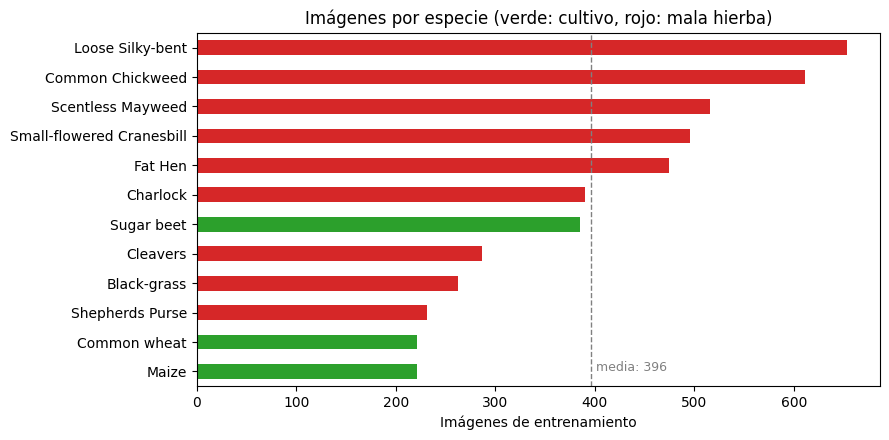

In [ ]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

CULTIVOS = {"Maize", "Common wheat", "Sugar beet"}
TRAIN_PATH = Path("/content/plant-seedlings/train")

try:
    if not TRAIN_PATH.exists():
        raise FileNotFoundError(f"No se encuentra la carpeta de entrenamiento en: {TRAIN_PATH}")

    especies = sorted(d.name for d in TRAIN_PATH.iterdir() if d.is_dir())
    conteo = pd.Series({e: len(list((TRAIN_PATH / e).glob("*.png"))) for e in especies}, name="imágenes")

    # Gráfico del reparto: verde = cultivo, rojo = mala hierba
    orden = conteo.sort_values()
    colores = ["#2ca02c" if e in CULTIVOS else "#d62728" for e in orden.index]

    ax = orden.plot.barh(figsize=(9, 4.5), color=colores)
    ax.axvline(conteo.mean(), color="gray", ls="--", lw=1)
    ax.text(conteo.mean() + 5, 0, f"media: {conteo.mean():.0f}", color="gray", fontsize=9)
    ax.set_xlabel("Imágenes de entrenamiento")
    ax.set_title("Imágenes por especie (verde: cultivo, rojo: mala hierba)")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"⚠️ No se pudo graficar porque el dataset no está listo o autenticado: {e}")

### 2.2 Desbalanceo de clases

El dataset está ligeramente desbalanceado, ya que la especie más frecuente (***Loose Silky-bent***, 13,8 %) tiene unas tres veces más imágenes que las menos frecuentes (***Maize*** y ***Common wheat***, 4,7 % cada una). Esto obliga a interpretar la *accuracy* con cuidado, porque un modelo que no aprende nada puede alcanzar un 8,3 % respondiendo al azar (1/12) o un 13,5 % en validación respondiendo siempre la especie mayoritaria, y todo modelo válido debe superar claramente esas referencias. Además, la red puede equivocarse más en las especies con menos ejemplos.

Aquí esto es especialmente relevante porque los tres cultivos suman solo el 17,4 % de las imágenes, y confundir un cultivo con una mala hierba es el error más costoso en la aplicación real. Lo mismo ocurre con las dos gramíneas casi indistinguibles, ***Black-grass*** (5,5 %) y ***Loose Silky-bent*** (13,8 %), donde la red puede tender a favorecer la más frecuente. Por último, la partición de validación se hace al azar y sin estratificar, de modo que usar todos la misma semilla (4096) garantiza que el desequilibrio sea el mismo en todos los experimentos.

Por estos motivos, además de la accuracy, evaluaremos cada modelo con el **F1 macro**, el **informe por clase** y la **matriz de confusión**. El F1 macro resume en un solo número cómo funciona el modelo en todas las especies, pero, al ser una media, puede ocultar una especie que falla mucho si las demás van bien. Por eso lo completamos con el informe por clase, que muestra qué especie falla, y con la matriz de confusión, que muestra con cuál la confunde (por ejemplo, *Common wheat* y *Black-grass* con *Loose Silky-bent*).

**F1 de una especie.** Combina dos medidas. La **sensibilidad** (*recall*) indica qué parte de las fotos de esa especie reconoce el modelo; por ejemplo, de las 41 fotos de *Common wheat*, cuántas clasifica como *Common wheat*. La **precisión** indica cuántas veces acierta cuando dice esa especie, es decir, de todas las fotos que clasifica como *Common wheat*, cuántas lo son de verdad. El F1 es la media armónica de las dos.

$$F1 = \frac{2 \cdot P \cdot S}{P + S}$$

**F1 macro.** Es la media del F1 de las 12 especies, todas con el mismo peso. En la accuracy, en cambio, cada foto cuenta lo mismo, así que las especies con más fotos pesan más. Con el F1 macro, los fallos en las especies pequeñas no quedan escondidos.

### 2.3 Cómo son las imágenes

Una imagen al azar de cada especie. Usamos la semilla común (`SEED`) solo para que, al volver a ejecutar el cuaderno, salgan siempre las mismas fotos.

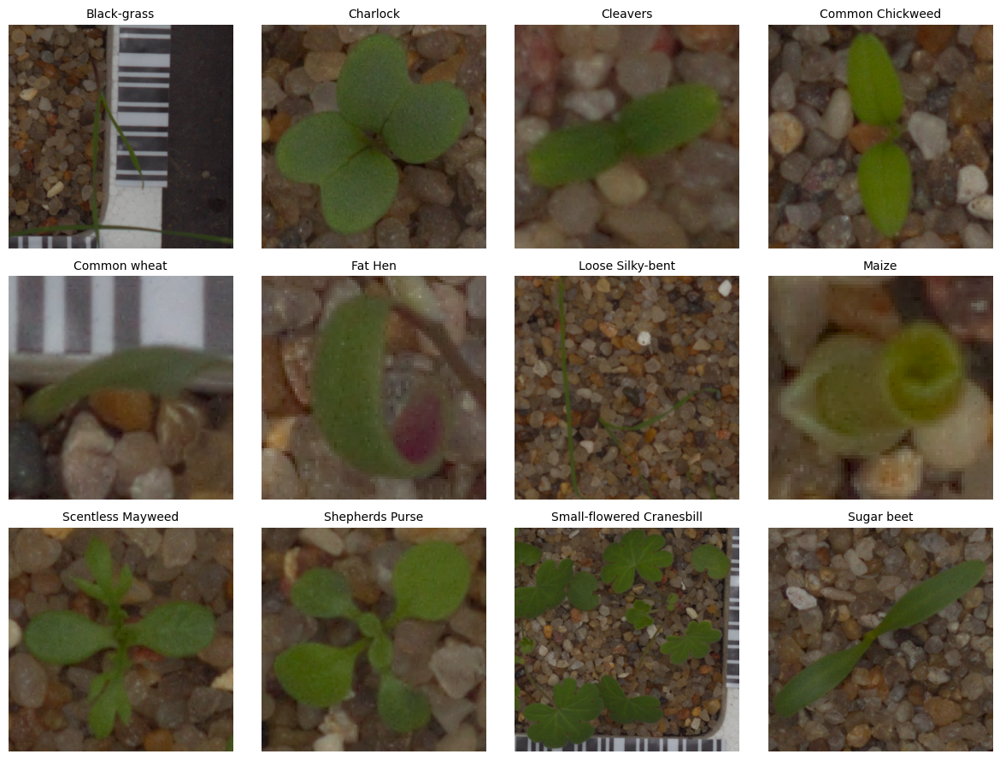

In [ ]:
from PIL import Image

especies = sorted(d.name for d in TRAIN_PATH.iterdir() if d.is_dir())
rng = np.random.default_rng(SEED)   # con la semilla, siempre salen las mismas fotos

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, especie in zip(axes.flat, especies):
    rutas = sorted((TRAIN_PATH / especie).glob("*.png"))
    img = Image.open(rutas[rng.integers(len(rutas))]).convert("RGB")
    ax.imshow(img)
    ax.set_title(especie, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

Todas las fotos están tomadas desde arriba, sobre el mismo tipo de suelo con piedrecitas, y en algunas aparece parte de la bandeja o una regla de color. Lo que distingue unas especies de otras es **la forma de las hojas**, que pueden ser anchas y redondeadas (*Charlock*, *Sugar beet*, *Small-flowered Cranesbill*), pequeñas y numerosas (*Common Chickweed*, *Scentless Mayweed*) o finas y alargadas (las gramíneas).

**Especies que se parecen mucho.** Las tres especies de hojas finas y alargadas son **gramíneas** y, en sus primeras fases, son casi indistinguibles. Una es un cultivo (*Common wheat*) y dos son malas hierbas (*Black-grass* y *Loose Silky-bent*). Además, cada especie cambia mucho según la fase de crecimiento y el zoom de la foto.

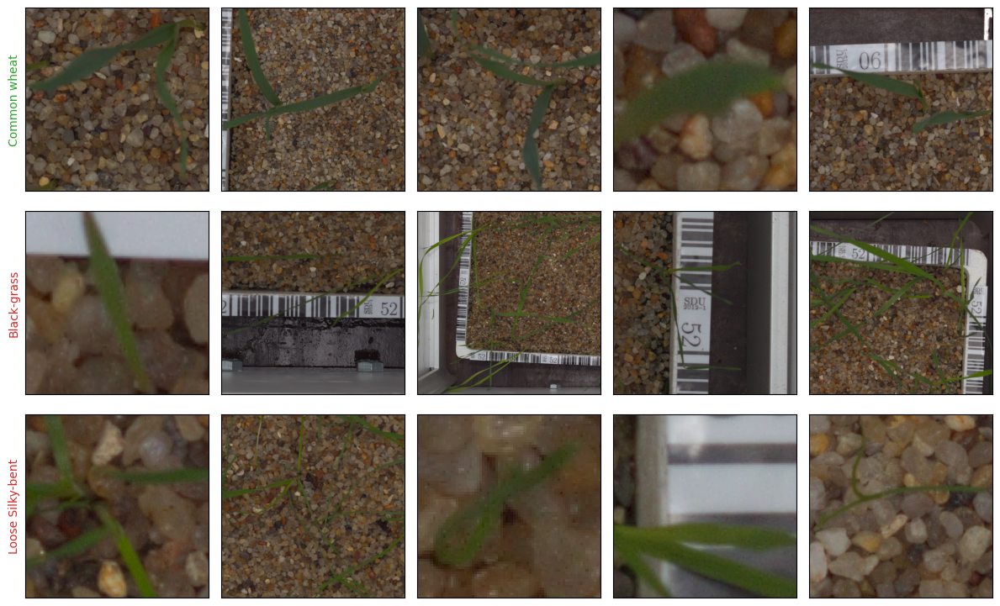

In [ ]:
# Cinco ejemplos de cada gramínea: se parecen mucho entre sí
parecidas = ["Common wheat", "Black-grass", "Loose Silky-bent"]
fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for fila, especie in zip(axes, parecidas):
    rutas = sorted((TRAIN_PATH / especie).glob("*.png"))
    for ax, i in zip(fila, rng.choice(len(rutas), size=5, replace=False)):
        ax.imshow(Image.open(rutas[i]).convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
    color = "#2ca02c" if especie in CULTIVOS else "#d62728"
    fila[0].set_ylabel(especie, fontsize=10, color=color)
plt.tight_layout()
plt.show()

### 2.4 Características técnicas

Comprobamos el tamaño y el formato de color de todas las imágenes de entrenamiento.

Ancho: de 49 a 3991 píxeles (mediana 266)
Imágenes cuadradas: 98.5%
Más pequeñas que 224 px: 46.3%
Modos de color: {'RGB': 4726, 'RGBA': 24}


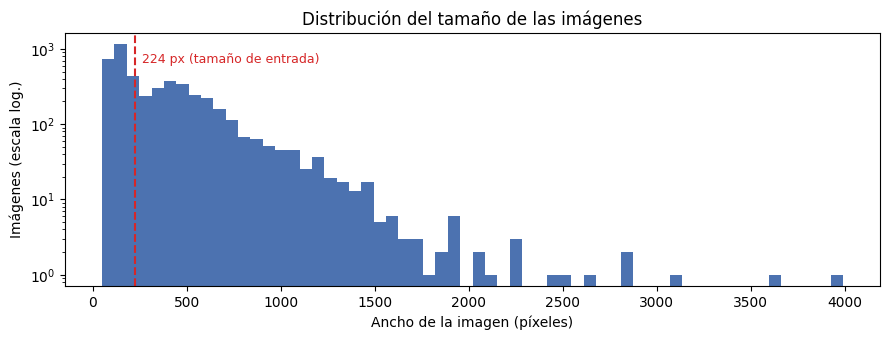

In [ ]:
# Tamaño y modo de color de cada imagen
info = []
for e in especies:
    for r in (TRAIN_PATH / e).glob("*.png"):
        with Image.open(r) as im:
            info.append((e, im.size[0], im.size[1], im.mode))
info = pd.DataFrame(info, columns=["especie", "ancho", "alto", "modo"])

print(f"Ancho: de {info.ancho.min()} a {info.ancho.max()} píxeles (mediana {info.ancho.median():.0f})")
print(f"Imágenes cuadradas: {(info.ancho == info.alto).mean():.1%}")
print(f"Más pequeñas que 224 px: {(info.ancho < 224).mean():.1%}")
print("Modos de color:", info.modo.value_counts().to_dict())

ax = info.ancho.plot.hist(bins=60, figsize=(9, 3.5), color="#4c72b0", log=True)
ax.axvline(224, color="#d62728", ls="--")
ax.text(260, ax.get_ylim()[1] * 0.4, "224 px (tamaño de entrada)", color="#d62728", fontsize=9)
ax.set_xlabel("Ancho de la imagen (píxeles)"); ax.set_ylabel("Imágenes (escala log.)")
ax.set_title("Distribución del tamaño de las imágenes")
plt.tight_layout()
plt.show()

Casi todas las imágenes son cuadradas, pero su tamaño varía enormemente, de menos de 50 a casi 4.000 píxeles de lado, con tres de cada cuatro por debajo de 500. Una red necesita un tamaño de entrada fijo, así que habrá que redimensionarlas. Las grandes perderán detalle y las pequeñas (casi la mitad mide menos de 224 píxeles) se ampliarán y se verán algo borrosas. Casi todas están en color RGB, y unas pocas (RGBA) tienen además un canal de transparencia que no aporta información y se descarta al cargarlas.

### 2.5 Qué decisiones justifica la inspección

| Observación | Decisión |
|---|---|
| Tamaños muy distintos (de 49 a 3.991 píxeles) | Redimensionar todas las imágenes a **224 × 224**, el tamaño habitual de las redes preentrenadas con ImageNet |
| Algunas imágenes tienen canal de transparencia | Cargar todas en **RGB** (3 canales) |
| Dataset desbalanceado (de 221 a 654 imágenes por especie) | Cómo evaluaremos los modelos. Como la accuracy está dominada por las especies con más imágenes, mediremos también el **F1 macro** (media de la nota de cada especie, todas con el mismo peso), el **informe por clase** (en qué especies falla el modelo) y la **matriz de confusión** (con qué se confunde cada una). Además, todo modelo debe superar claramente dos referencias, que son responder al azar (8,3 %) y elegir siempre la especie más frecuente, *Loose Silky-bent* (13,5 % en validación). |
| Especies muy parecidas y en distintas fases de crecimiento, fotografiadas desde arriba | Aplicar **data augmentation** en el entrenamiento como voltear, rotar, acercar y desplazar cada foto al azar. Una planta fotografiada desde arriba sigue siendo la misma especie aunque esté girada, más cerca o desplazada, así que la red ve más variedad sin necesidad de más fotos y se reduce el sobreajuste. |
| Las imágenes de test no tienen etiqueta | Separar un **20 % de `train/` como validación**, con la misma semilla (4096) para todo el grupo |

## 3. Acondicionamiento del conjunto de datos

**Responsable.** Carmen

En este paso preparamos los datos para que la red pueda usarlos, aplicando las decisiones de la inspección (apartado 2.5). Estas son las preparaciones que aplicamos.

| Qué | A qué datos | Desde cuándo |
|---|---|---|
| Partición 80/20 con la semilla 4096 | Todas las imágenes | Todos los experimentos |
| Redimensionar a 224 × 224, RGB y normalizar | Entrenamiento y validación | Todos los experimentos |
| Data augmentation (voltear, rotar, zoom, desplazar) | Solo entrenamiento | A partir del Exp. 2 |

Al final del apartado se definen las **funciones comunes de evaluación**, para que todos los experimentos se midan exactamente igual.

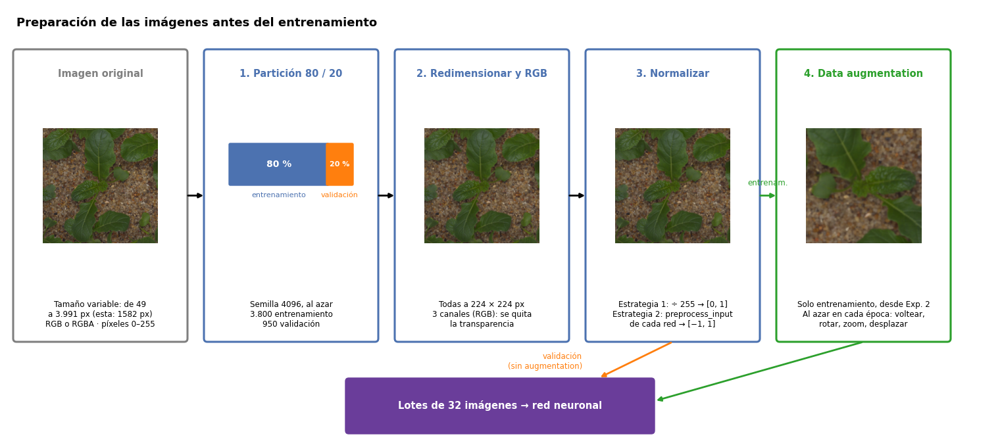

In [ ]:
# @title Diagrama: preparación de las imágenes antes del entrenamiento
from matplotlib.patches import FancyBboxPatch
from PIL import Image

FIGURAS = BASE_FOLDER.parent / "resultados" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Una foto real grande para ilustrar cada paso
rutas = sorted((TRAIN_PATH / "Charlock").glob("*.png"))
ruta = max(rutas, key=lambda r: Image.open(r).size[0])
original = Image.open(ruta).convert("RGB")
redimensionada = original.resize((224, 224), Image.BILINEAR)
# Ilustración del augmentation: volteo + giro de 30° + zoom (recorte central, sin esquinas vacías)
girada = redimensionada.transpose(Image.FLIP_LEFT_RIGHT).rotate(30, resample=Image.BILINEAR)
aumentada = girada.crop((45, 45, 179, 179)).resize((224, 224), Image.BILINEAR)

AZUL, VERDE, NARANJA, MORADO, GRIS = "#4c72b0", "#2ca02c", "#ff7f0e", "#6a3d9a", "#7f7f7f"
fig = plt.figure(figsize=(15, 6.6))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 15); ax.set_ylim(0, 6.6); ax.axis("off")

def _caja(x, y, w, h, color, titulo, texto):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc="white", ec=color, lw=2.2))
    ax.text(x + w / 2, y + h - 0.25, titulo, ha="center", va="top", fontsize=10.5, weight="bold", color=color)
    ax.text(x + w / 2, y + 0.15, texto, ha="center", va="bottom", fontsize=8.6)

def _foto(img, x, y, lado=1.75):
    eje = fig.add_axes([x / 15, y / 6.6, lado / 15, lado / 6.6])
    eje.imshow(img); eje.axis("off")

def _flecha(x0, y0, x1, y1, color="black", texto=None):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2))
    if texto:
        ax.text((x0 + x1) / 2, y0 + 0.12, texto, ha="center", va="bottom", fontsize=8.5, color=color)

ax.text(0.15, 6.3, "Preparación de las imágenes antes del entrenamiento", fontsize=13, weight="bold")
W, H, Y = 2.55, 4.35, 1.55
xs = [0.15, 3.05, 5.95, 8.85]

_caja(xs[0], Y, W, H, GRIS, "Imagen original",
      f"Tamaño variable: de 49\na 3.991 px (esta: {original.size[0]} px)\nRGB o RGBA · píxeles 0–255")
_foto(original, xs[0] + 0.4, Y + 1.45)

_caja(xs[1], Y, W, H, AZUL, "1. Partición 80 / 20",
      "Semilla 4096, al azar\n3.800 entrenamiento\n950 validación")
ax.add_patch(FancyBboxPatch((xs[1] + 0.35, Y + 2.35), 1.85 * 0.8, 0.6, boxstyle="round,pad=0.02", fc=AZUL, ec=AZUL))
ax.add_patch(FancyBboxPatch((xs[1] + 0.35 + 1.85 * 0.8, Y + 2.35), 1.85 * 0.2, 0.6, boxstyle="round,pad=0.02", fc=NARANJA, ec=NARANJA))
ax.text(xs[1] + 0.35 + 0.74, Y + 2.65, "80 %", ha="center", va="center", color="white", weight="bold")
ax.text(xs[1] + 0.35 + 1.665, Y + 2.65, "20 %", ha="center", va="center", color="white", weight="bold", fontsize=8)
ax.text(xs[1] + 0.35 + 0.74, Y + 2.15, "entrenamiento", ha="center", fontsize=8, color=AZUL)
ax.text(xs[1] + 0.35 + 1.665, Y + 2.15, "validación", ha="center", fontsize=8, color=NARANJA)

_caja(xs[2], Y, W, H, AZUL, "2. Redimensionar y RGB",
      "Todas a 224 × 224 px\n3 canales (RGB): se quita\nla transparencia")
_foto(redimensionada, xs[2] + 0.4, Y + 1.45)

_caja(xs[3], Y, W, H, AZUL, "3. Normalizar",
      "Estrategia 1: ÷ 255 → [0, 1]\nEstrategia 2: preprocess_input\nde cada red → [−1, 1]")
_foto(redimensionada, xs[3] + 0.4, Y + 1.45)

xa = 11.75
_caja(xa, Y, W, H, VERDE, "4. Data augmentation",
      "Solo entrenamiento, desde Exp. 2\nAl azar en cada época: voltear,\nrotar, zoom, desplazar")
_foto(aumentada, xa + 0.4, Y + 1.45)

for a, b in zip(xs, xs[1:]):
    _flecha(a + W + 0.03, Y + H / 2, b - 0.03, Y + H / 2)
_flecha(xs[3] + W + 0.03, Y + H / 2, xa - 0.03, Y + H / 2, VERDE, "entrenam.")

# Salida: lotes hacia la red
ax.add_patch(FancyBboxPatch((5.2, 0.15), 4.6, 0.75, boxstyle="round,pad=0.05", fc=MORADO, ec=MORADO))
ax.text(7.5, 0.53, "Lotes de 32 imágenes → red neuronal", ha="center", va="center",
        color="white", weight="bold", fontsize=10.5)
_flecha(xa + W / 2, Y - 0.05, 9.85, 0.6, VERDE)
_flecha(xs[3] + W / 2, Y - 0.05, 9.0, 0.95, NARANJA)
ax.text(8.75, 1.2, "validación\n(sin augmentation)", fontsize=8.5, color=NARANJA, va="center", ha="right")

fig.savefig(FIGURAS / "acondicionamiento_imagenes.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.1 Partición en entrenamiento y validación

Las imágenes de `test/` no tienen etiqueta, así que separamos un **20 % de `train/` como validación**. `image_dataset_from_directory` lee las carpetas, usa el nombre de cada carpeta como etiqueta y hace la partición al azar con la semilla común. En la misma lectura, hace lo siguiente.

* **Redimensiona** todas las imágenes a 224 × 224 (interpolación bilineal).
* Las carga en **RGB** (3 canales), y el canal de transparencia de las imágenes RGBA se descarta.
* Las agrupa en **lotes de 32**.

In [ ]:
from keras import layers

# Lectura de las carpetas, partición 80/20 con la semilla común y redimensionado a 224x224
opciones = dict(validation_split=VALIDATION_SPLIT, seed=SEED, image_size=IMG_SIZE,
                batch_size=BATCH_SIZE, color_mode="rgb", label_mode="int")
train_raw = keras.utils.image_dataset_from_directory(TRAIN_PATH, subset="training", **opciones)
val_raw = keras.utils.image_dataset_from_directory(TRAIN_PATH, subset="validation", **opciones)

CLASES = train_raw.class_names          # orden alfabético: el índice de cada especie
NUM_CLASES = len(CLASES)

# cache(): las imágenes se leen del disco una sola vez y se guardan en memoria.
# Además fija el orden de la validación, de modo que etiquetas y predicciones coinciden.
train_raw = train_raw.cache()
val_raw = val_raw.cache()

y_train = np.concatenate([y.numpy() for _, y in train_raw])
y_val = np.concatenate([y.numpy() for _, y in val_raw])
print(f"Entrenamiento: {len(y_train)} imágenes · Validación: {len(y_val)} imágenes · {NUM_CLASES} clases")

Found 4750 files belonging to 12 classes.
Using 3800 files for training.
Found 4750 files belonging to 12 classes.
Using 950 files for validation.
Entrenamiento: 3800 imágenes · Validación: 950 imágenes · 12 clases


La partición se hace **al azar y sin estratificar** por especie, así que la proporción de cada especie en validación no es exactamente la misma que en entrenamiento. Lo comprobamos a continuación.

In [ ]:
reparto = pd.DataFrame({
    "entrenamiento": np.bincount(y_train, minlength=NUM_CLASES),
    "validación": np.bincount(y_val, minlength=NUM_CLASES),
}, index=CLASES)
reparto["% en validación"] = (100 * reparto["validación"] / (reparto["entrenamiento"] + reparto["validación"])).round(1)
reparto

,entrenamiento,validación,% en validación
Black-grass,213,50,19.0
Charlock,313,77,19.7
Cleavers,235,52,18.1
Common Chickweed,487,124,20.3
Common wheat,180,41,18.6
Fat Hen,380,95,20.0
Loose Silky-bent,526,128,19.6
Maize,172,49,22.2
Scentless Mayweed,413,103,20.0
Shepherds Purse,179,52,22.5


Cada especie tiene entre un 18 % y un 23 % de sus imágenes en validación, alrededor del 20 % esperado. Es la variación normal de un reparto al azar. Como todo el grupo usa la semilla 4096, **todos los modelos se evalúan con estas mismas 950 imágenes**, y las comparaciones son justas.

### 3.2 Redimensionado a 224 × 224

Comparamos dos imágenes antes y después del redimensionado, una muy grande, que pierde detalle, y una muy pequeña, que se amplía y se ve más borrosa.

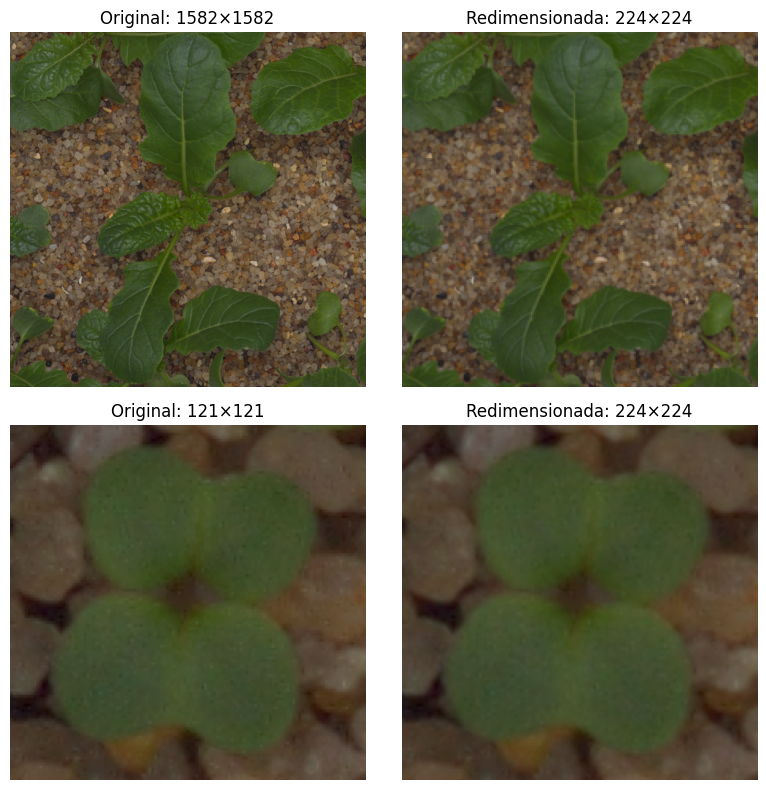

In [ ]:
from PIL import Image

# La imagen más grande y la más pequeña de una especie, antes y después de redimensionar
rutas = sorted((TRAIN_PATH / "Charlock").glob("*.png"))
tamanos = [Image.open(r).size[0] for r in rutas]
extremos = [rutas[int(np.argmax(tamanos))], rutas[int(np.argmin(tamanos))]]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for fila, ruta in zip(axes, extremos):
    original = Image.open(ruta).convert("RGB")
    redimensionada = original.resize(IMG_SIZE, Image.BILINEAR)
    fila[0].imshow(original); fila[0].set_title(f"Original: {original.size[0]}×{original.size[1]}")
    fila[1].imshow(redimensionada); fila[1].set_title("Redimensionada: 224×224")
    for ax in fila: ax.axis("off")
plt.tight_layout()
plt.show()

### 3.3 Normalización y preparación de los lotes

Los píxeles llegan con valores entre 0 y 255. Las redes entrenan mejor con valores pequeños, así que dividimos entre 255 para dejar los valores entre **0 y 1**, igual que en el notebook común (`Rescaling(1./255)`).

Las redes preentrenadas de la Estrategia 2 (InceptionResNetV2 y MobileNetV2) aprendieron con valores entre **−1 y 1**, y necesitan recibir los píxeles en esa misma escala. En la sección 5, una capa `Rescaling(2, offset=-1)` dentro del modelo pasará nuestros datos de [0, 1] a ese rango, que es lo mismo que hace su `preprocess_input`.

Durante el entrenamiento, las fotos se le dan a la red en lotes de **32**. En cada época se cambia el orden de los lotes (shuffle) para que la red no se acostumbre siempre a la misma secuencia, y con prefetch se prepara el siguiente lote mientras la GPU entrena con el actual, lo que acelera el entrenamiento sin cambiar el resultado.


In [ ]:
normalizar = layers.Rescaling(1.0 / 255)

# Normalización de valores entre 0 y 1
train_ds = (train_raw.map(lambda x, y: (normalizar(x), y))
            .shuffle(1000, seed=SEED).prefetch(tf.data.AUTOTUNE))
val_ds = val_raw.map(lambda x, y: (normalizar(x), y)).prefetch(tf.data.AUTOTUNE)

lote_x, lote_y = next(iter(train_ds))
print("Forma de un lote:", tuple(lote_x.shape), "· etiquetas:", tuple(lote_y.shape))
print(f"Valores de los píxeles: de {float(tf.reduce_min(lote_x)):.2f} a {float(tf.reduce_max(lote_x)):.2f}")

Forma de un lote: (32, 224, 224, 3) · etiquetas: (32,)
Valores de los píxeles: de 0.00 a 0.95


### 3.4 Data augmentation

El data augmentation **no crea imágenes nuevas en disco**. En cada época, cada foto de entrenamiento se transforma **al azar** (se voltea, se gira, se amplía o se desplaza un poco), así que la red nunca ve exactamente la misma imagen dos veces. Esto reduce el sobreajuste y tiene sentido aquí porque las fotos están tomadas desde arriba, y una planta girada o vista un poco más de cerca sigue siendo de la misma especie.

* Se aplica **solo en entrenamiento**. La validación usa las fotos originales.
* Se define aquí, pero **se usa a partir del Exp. 2**, que es el experimento que lo añade. Va como primeras capas del modelo, y Keras lo activa al entrenar y lo desactiva al evaluar.
  
Usamos estas transformaciones.

| Transformación | Código | Qué hace |
|---|---|---|
| Voltear | `RandomFlip("horizontal")` | Refleja la foto de izquierda a derecha, la mitad de las veces |
| Girar | `RandomRotation(0.15)` | Gira hasta ±54° (0,15 de una vuelta) |
| Ampliar o alejar | `RandomZoom(0.15)` | Acerca o aleja hasta un 15 % |
| Desplazar | `RandomTranslation(0.1, 0.1)` | Mueve hasta un 10 % en vertical y horizontal |

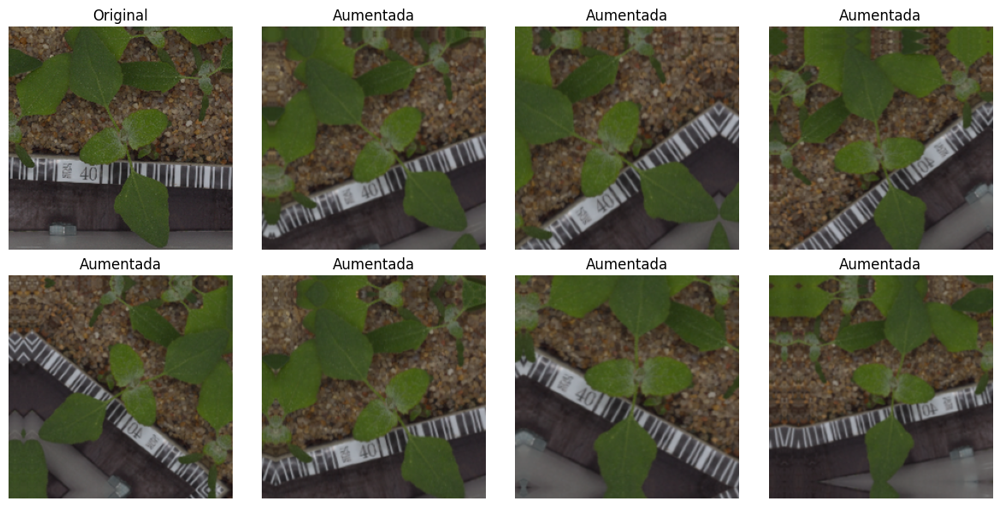

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),                               # hasta ±54 grados
    layers.RandomZoom(0.15),                                   # hasta ±15 % de zoom
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
], name="data_augmentation")

# La misma foto transformada 7 veces al azar
foto = next(iter(train_ds))[0][:1]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes.flat[0].imshow(foto[0]); axes.flat[0].set_title("Original")
for ax in axes.flat[1:]:
    ax.imshow(np.clip(data_augmentation(foto, training=True)[0], 0, 1))
    ax.set_title("Aumentada")
for ax in axes.flat: ax.axis("off")
plt.tight_layout()
plt.show()

### 3.5 Funciones comunes de evaluación

Todos los experimentos se evalúan con las mismas funciones, sobre las mismas **950** imágenes de validación.

* `curvas(historial)` muestra la accuracy y la pérdida de entrenamiento y validación por época (paso 5 del pipeline, **monitorización**).
* `evaluar(modelo)` calcula la **accuracy**, **F1 macro**, **informe por clase** y **matriz de confusión** (paso 6, **evaluación**).

`curvas(historial)` sirve para la **monitorización** (paso 5 del enunciado). Recibe el historial que devuelve `modelo.fit()`, con la accuracy y la pérdida de cada época, y dibuja dos gráficas.

* **Accuracy.** Entrenamiento, validación y una línea gris discontinua en el 13,5 % (responder siempre la clase mayoritaria). Si la validación no se separa claramente de esa línea, la red no ha aprendido nada.
* **Pérdida.** Entrenamiento y validación.

Permite ver **cómo** aprende la red. Si las dos líneas mejoran juntas, aprende bien. Si la de entrenamiento sigue mejorando y la de validación empeora, hay **sobreajuste**.

`evaluar(modelo)` sirve para la **evaluación** (paso 6 del enunciado) del modelo terminado de la siguiente forma.

1. **Predice la validación lote a lote.** Para cada foto, el modelo da 12 probabilidades y nos quedamos con la especie más probable (`argmax`). Como cada foto y su etiqueta salen del mismo lote, nunca se desordenan.
2. **Muestra tres resultados.**
   * **Accuracy y F1 macro**, junto a las dos referencias (azar y clase mayoritaria).
   * **Informe por clase.** Precisión, sensibilidad y F1 de cada especie, para ver **qué especie falla**.
   * **Matriz de confusión.** Cada fila es la especie real y cada columna la que dijo el modelo. La diagonal son los aciertos, y fuera de ella se ve **con qué especie se confunde** cada una.
3. **Devuelve el resultado** (accuracy y F1 macro), que se guarda para la comparación final (apartado 6).

| Función | Cuándo mira | Pregunta que responde | Paso del pipeline |
|---|---|---|---|
| `curvas()` | Durante el entrenamiento, época a época | ¿Aprende bien o sobreajusta? | 5. Monitorización |
| `evaluar()` | Al final, con el modelo terminado | ¿Cómo de bueno es y en qué falla? | 6. Evaluación |


Por el desbalanceo (apartado 2.2), cada resultado se compara con dos referencias mínimas, calculadas sobre la validación, que son responder **al azar** y responder **siempre la especie más frecuente**. Se calcula de la siguiente manera.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

REF_AZAR = 1 / NUM_CLASES
REF_MAYORITARIA = np.bincount(y_val).max() / len(y_val)
print(f"Referencias en validación: azar {REF_AZAR:.1%} · siempre la clase mayoritaria "
      f"({CLASES[np.bincount(y_val).argmax()]}) {REF_MAYORITARIA:.1%}")


def curvas(historial, titulo=""):
    # Accuracy y pérdida por época, en entrenamiento y validación
    h = historial.history
    epocas = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nombre in zip(axes, ["accuracy", "loss"], ["Accuracy", "Pérdida"]):
        ax.plot(epocas, h[metrica], marker="o", label="Entrenamiento")
        ax.plot(epocas, h["val_" + metrica], marker="o", label="Validación")
        ax.set_xlabel("Época"); ax.set_ylabel(nombre); ax.legend()
    axes[0].axhline(REF_MAYORITARIA, color="gray", ls="--", lw=1)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def evaluar(modelo, datos=None, titulo=""):
    # Predice la validación lote a lote (etiquetas y predicciones siempre en el mismo orden)
    datos = val_ds if datos is None else datos
    y_real, y_pred = [], []
    for x, y in datos:
        y_real.append(y.numpy())
        y_pred.append(modelo.predict_on_batch(x).argmax(axis=1))
    y_real, y_pred = np.concatenate(y_real), np.concatenate(y_pred)

    resultado = {"modelo": titulo,
                 "accuracy": accuracy_score(y_real, y_pred),
                 "f1_macro": f1_score(y_real, y_pred, average="macro")}
    print(f"{titulo}\nAccuracy: {resultado['accuracy']:.1%} · F1 macro: {resultado['f1_macro']:.3f} "
          f"(referencias: azar {REF_AZAR:.1%}, clase mayoritaria {REF_MAYORITARIA:.1%})\n")
    print(classification_report(y_real, y_pred, target_names=CLASES, digits=3, zero_division=0))

    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay.from_predictions(y_real, y_pred, display_labels=CLASES, xticks_rotation=90,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Matriz de confusión · {titulo}")
    plt.tight_layout()
    plt.show()
    return resultado

Referencias en validación: azar 8.3% · siempre la clase mayoritaria (Loose Silky-bent) 13.5%


* **Azar (8,3 %).** Un modelo que eligiera la especie al azar, como tirar un dado de 12 caras, acertaría 1 de cada 12 veces (1/12 = 8,3 %). Es el mínimo que tiene que superar cualquier modelo para demostrar que ha aprendido algo
* **Siempre la clase mayoritaria (13,5 %).** Un modelo que respondiera siempre *Loose Silky-bent*, la especie con más fotos, acertaría todas las fotos que de verdad son de esa especie y fallaría las demás. En nuestra validación hay 128 de 950 (128/950 = 13,5 %).

Si un modelo saca un 14 %, parece que «algo acierta», pero equivale a responder siempre la misma especie, así que **no ha aprendido nada**. Es lo que ocurre cuando una red se queda atascada.

| Accuracy del modelo | Qué significa |
|---|---|
| ≈ 8 % | Como el azar, no ha aprendido nada |
| ≈ 13–15 % | Responde casi siempre la misma especie, no ha aprendido nada |
| Muy por encima (60 %, 80 %, 90 %…) | Ha aprendido de verdad a distinguir las especies |

Estas referencias permiten demostrar lo que pide el enunciado, que el modelo tenga un rendimiento **superior al rendimiento estocástico** (al azar). Por eso `evaluar()` las muestra junto a cada resultado y `curvas()` dibuja la de la clase mayoritaria como una línea gris discontinua en la gráfica de accuracy.

**Cómo se usa en cada experimento.**

```python
historial = modelo.fit(train_ds, validation_data=val_ds, epochs=..., callbacks=[...])
curvas(historial, "Exp. 1: red base")            # monitorización
resultado = evaluar(modelo, titulo="Exp. 1")     # evaluación
```

Cada experimento guarda su `resultado` para la comparación final (apartado 6).

## 4. Estrategia 1, red desde cero

Se ha creado una cadena de experimentos donde cada uno parte del anterior y añade una sola técnica. En cada experimento se recorren los pasos 4 a 6 del pipeline, que son arquitectura y entrenamiento, monitorización y evaluación con planteamiento de la siguiente prueba.

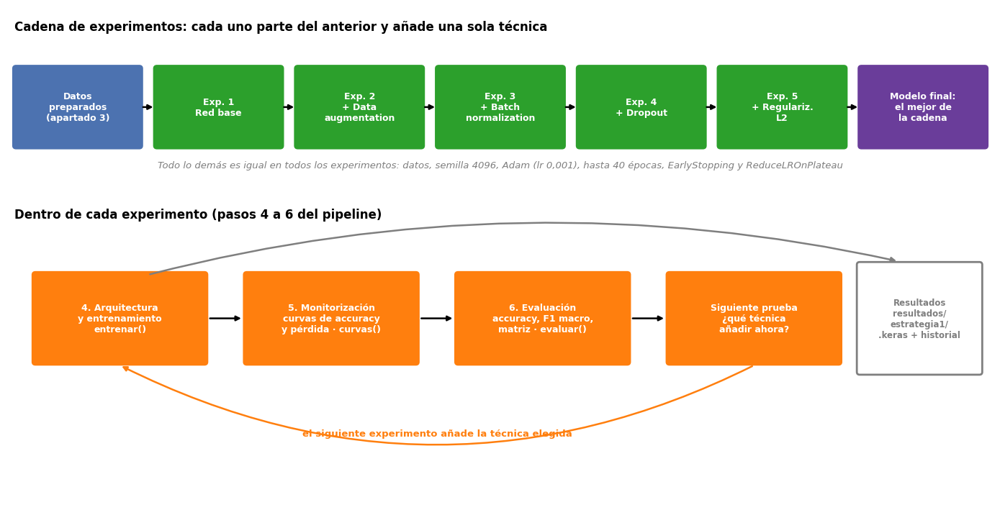

In [ ]:
# @title Diagrama: plan de la Estrategia 1
from matplotlib.patches import FancyBboxPatch

FIGURAS = BASE_FOLDER.parent / "resultados" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

def _caja(ax, x, y, texto, color, w=1.75, h=0.95, relleno=True, fs=9):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.04",
                                fc=color if relleno else "white", ec=color, lw=2))
    ax.text(x, y, texto, ha="center", va="center", fontsize=fs, weight="bold",
            color="white" if relleno else color)

def _flecha(ax, x0, y0, x1, y1, color="black", curva=0.0):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8,
                                connectionstyle=f"arc3,rad={curva}"))

AZUL, VERDE, NARANJA, MORADO, GRIS = "#4c72b0", "#2ca02c", "#ff7f0e", "#6a3d9a", "#7f7f7f"
fig, ax = plt.subplots(figsize=(14, 7.2))
ax.set_xlim(0, 14); ax.set_ylim(0, 7.4); ax.axis("off")

# Cadena de experimentos
ax.text(0.1, 7.05, "Cadena de experimentos: cada uno parte del anterior y añade una sola técnica",
        fontsize=12, weight="bold")
pasos = [("Datos\npreparados\n(apartado 3)", AZUL), ("Exp. 1\nRed base", VERDE),
         ("Exp. 2\n+ Data\naugmentation", VERDE), ("Exp. 3\n+ Batch\nnormalization", VERDE),
         ("Exp. 4\n+ Dropout", VERDE), ("Exp. 5\n+ Regulariz.\nL2", VERDE), ("Modelo final:\nel mejor de\nla cadena", MORADO)]
xs = [1.0 + i * 2.0 for i in range(len(pasos))]
for x, (texto, color) in zip(xs, pasos):
    _caja(ax, x, 5.9, texto, color, h=1.15)
for a, b in zip(xs, xs[1:]):
    _flecha(ax, a + 0.9, 5.9, b - 0.9, 5.9)
ax.text(7.0, 5.0, "Todo lo demás es igual en todos los experimentos: datos, semilla 4096, "
        "Adam (lr 0,001), hasta 40 épocas, EarlyStopping y ReduceLROnPlateau",
        ha="center", fontsize=9.5, style="italic", color=GRIS)

# Ciclo de cada experimento
ax.text(0.1, 4.25, "Dentro de cada experimento (pasos 4 a 6 del pipeline)", fontsize=12, weight="bold")
ciclo = [("4. Arquitectura\ny entrenamiento\nentrenar()", 1.6),
         ("5. Monitorización\ncurvas de accuracy\ny pérdida · curvas()", 4.6),
         ("6. Evaluación\naccuracy, F1 macro,\nmatriz · evaluar()", 7.6),
         ("Siguiente prueba\n¿qué técnica\nañadir ahora?", 10.6)]
for texto, x in ciclo:
    _caja(ax, x, 2.75, texto, NARANJA, w=2.4, h=1.3)
for (_, a), (_, b) in zip(ciclo, ciclo[1:]):
    _flecha(ax, a + 1.25, 2.75, b - 1.25, 2.75)
_flecha(ax, 10.6, 2.05, 1.6, 2.05, NARANJA, curva=-0.25)
ax.text(6.1, 1.0, "el siguiente experimento añade la técnica elegida", ha="center",
        fontsize=9.5, color=NARANJA, weight="bold")

# Resultados guardados
_caja(ax, 12.95, 2.75, "Resultados\nresultados/\nestrategia1/\n.keras + historial", GRIS, w=1.7, h=1.6,
      relleno=False, fs=8.5)
_flecha(ax, 1.6 + 0.4, 2.1 + 1.3, 12.95 - 0.3, 2.75 + 0.85, GRIS, curva=-0.12)

plt.tight_layout()
fig.savefig(FIGURAS / "estrategia1_plan_experimentos.png", dpi=150, bbox_inches="tight")
plt.show()

**Trabajo previo a este cuaderno.** Antes de escribir este cuaderno, el grupo hizo dos pruebas preliminares en cuadernos y scripts aparte. No forman parte de la entrega, pero sus resultados se citan en varios puntos para justificar decisiones o comparar resultados.

1. **Experimento individual del Exp. 4** (`Experimento_4_CNN_Dropout.ipynb`, Juan José). Se hizo en un ordenador con Windows y GPU NVIDIA, usando Keras con *backend* PyTorch (TensorFlow no aprovecha la GPU en Windows). Tuvo dos partes.
   * **La cadena de la red del grupo** (Exp. 1 a 3) entrenada con la misma semilla 4096, hasta 40 épocas y EarlyStopping con patience 5. Sus resultados se citan en los Exp. 1 y 2 para mostrar cuánto puede variar la misma red de un ordenador a otro.
   * **Un estudio del Dropout** con otra arquitectura (4 bloques convolucionales y `GlobalAveragePooling`), en el que cada configuración se entrenó con **3 semillas** distintas. De ahí sale la tasa de Dropout 0,3 del Exp. 4.
2. **Sondeo previo de learning rate y arquitectura** (unos 41 minutos en el equipo con Windows y GPU NVIDIA, con Keras sobre PyTorch y semilla 4096). Probamos 7 combinaciones de arquitectura y learning rate, hasta 20 épocas cada una. Sus resultados justifican el learning rate y la patience del protocolo, que se explica a continuación.

**Red de partida.** Todos los experimentos parten de la misma red base, con tres bloques convolucionales y, después, una capa **`Flatten`** que convierte el resultado de la última convolución en un vector para pasarlo a las capas densas que clasifican. En la **teleconferencia inicial del grupo** decidimos usar esta estructura porque es **la más habitual en una CNN sencilla y la que hemos visto en clase**, así que nos pareció un buen punto de partida para medir lo que aporta cada técnica.

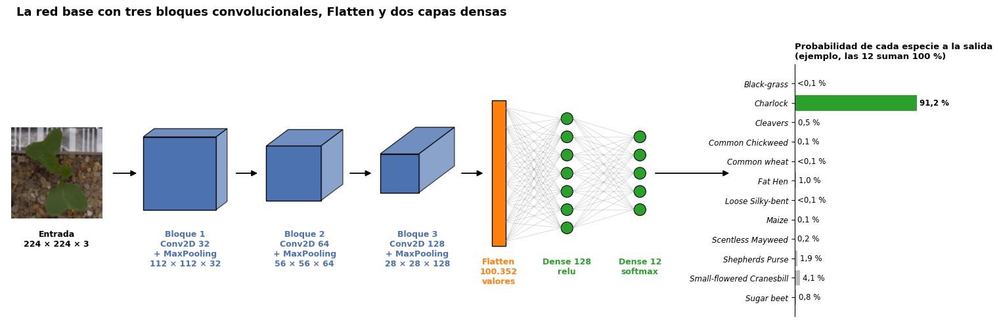

In [ ]:
# @title Diagrama de la red base, de la foto a la probabilidad de cada especie
from matplotlib.patches import Polygon, Rectangle, FancyArrowPatch
from PIL import Image

AZUL, NARANJA, VERDE, GRIS = "#4c72b0", "#ff7f0e", "#2ca02c", "#7f7f7f"


def cubo(ax, x, y, lado, fondo, color):
    # Cubo en perspectiva (alto = tamaño de la imagen, fondo = número de filtros)
    dx, dy = fondo * 0.6, fondo * 0.45
    caras = [[(x, y), (x + lado, y), (x + lado, y + lado), (x, y + lado)],
             [(x, y + lado), (x + lado, y + lado), (x + lado + dx, y + lado + dy), (x + dx, y + lado + dy)],
             [(x + lado, y), (x + lado + dx, y + dy), (x + lado + dx, y + lado + dy), (x + lado, y + lado)]]
    for cara, brillo in zip(caras, [1.0, 0.8, 0.65]):
        ax.add_patch(Polygon(cara, closed=True, facecolor=color, edgecolor="black", lw=1, alpha=brillo))


def flecha(ax, x0, x1, y=2.0):
    ax.add_patch(FancyArrowPatch((x0, y), (x1, y), arrowstyle="-|>", mutation_scale=13, color="black", lw=1.3))


fig = plt.figure(figsize=(15, 5.2))
ax = fig.add_axes([0, 0, 0.74, 0.88])
ax.set_xlim(0, 16.0)
ax.set_ylim(-1.3, 4.4)
ax.axis("off")

# Entrada con una foto real de Charlock
ruta = sorted((TRAIN_PATH / "Charlock").glob("*.png"))[0]
foto = Image.open(ruta).convert("RGB").resize((224, 224))
ax.imshow(foto, extent=(0.1, 2.1, 1.0, 3.0))
ax.text(1.1, 0.75, "Entrada\n224 × 224 × 3", ha="center", va="top", fontsize=9, fontweight="bold")
flecha(ax, 2.3, 2.9)

# Tres bloques convolucionales (Conv2D + MaxPooling), la imagen se reduce y los filtros aumentan
bloques = [(3.0, 1.6, 0.4, "Bloque 1", "Conv2D 32\n+ MaxPooling", "112 × 112 × 32"),
           (5.7, 1.2, 0.8, "Bloque 2", "Conv2D 64\n+ MaxPooling", "56 × 56 × 64"),
           (8.2, 0.85, 1.3, "Bloque 3", "Conv2D 128\n+ MaxPooling", "28 × 28 × 128")]
for x, lado, fondo, nombre, capas, forma in bloques:
    y = 2.0 - lado / 2
    cubo(ax, x, y, lado, fondo, AZUL)
    ax.text(x + (lado + fondo * 0.6) / 2, 0.75, f"{nombre}\n{capas}\n{forma}", ha="center", va="top", fontsize=9,
            color=AZUL, fontweight="bold")
flecha(ax, 5.0, 5.55)
flecha(ax, 7.5, 8.05)
flecha(ax, 9.95, 10.5)

# Flatten, el cubo se estira en un vector muy largo
ax.add_patch(Rectangle((10.65, 0.4), 0.3, 3.2, facecolor=NARANJA, edgecolor="black", lw=1))
ax.text(10.8, 0.15, "Flatten\n100.352\nvalores", ha="center", va="top", fontsize=9, color=NARANJA,
        fontweight="bold")

# Capas densas
for i in range(7):
    ax.add_patch(plt.Circle((12.3, 0.8 + i * 0.4), 0.13, facecolor=VERDE, edgecolor="black", lw=0.8))
    for j in range(8):
        ax.plot([10.95, 12.17], [0.5 + j * 0.42, 0.8 + i * 0.4], color=GRIS, lw=0.3, alpha=0.6)
ax.text(12.3, 0.15, "Dense 128\nrelu", ha="center", va="top", fontsize=9, color=VERDE, fontweight="bold")
for i in range(5):
    ax.add_patch(plt.Circle((13.9, 1.2 + i * 0.4), 0.13, facecolor=VERDE, edgecolor="black", lw=0.8))
    for j in range(7):
        ax.plot([12.43, 13.77], [0.8 + j * 0.4, 1.2 + i * 0.4], color=GRIS, lw=0.3, alpha=0.6)
ax.text(13.9, 0.15, "Dense 12\nsoftmax", ha="center", va="top", fontsize=9, color=VERDE, fontweight="bold")
flecha(ax, 14.2, 15.9)

# Salida con una probabilidad (en %) para cada especie, que suman 100 %
ejemplo = {"Charlock": 91.2, "Small-flowered Cranesbill": 4.1, "Shepherds Purse": 1.9, "Fat Hen": 1.0,
           "Sugar beet": 0.8, "Cleavers": 0.5, "Scentless Mayweed": 0.2, "Common Chickweed": 0.1,
           "Maize": 0.1, "Black-grass": 0.05, "Common wheat": 0.03, "Loose Silky-bent": 0.02}
especies = sorted(ejemplo)
valores = [ejemplo[e] for e in especies]
ax2 = fig.add_axes([0.80, 0.08, 0.17, 0.74])
colores = [VERDE if v == max(valores) else "#bbbbbb" for v in valores]
ax2.barh(especies, valores, color=colores)
ax2.invert_yaxis()
ax2.set_xlim(0, 125)
for i, v in enumerate(valores):
    texto = f"{v:.1f} %".replace(".", ",") if v >= 0.1 else "<0,1 %"
    ax2.text(v + 2, i, texto, va="center", fontsize=8.5, fontweight="bold" if v == max(valores) else None)
ax2.set_xticks([])
for lado in ["top", "right", "bottom"]:
    ax2.spines[lado].set_visible(False)
ax2.tick_params(axis="y", labelsize=8.5)
for etiqueta in ax2.get_yticklabels():
    etiqueta.set_fontstyle("italic")
ax2.set_title("Probabilidad de cada especie a la salida\n(ejemplo, las 12 suman 100 %)", fontsize=9.5,
              fontweight="bold", loc="left")

fig.suptitle("La red base con tres bloques convolucionales, Flatten y dos capas densas",
             fontsize=13, fontweight="bold", x=0.01, ha="left", y=0.99)
plt.savefig(FIGURAS / "red_base_flatten.png", dpi=150, bbox_inches="tight")
plt.show()

Después nos encontramos con sus inconvenientes. La capa densa que sigue a `Flatten` concentra casi todos los parámetros de la red (12,8 de 12,9 millones), lo que facilita el sobreajuste y hace el entrenamiento más inestable. En el sondeo previo probamos también **`GlobalAveragePooling`**, que resultó más prometedora. Con 3 bloques dio un resultado parecido (75,9 % frente a 75,6 %) con muchísimos menos parámetros (112.204 frente a 12,9 millones), y con un cuarto bloque llegó al 88,4 % en 20 épocas. Pero el trabajo ya estaba repartido entre el grupo y preferimos continuar con la red acordada.

**En retrospectiva**, la red con `Flatten` ha dado un resultado correcto (85,5 % en el Exp. 4), pero ha dependido de la ***patience* de 10 épocas**. Con *patience* 5, el entrenamiento del Exp. 3 se paraba antes de que la red se recuperara del arranque inestable que provoca BatchNorm, y habríamos tenido que buscar otras opciones, como bajar el learning rate, cambiar a `GlobalAveragePooling` o quitar BatchNorm. Aumentar la *patience* fue precisamente una de esas opciones. Con 10 épocas de margen, `ReduceLROnPlateau` tuvo tiempo de bajar el learning rate y la red se recuperó sola, sin cambiar la arquitectura acordada.

**¿Por qué BatchNorm provoca ese arranque inestable?** En parte es propio de BatchNorm y en parte de su combinación con `Flatten` y un learning rate de 0,001. Hay dos causas probables, aunque no las hemos aislado con un experimento.

* **BatchNorm se comporta distinto al entrenar y al validar.** Al entrenar, normaliza con la media y la varianza de cada lote de 32 fotos. Al validar, usa una media acumulada de los lotes anteriores, que se actualiza muy despacio (cada lote aporta solo un 1 %) y va por detrás de los pesos mientras estos cambian rápido. Por eso, en las primeras épocas, la validación se queda cerca del azar (del 11 al 17 % en el Exp. 3) aunque la red ya esté aprendiendo. Esto le pasa a cualquier red con BatchNorm. En el sondeo, también las de `GlobalAveragePooling` se quedaron en el 13 % las 3 primeras épocas.
* **Los 100.352 valores de `Flatten` llegan todos con un tamaño parecido.** BatchNorm reescala las salidas de la última convolución y ninguna queda pequeña. La capa densa suma 100.352 valores, así que calcula números enormes y la red da casi el 100 % a una sola especie aunque todavía no sepa nada. Cuando esa especie es incorrecta, la pérdida se dispara (46,6 en la primera época del Exp. 3, frente a 2,5 si respondiera al azar), y con un learning rate de 0,001 los pasos son demasiado bruscos para una capa de 12,8 millones de parámetros. Esto es lo propio de `Flatten`. En el sondeo, la pérdida de la primera época fue de 14,3 con `Flatten` y de solo 1,4 a 2,1 con `GlobalAveragePooling`.

Cuando `ReduceLROnPlateau` baja el learning rate, los pesos cambian más despacio, la media acumulada de BatchNorm los alcanza y la validación se estabiliza. Con `GlobalAveragePooling`, la capa densa solo recibe 128 valores, así que el segundo problema casi desaparece.

El siguiente gráfico muestra qué hace `Flatten` y por qué la capa densa que la sigue tiene tantos parámetros, comparada con la alternativa.

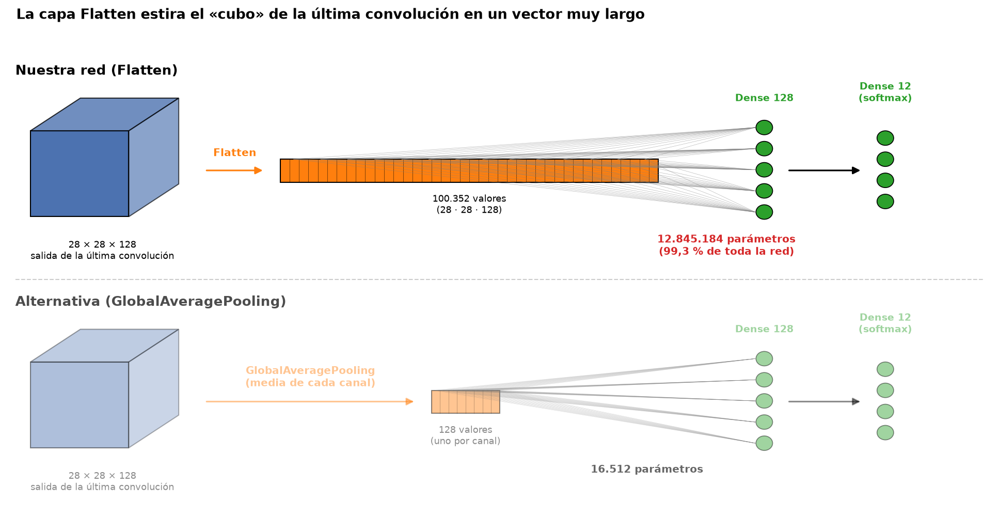

In [ ]:
# @title Diagrama de lo que hace la capa Flatten (y la alternativa GlobalAveragePooling)
from matplotlib.patches import Polygon, Rectangle, FancyArrowPatch

AZUL, NARANJA, VERDE, ROJO, GRIS = "#4c72b0", "#ff7f0e", "#2ca02c", "#d62728", "#7f7f7f"


def cubo(ax, x, y, lado, fondo, color, alpha=1):
    # Cubo en perspectiva (cara frontal, superior y lateral)
    dx, dy = fondo * 0.6, fondo * 0.45
    caras = [[(x, y), (x + lado, y), (x + lado, y + lado), (x, y + lado)],
             [(x, y + lado), (x + lado, y + lado), (x + lado + dx, y + lado + dy), (x + dx, y + lado + dy)],
             [(x + lado, y), (x + lado + dx, y + dy), (x + lado + dx, y + lado + dy), (x + lado, y + lado)]]
    for cara, brillo in zip(caras, [1.0, 0.8, 0.65]):
        ax.add_patch(Polygon(cara, closed=True, facecolor=color, edgecolor="black", lw=1,
                             alpha=alpha * brillo))


def flecha(ax, x0, x1, y, texto="", color="black", alpha=1):
    ax.add_patch(FancyArrowPatch((x0, y), (x1, y), arrowstyle="-|>", mutation_scale=14,
                                 color=color, lw=1.5, alpha=alpha))
    if texto:
        ax.text((x0 + x1) / 2, y + 0.18, texto, ha="center", va="bottom", fontsize=9.5,
                fontweight="bold", color=color, alpha=alpha)


def vector(ax, x, y, ancho, n, color, alpha=1):
    # Vector dibujado como una tira de casillas
    ax.add_patch(Rectangle((x, y), ancho, 0.35, facecolor=color, edgecolor="black", lw=1, alpha=alpha))
    for i in range(1, n):
        ax.plot([x + ancho * i / n] * 2, [y, y + 0.35], color="black", lw=0.4, alpha=alpha * 0.6)


def neuronas(ax, x, y, n, color, alpha=1):
    for i in range(n):
        ax.add_patch(plt.Circle((x, y + i * 0.32), 0.11, facecolor=color, edgecolor="black",
                                lw=0.8, alpha=alpha))


fig, ax = plt.subplots(figsize=(13, 6.6))
ax.set_xlim(0, 13)
ax.set_ylim(-0.4, 6.6)
ax.axis("off")

filas = [  # (y, título, alpha, operación, n.º de valores, ancho del vector, parámetros de la Dense)
    (4.0, "Nuestra red (Flatten)", 1.0, "Flatten", "100.352 valores\n(28 · 28 · 128)", 5.0,
     "12.845.184 parámetros\n(99,3 % de toda la red)"),
    (0.5, "Alternativa (GlobalAveragePooling)", 0.45, "GlobalAveragePooling\n(media de cada canal)",
     "128 valores\n(uno por canal)", 0.9, "16.512 parámetros"),
]
for y, titulo, a, operacion, valores, ancho, params in filas:
    ax.text(0.1, y + 2.15, titulo, fontsize=12.5, fontweight="bold", alpha=max(a, 0.7))
    cubo(ax, 0.3, y, 1.3, 1.1, AZUL, a)
    ax.text(1.25, y - 0.35, "28 × 28 × 128\nsalida de la última convolución", ha="center", va="top",
            fontsize=8.5, alpha=a)
    x_vec = 3.6 if ancho > 1 else 5.6
    flecha(ax, 2.6, x_vec - 0.2, y + 0.7, operacion, NARANJA, a)
    vector(ax, x_vec, y + 0.52, ancho, 40 if ancho > 1 else 8, NARANJA, a)
    ax.text(x_vec + ancho / 2, y + 0.35, valores, ha="center", va="top", fontsize=8.5, alpha=a)
    # Conexiones de todos los valores con la capa densa
    x_densa = 10.0
    for i in range(14):
        xi = x_vec + ancho * (i + 0.5) / 14
        for j in range(5):
            ax.plot([xi, x_densa - 0.12], [y + 0.87, y + 0.07 + j * 0.32], color=GRIS, lw=0.3,
                    alpha=a * 0.6)
    neuronas(ax, x_densa, y + 0.07, 5, VERDE, a)
    ax.text(x_densa, y + 1.75, "Dense 128", ha="center", fontsize=9, fontweight="bold", color=VERDE, alpha=a)
    ax.text((x_vec + ancho + x_densa) / 2 + 0.2, y - 0.25, params, ha="center", va="top", fontsize=9.5,
            fontweight="bold", color=ROJO if a == 1 else "black", alpha=max(a, 0.6))
    flecha(ax, x_densa + 0.3, x_densa + 1.3, y + 0.7, alpha=a)
    neuronas(ax, x_densa + 1.6, y + 0.23, 4, VERDE, a)
    ax.text(x_densa + 1.6, y + 1.75, "Dense 12\n(softmax)", ha="center", fontsize=9, fontweight="bold",
            color=VERDE, alpha=a)

ax.plot([0.1, 12.9], [3.05, 3.05], color="#cccccc", lw=1, ls="--")
fig.suptitle("La capa Flatten estira el «cubo» de la última convolución en un vector muy largo",
             fontsize=13, fontweight="bold", x=0.02, ha="left", y=1.0)
plt.tight_layout()
plt.savefig(FIGURAS / "flatten_frente_a_gap.png", dpi=150, bbox_inches="tight")
plt.show()

**Protocolo común de entrenamiento.** Para que los experimentos se puedan comparar, todos se entrenan igual; solo cambia lo que añade cada experimento. A continuación se explica cada elección.

**Optimizador Adam con learning rate 0,001.** El optimizador es el algoritmo que, después de cada lote de imágenes, ajusta los pesos de la red para reducir el error. **Adam** (*Adaptive Moment Estimation*) combina dos ideas, el *momento* (sigue la dirección en la que venía bajando el error, como una bola que coge inercia) y un **learning rate adaptativo para cada peso** (los pesos con gradientes grandes o muy variables dan pasos más pequeños, y los de gradientes pequeños, más grandes). Por eso funciona bien sin apenas ajustes y es el optimizador más usado para entrenar CNN.

* El **learning rate** es el tamaño de cada paso. Si es demasiado grande, la red da saltos y no converge; si es demasiado pequeño, aprende muy despacio y necesita muchísimas épocas. Usamos **0,001, el valor por defecto de Adam** en Keras y el recomendado por sus autores.
* **Otras opciones.** SGD con momento (más simple, a veces generaliza algo mejor pero exige ajustar más el learning rate), RMSprop (adaptativo, sin momento), AdamW (Adam con *weight decay* aplicado aparte del gradiente, que en Adam funciona mejor que añadir L2 a la pérdida) o Nadam (Adam con momento de Nesterov).

**¿Es 0,001 un buen valor?** Para comprobarlo, hicimos un **sondeo previo de unos 41 minutos** con la semilla 4096. Entrenamos 7 combinaciones de arquitectura y learning rate (0,001, 0,0003 y 0,0001) durante un máximo de 20 épocas, todas con data augmentation, BatchNorm y una *patience* de 5 épocas.

| Red | lr 0,001 | lr 0,0001 |
|---|---|---|
| GlobalAveragePooling, 3 bloques | **75,9 %** | 72,3 % |
| GlobalAveragePooling, 4 bloques | **88,4 %** | 81,5 % (seguía mejorando en la época 20) |
| Red del grupo (Flatten) | 10,0 % (se paró en la época 6) | **75,6 %** |

Con las redes de GlobalAveragePooling, **0,001 fue el mejor valor**, porque un learning rate 10 veces menor aprendía más despacio y acababa por debajo. Por eso mantenemos 0,001. La excepción parecía la red del grupo, que con BatchNorm y 0,001 se quedó en el 10 %. Pero no era un colapso real. Con *patience* 5, el entrenamiento se paró en la época 6, cuando la red aún no se había recuperado del arranque inestable (su mejor época fue la 1). En el Exp. 3, con *patience* 10, la misma red llega al 73,5 %.

**Pérdida *sparse categorical cross-entropy*.** La pérdida mide cuánto se equivoca la red y es lo que el optimizador intenta reducir. La **entropía cruzada** es la pérdida estándar en clasificación con varias clases. Compara la probabilidad que la red da a la especie correcta con el 100 % y **castiga mucho equivocarse con seguridad**. Va emparejada con la salida *softmax*, que da una probabilidad para cada una de las 12 especies.

* Es ***sparse*** porque nuestras etiquetas son números enteros del 0 al 11 (`label_mode="int"` en el apartado 3.1).
* **Otras opciones.** *categorical cross-entropy* (la misma pérdida, pero con las etiquetas en formato *one-hot*, es decir, un vector de 12 ceros con un 1 en la especie correcta) o la *focal loss*, que da más peso a los ejemplos difíciles y se usa con datasets muy desbalanceados. El error cuadrático medio (MSE) no es adecuado para clasificación.

**Hasta 40 épocas.** Una época es una pasada completa por las 3.800 imágenes de entrenamiento. 40 es un **límite máximo**, no el número de épocas que se entrena, porque EarlyStopping suele parar antes (el Exp. 1 paró en la época 15). Damos margen porque los experimentos con data augmentation aprenden más despacio (cada época ven imágenes distintas) y necesitan más épocas. Al mismo tiempo, el límite evita entrenamientos interminables, y con 6 a 11 s por época en nuestros equipos (más con BatchNorm), un experimento dura como mucho unos 7 minutos.

**EarlyStopping (`patience=10`, `restore_best_weights=True`).** Después de cada época se mira la **pérdida de validación**, de la siguiente forma.

1. Si es la más baja hasta el momento, se guarda esa época como la mejor y el contador vuelve a 0.
2. Si no mejora, el contador suma 1.
3. Si el contador llega a **10**, se para el entrenamiento y se recuperan **los pesos de la mejor época**.

Sirve para parar cuando empieza el sobreajuste (la validación empeora mientras el entrenamiento sigue mejorando) y es una técnica de regularización en sí misma. Elegimos **10** en lugar de 5 porque, con data augmentation y BatchNorm, la pérdida de validación oscila mucho. En los entrenamientos del trabajo previo (el experimento individual del Exp. 4 y el sondeo), 42 rachas de 3 o 4 épocas sin mejorar acabaron en una nueva mejora, y con patience 5 dos entrenamientos se cortaron cuando la red todavía estaba aprendiendo. Esperar más no tiene riesgo, porque gracias a `restore_best_weights=True`, siempre nos quedamos con la mejor época.

**ReduceLROnPlateau (`factor=0.5`, `patience=3`).** Si la pérdida de validación no mejora en **3 épocas seguidas**, el learning rate se **multiplica por 0,5** (se divide entre 2), es decir, 0,001 → 0,0005 → 0,00025… Cuando la red se estanca u oscila, suele ser porque los pasos son demasiado grandes para afinar más; con pasos más pequeños puede seguir mejorando.

* **`factor=0.5`** es una reducción moderada; un factor de 0,1 (dividir entre 10) sería más brusco y podría frenar el aprendizaje de golpe.
* **`patience=3`** es menor que la de EarlyStopping (10) a propósito, para que el learning rate tiene tiempo de bajar 2 o 3 veces antes de que se pare el entrenamiento.

**Cómo se escribe en código.** Es lo que hace la función `entrenar()` de la celda siguiente.

```python
modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

historial = modelo.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks)
modelo.save("resultados/estrategia1/exp1_red_base.keras")
```

**Directorios de entrada y de salida.**

* **Entrada.** Las imágenes se leen de `plant-seedlings/train/` (una carpeta por especie), que se localiza con `BASE_FOLDER` en el apartado 1 y se carga con `image_dataset_from_directory` en el apartado 3.
* **Salida.** Cada modelo entrenado se guarda en `resultados/estrategia1/`, en la raíz del proyecto, con dos ficheros.
  * `<nombre>.keras` es el modelo completo (arquitectura, pesos y estado del optimizador). Se vuelve a cargar con `keras.models.load_model(...)`.
  * `<nombre>_historial.json` guarda la accuracy, la pérdida y el learning rate de cada época, para poder dibujar las curvas sin reentrenar.
* Si el cuaderno se vuelve a ejecutar y esos ficheros ya existen, `entrenar()` **los carga en lugar de entrenar de nuevo** y muestra el registro del entrenamiento original. Para reentrenar un modelo, se llama con `reentrenar=True` o se borra su fichero. Para compartir un modelo con un compañero basta con copiarle los dos ficheros en la misma carpeta.

In [ ]:
import json, time, warnings

warnings.filterwarnings("ignore", message=".*shuffle=True.*")   # aviso inofensivo de Keras con tf.data

RESULTADOS = BASE_FOLDER.parent / "resultados" / "estrategia1"
RESULTADOS.mkdir(parents=True, exist_ok=True)
MAX_EPOCAS = 40
LR = 1e-3


class Historial:
    # Misma estructura que el objeto History de Keras (para cargar historiales guardados)
    def __init__(self, history):
        self.history = history


def mostrar_registro(h):
    # Registro época a época: evidencia del entrenamiento
    tabla = pd.DataFrame({"accuracy": h["accuracy"], "val_accuracy": h["val_accuracy"],
                          "loss": h["loss"], "val_loss": h["val_loss"], "learning_rate": h["learning_rate"]})
    tabla.index = range(1, len(tabla) + 1)
    tabla.index.name = "época"
    columnas = ["accuracy", "val_accuracy", "loss", "val_loss"]
    print(tabla.round({c: 4 for c in columnas}).to_string(formatters={"learning_rate": "{:.2e}".format}))   # lr sin redondear


def entrenar(modelo, nombre, datos_train=None, datos_val=None, reentrenar=False,
             lr=None, max_epocas=None, carpeta=None):
    """Entrena con el protocolo común y guarda el modelo; si ya existe, lo carga.
    lr, max_epocas y carpeta solo cambian en el fine-tuning de la Estrategia 2."""
    lr = LR if lr is None else lr
    max_epocas = MAX_EPOCAS if max_epocas is None else max_epocas
    carpeta = RESULTADOS if carpeta is None else carpeta
    datos_train = train_ds if datos_train is None else datos_train
    datos_val = val_ds if datos_val is None else datos_val
    ruta_modelo, ruta_hist = carpeta / f"{nombre}.keras", carpeta / f"{nombre}_historial.json"

    if ruta_modelo.exists() and ruta_hist.exists() and not reentrenar:
        historial = Historial(json.loads(ruta_hist.read_text()))
        print(f"Modelo ya entrenado: se carga {ruta_modelo.name}. Registro del entrenamiento original:")
        mostrar_registro(historial.history)
        return keras.models.load_model(ruta_modelo), historial

    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ]
    keras.utils.set_random_seed(SEED)
    inicio = time.time()
    historial = modelo.fit(datos_train, validation_data=datos_val, epochs=max_epocas,
                           callbacks=callbacks, verbose=2)
    print(f"Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min")

    h = {k: [float(v) for v in vals] for k, vals in historial.history.items()}
    modelo.save(ruta_modelo)
    ruta_hist.write_text(json.dumps(h))
    return modelo, Historial(h)

### 4.1 Experimento 1, red base

**Responsable.** Alfredo

#### Arquitectura y entrenamiento

La arquitectura de la **red base** tiene la estructura clásica de una CNN, con la capa `Flatten` de la que hablamos al principio del apartado 4, y **no lleva ninguna técnica de regularización**. Sus capas son estas.

* **3 bloques convolucionales** con 32, 64 y 128 filtros de 3 × 3. Cada bloque detecta patrones (bordes y manchas de color en el primero, formas más complejas en los siguientes) y termina con un `MaxPooling2D` que reduce la imagen a la mitad (224 → 112 → 56 → 28 píxeles).
* **`Flatten`** convierte el mapa final de 28 × 28 × 128 en un vector de 100.352 valores.
* Una capa **densa de 128 neuronas** (ReLU) y la **capa de salida de 12 neuronas** (softmax), que da una probabilidad para cada especie.

**Para qué sirve el `MaxPooling2D` de 2 × 2.** Divide la imagen en cuadritos de 2 × 2 píxeles y de cada uno se queda solo con el valor más alto, así que la imagen pasa a tener la mitad de ancho y la mitad de alto. Tiene tres ventajas.

* **Reduce el tamaño y el cálculo.** Cada `MaxPooling2D` deja la imagen con 4 veces menos píxeles. Sin los tres, a `Flatten` le llegarían 224 × 224 × 128 = 6,4 millones de valores en lugar de 100.352, y la capa densa tendría unos 820 millones de parámetros.
* **Cada filtro abarca más trozo de la foto.** Después de cada reducción, un filtro de 3 × 3 cubre una zona más grande de la imagen original. En el primer bloque los filtros ven bordes y manchas, y en el tercero ya ven partes de la hoja o la planta entera.
* **Tolera pequeños desplazamientos.** Como se queda con el máximo de cada cuadrito, da igual que un borde esté en un píxel o en el de al lado, así que una hoja un poco movida se reconoce igual.

Se queda con el máximo y no con la media porque el valor más alto indica dónde ha encontrado un filtro su patrón con más fuerza. Lo que importa es si el patrón está en esa zona, no su posición exacta.

Se entrena con las imágenes normalizadas entre 0 y 1 (`train_ds`), **sin data augmentation**.

In [ ]:
keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en cada ejecución

exp1 = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="exp1_red_base")

exp1.summary()

Model: "exp1_red_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,980 (49.36 MB)

 Trainable params: 12,939,980 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

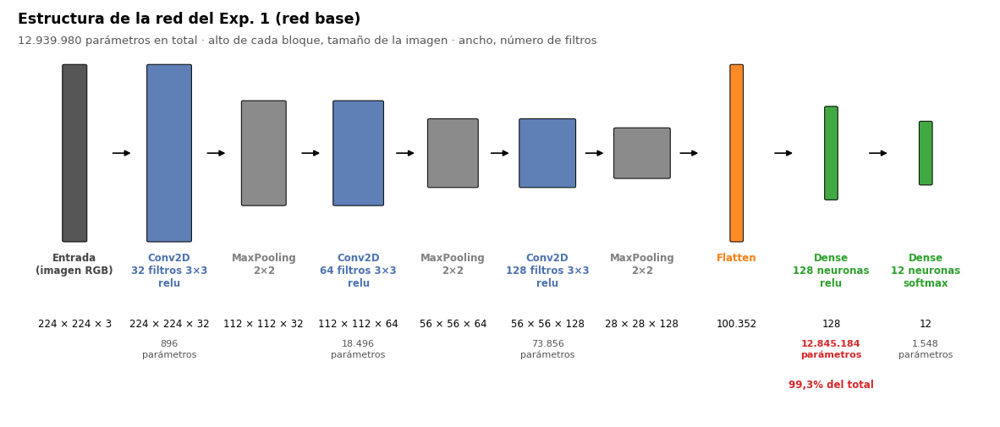

In [ ]:
# @title Diagrama: estructura de la red del Exp. 1
from matplotlib.patches import FancyBboxPatch

FIGURAS = BASE_FOLDER.parent / "resultados" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

COLORES_CAPA = {"Conv2D": "#4c72b0", "MaxPooling2D": "#7f7f7f", "Flatten": "#ff7f0e",
                "GlobalAveragePooling2D": "#ff7f0e", "Dense": "#2ca02c", "BatchNormalization": "#8c564b",
                "Dropout": "#d62728", "Sequential": "#17becf", "Entrada": "#444444",
                "RandomFlip": "#9467bd", "RandomRotation": "#9467bd", "RandomZoom": "#9467bd",
                "RandomTranslation": "#9467bd", "Activation": "#bcbd22"}


def _amplitud(factor):
    # Las capas de augmentation guardan el rango como número (0.15) o como intervalo (-0.15, 0.15)
    return max(abs(f) for f in factor) if isinstance(factor, (tuple, list)) else abs(factor)


def _etiqueta(capa):
    # Nombre corto de cada capa; las capas con regularización L2 lo indican al final
    texto = _etiqueta_base(capa)
    regularizador = getattr(capa, "kernel_regularizer", None)
    if regularizador is not None and hasattr(regularizador, "l2"):
        texto += f"\n+ L2 ({float(regularizador.l2):g})".replace(".", ",")
    return texto


def _etiqueta_base(capa):
    # Nombre corto de cada capa para el diagrama
    tipo = type(capa).__name__
    activacion = getattr(getattr(capa, "activation", None), "__name__", "")
    if tipo == "Conv2D":
        activacion = "sin activación" if activacion == "linear" else activacion
        return f"Conv2D\n{capa.filters} filtros {capa.kernel_size[0]}×{capa.kernel_size[1]}\n{activacion}"
    if tipo == "MaxPooling2D":
        return f"MaxPooling\n{capa.pool_size[0]}×{capa.pool_size[1]}"
    if tipo == "Dense":
        return f"Dense\n{capa.units} neuronas\n{activacion}"
    if tipo == "RandomFlip":
        return f"Random\nFlip\n{capa.mode}"
    if tipo == "RandomRotation":
        return f"Random\nRotation\n±{_amplitud(capa.factor) * 360:.0f}°"
    if tipo == "RandomZoom":
        return f"Random\nZoom\n±{_amplitud(capa.height_factor):.0%}"
    if tipo == "RandomTranslation":
        return f"Random\nTranslation\n±{_amplitud(capa.height_factor):.0%}"
    if tipo == "BatchNormalization":
        return "Batch\nNorm"
    if tipo == "Dropout":
        return f"Dropout\n{capa.rate:g}".replace(".", ",")
    if tipo == "Activation":
        return activacion
    if tipo == "Sequential":
        return capa.name.replace("_", " ")
    return tipo


def dibujar_red(modelo, titulo, archivo, max_por_fila=12):
    """Dibuja las capas del modelo: alto = tamaño de la imagen, ancho = n.º de filtros.
    Si hay más de max_por_fila capas, las reparte en dos filas para que no salgan diminutas."""
    total = modelo.count_params()
    elementos = [("Entrada", "Entrada\n(imagen RGB)", tuple(modelo.input_shape), 0)]
    elementos += [(type(c).__name__, _etiqueta(c), tuple(c.output.shape), c.count_params())
                  for c in modelo.layers]
    n = len(elementos)
    filas = 1 if n <= max_por_fila else 2
    por_fila = int(np.ceil(n / filas))
    ALTO_FILA = 7.0                                  # separación vertical entre filas
    fig, ax = plt.subplots(figsize=(1.5 * por_fila, 6.3 + (filas - 1) * 6.0))
    ax.set_xlim(-0.7, por_fila - 0.3); ax.set_ylim(-2.8 - (filas - 1) * ALTO_FILA, 4.0); ax.axis("off")

    lado_max = max(s[1] for _, _, s, _ in elementos if len(s) == 4)
    for k, (tipo, etiqueta, forma, params) in enumerate(elementos):
        i, y0 = k % por_fila, -(k // por_fila) * ALTO_FILA   # columna y desplazamiento de la fila
        if len(forma) == 4:   # mapa de características: alto ∝ tamaño, ancho ∝ log(filtros)
            alto = 0.5 + 2.4 * forma[1] / lado_max
            ancho = 0.12 + 0.5 * np.log2(forma[3]) / 8
        else:                 # vector: barra fina, más alta cuantos más valores
            alto = 0.5 + 2.4 * min(1.0, np.log10(forma[1]) / np.log10(100_000))
            ancho = 0.1
        color = COLORES_CAPA.get(tipo, "#999999")
        ax.add_patch(FancyBboxPatch((i - ancho / 2, y0 + 1.6 - alto / 2), ancho, alto, boxstyle="round,pad=0.02",
                                    fc=color, ec="black", lw=0.8, alpha=0.9))
        if k < n - 1 and i < por_fila - 1:          # flecha a la capa siguiente de la misma fila
            ax.annotate("", xy=(i + 0.62, y0 + 1.6), xytext=(i + 0.38, y0 + 1.6),
                        arrowprops=dict(arrowstyle="-|>", color="black", lw=1.2))
        elif k < n - 1:                              # fin de fila: la flecha baja a la fila siguiente
            y_medio = y0 - 3.3
            ax.plot([i + 0.38, i + 0.62, i + 0.62, -0.55, -0.55], [y0 + 1.6, y0 + 1.6, y_medio, y_medio, y0 - ALTO_FILA + 1.6],
                    color="#999999", lw=1.2)
            ax.annotate("", xy=(-0.38, y0 - ALTO_FILA + 1.6), xytext=(-0.55, y0 - ALTO_FILA + 1.6),
                        arrowprops=dict(arrowstyle="-|>", color="#999999", lw=1.2))

        dimension = " × ".join(f"{d:,}".replace(",", ".") for d in forma[1:])
        ax.text(i, y0 - 0.05, etiqueta, ha="center", va="top", fontsize=8.5, weight="bold", color=color)
        ax.text(i, y0 - 1.15, dimension, ha="center", va="top", fontsize=8.5)
        if params:
            porcentaje = params / total
            destacado = porcentaje > 0.5
            ax.text(i, y0 - 1.5, f"{params:,}".replace(",", ".") + "\nparámetros", ha="center", va="top",
                    fontsize=8, color="#d62728" if destacado else "#555555", weight="bold" if destacado else None)
            if destacado:
                ax.text(i, y0 - 2.15, f"{porcentaje:.1%} del total".replace(".", ","), ha="center", va="top",
                        fontsize=8.5, color="#d62728", weight="bold")

    ax.text(-0.6, 3.95, titulo, fontsize=12.5, weight="bold", va="top")
    ax.text(-0.6, 3.55, f"{total:,} parámetros en total".replace(",", ".") +
            " · alto de cada bloque, tamaño de la imagen · ancho, número de filtros",
            fontsize=9.5, color="#555555", va="top")
    fig.savefig(FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()

dibujar_red(exp1, "Estructura de la red del Exp. 1 (red base)", "exp1_estructura_red.png")

La red tiene **12,9 millones de parámetros**, y casi todos (12,8 millones) están en la capa densa que sigue a `Flatten`, porque cada uno de los 100.352 valores se conecta con cada una de las 128 neuronas. Las capas convolucionales, en cambio, apenas tienen 93.000, porque cada filtro se reutiliza en toda la imagen. Una red con tantos parámetros y solo 3.800 imágenes de entrenamiento tiene mucho riesgo de **memorizar** las fotos en lugar de aprender a distinguir especies.

**De dónde salen los 12,8 millones.** Aquí queremos matizar esa cifra, porque es la clave de esta red. En el diagrama anterior, la capa densa aparece como "Dense, 128 neuronas, relu", con "128" debajo y "12.845.184 parámetros" en rojo. Cada dato significa una cosa.

* **Dense, 128 neuronas, relu.** Es una capa densa, es decir, totalmente conectada, con 128 neuronas y ReLU como función de activación.
* **128.** Es lo que sale de la capa, un vector de 128 números, uno por neurona. Es como el "28 × 28 × 128" de las capas anteriores, pero aquí ya es una lista plana.
* **12.845.184 parámetros.** Son los números que la red aprende en esta capa. Le llegan los 100.352 valores de `Flatten`, y "densa" significa que cada neurona está conectada con cada uno de ellos, con un peso propio para cada conexión. Eso da 100.352 × 128 = 12.845.056 pesos, más 128 sesgos (un número extra por neurona), en total 12.845.184.
* **99,3 % del total.** De los 12,9 millones de parámetros de la red, el 99,3 % están en esta capa. Las tres convoluciones juntas solo tienen 93.248.

Por eso esta capa sale en rojo. Es la que hace que la red sea tan grande y la que más facilita el sobreajuste. Con `GlobalAveragePooling` solo le llegarían 128 valores en lugar de 100.352, y tendría 16.512 parámetros.

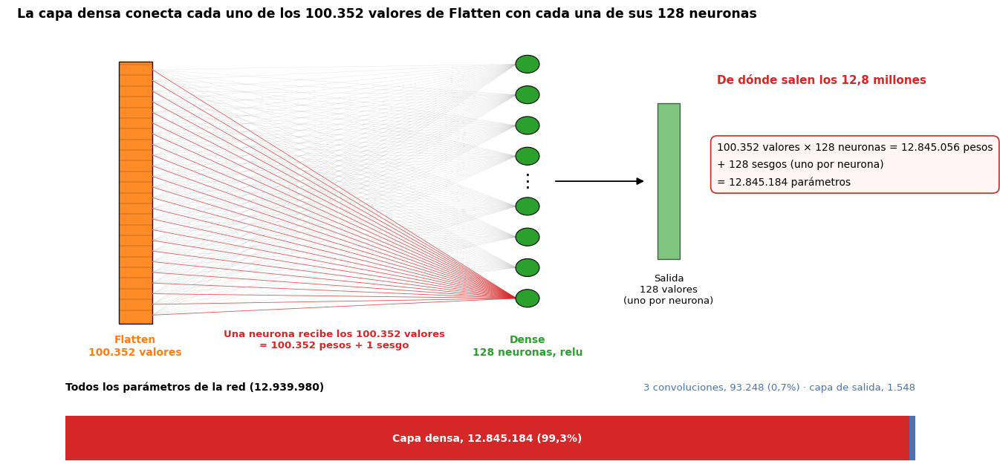

In [ ]:
# @title Diagrama de los parámetros de la capa densa que sigue a Flatten
from matplotlib.patches import Rectangle, FancyArrowPatch

NARANJA, VERDE, ROJO, AZUL, GRIS = "#ff7f0e", "#2ca02c", "#d62728", "#4c72b0", "#bbbbbb"
N_ENTRADA, N_NEURONAS = 100_352, 128
PESOS = N_ENTRADA * N_NEURONAS
PARAMS_DENSA = PESOS + N_NEURONAS
PARAMS_CONV, PARAMS_SALIDA = 896 + 18_496 + 73_856, 128 * 12 + 12
TOTAL = PARAMS_DENSA + PARAMS_CONV + PARAMS_SALIDA
miles = lambda n: f"{n:,}".replace(",", ".")
pct = lambda x: f"{x:.1%}".replace(".", ",")

fig = plt.figure(figsize=(13, 6.6))
ax = fig.add_axes([0, 0.27, 1, 0.66])
ax.set_xlim(0, 13); ax.set_ylim(-0.6, 5.2); ax.axis("off")

# Flatten, el vector de 100.352 valores (se dibujan 24 casillas y "…")
y_vals = np.linspace(0.2, 4.6, 24)
ax.add_patch(Rectangle((1.5, 0.05), 0.45, 4.7, facecolor=NARANJA, edgecolor="black", lw=1, alpha=0.9))
for y in y_vals:
    ax.plot([1.5, 1.95], [y + 0.09, y + 0.09], color="black", lw=0.3, alpha=0.5)
ax.text(1.72, -0.15, "Flatten\n" + miles(N_ENTRADA) + " valores", ha="center", va="top", fontsize=10,
        color=NARANJA, weight="bold")

# Las 128 neuronas de la capa densa (se dibujan 8 y "…")
y_neur = [0.5, 1.05, 1.6, 2.15, 3.05, 3.6, 4.15, 4.7]
for j, yn in enumerate(y_neur):
    resaltada = j == 0
    for y in y_vals:
        ax.plot([1.95, 6.85], [y, yn], color=ROJO if resaltada else GRIS, lw=0.6 if resaltada else 0.25,
                alpha=0.8 if resaltada else 0.5, zorder=1)
    ax.add_patch(plt.Circle((7.0, yn), 0.16, facecolor=VERDE, edgecolor="black", lw=0.8, zorder=3))
ax.text(7.0, 2.6, "⋮", ha="center", va="center", fontsize=18)
ax.text(7.0, -0.15, f"Dense\n{N_NEURONAS} neuronas, relu", ha="center", va="top", fontsize=10,
        color=VERDE, weight="bold")
ax.text(4.4, -0.05, f"Una neurona recibe los {miles(N_ENTRADA)} valores\n= {miles(N_ENTRADA)} pesos + 1 sesgo",
        ha="center", va="top", fontsize=9.5, color=ROJO, weight="bold")

# Salida, un vector de 128 valores
ax.add_patch(FancyArrowPatch((7.35, 2.6), (8.6, 2.6), arrowstyle="-|>", mutation_scale=14, color="black", lw=1.3))
ax.add_patch(Rectangle((8.75, 1.2), 0.3, 2.8, facecolor=VERDE, edgecolor="black", lw=1, alpha=0.6))
ax.text(8.9, 0.95, f"Salida\n{N_NEURONAS} valores\n(uno por neurona)", ha="center", va="top", fontsize=9.5)

# Cuenta de los parámetros
cuenta = (f"{miles(N_ENTRADA)} valores × {N_NEURONAS} neuronas = {miles(PESOS)} pesos\n"
          f"+ {N_NEURONAS} sesgos (uno por neurona)\n"
          f"= {miles(PARAMS_DENSA)} parámetros")
ax.text(9.55, 2.9, cuenta, ha="left", va="center", fontsize=10, linespacing=1.8,
        bbox=dict(boxstyle="round,pad=0.6", fc="#fff5f5", ec=ROJO, lw=1.2))
ax.text(9.55, 4.35, "De dónde salen los 12,8 millones", ha="left", fontsize=11, weight="bold", color=ROJO)

# Reparto de todos los parámetros de la red
ax2 = fig.add_axes([0.06, 0.06, 0.88, 0.1])
partes = [("Capa densa de 128 neuronas", PARAMS_DENSA, ROJO),
          ("3 convoluciones", PARAMS_CONV, AZUL), ("Capa de salida", PARAMS_SALIDA, VERDE)]
izquierda = 0
for nombre, n, color in partes:
    ax2.barh(0, n, left=izquierda, color=color, height=0.6)
    izquierda += n
ax2.set_xlim(0, TOTAL); ax2.axis("off")
ax2.text(PARAMS_DENSA / 2, 0, f"Capa densa, {miles(PARAMS_DENSA)} ({pct(PARAMS_DENSA / TOTAL)})", ha="center", va="center", color="white", weight="bold", fontsize=10)
ax2.text(TOTAL, 0.62, f"3 convoluciones, {miles(PARAMS_CONV)} ({pct(PARAMS_CONV / TOTAL)}) · capa de salida, {miles(PARAMS_SALIDA)}",
         ha="right", va="bottom", fontsize=9.5, color=AZUL)
ax2.text(0, 0.62, f"Todos los parámetros de la red ({miles(TOTAL)})", ha="left", va="bottom", fontsize=10, weight="bold")

fig.suptitle("La capa densa conecta cada uno de los 100.352 valores de Flatten con cada una de sus 128 neuronas",
             fontsize=12.5, weight="bold", x=0.01, ha="left", y=0.99)
plt.savefig(FIGURAS / "parametros_capa_densa.png", dpi=150, bbox_inches="tight")
plt.show()

**Modelo ya entrenado.** El modelo de este experimento (`exp1_red_base.keras`, 155 MB) es demasiado grande para GitHub, así que está disponible en [Google Drive](https://drive.google.com/file/d/19nuHnqJd8rn0ru6pH3ZOLwvEaN6AgFg3/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia1/` junto a su historial (`exp1_red_base_historial.json`), y la función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, la red se entrena de nuevo (en un Mac M4 Pro tarda unos 2 minutos).

In [ ]:
exp1, hist1 = entrenar(exp1, "exp1_red_base")

Epoch 1/40
119/119 - 488s - 4s/step - accuracy: 0.2192 - loss: 2.3631 - val_accuracy: 0.3842 - val_loss: 1.7998 - learning_rate: 0.0010
Epoch 2/40
119/119 - 483s - 4s/step - accuracy: 0.4739 - loss: 1.5063 - val_accuracy: 0.5179 - val_loss: 1.3379 - learning_rate: 0.0010
Epoch 3/40
119/119 - 462s - 4s/step - accuracy: 0.6103 - loss: 1.1380 - val_accuracy: 0.6263 - val_loss: 1.1004 - learning_rate: 0.0010
Epoch 4/40
119/119 - 471s - 4s/step - accuracy: 0.6918 - loss: 0.8845 - val_accuracy: 0.6537 - val_loss: 1.0315 - learning_rate: 0.0010
Epoch 5/40
119/119 - 471s - 4s/step - accuracy: 0.7761 - loss: 0.6771 - val_accuracy: 0.6937 - val_loss: 0.9444 - learning_rate: 0.0010
Epoch 6/40
119/119 - 479s - 4s/step - accuracy: 0.8263 - loss: 0.5183 - val_accuracy: 0.7295 - val_loss: 0.8692 - learning_rate: 0.0010
Epoch 7/40
119/119 - 459s - 4s/step - accuracy: 0.8789 - loss: 0.3730 - val_accuracy: 0.7189 - val_loss: 0.9825 - learning_rate: 0.0010
Epoch 8/40
119/119 - 463s - 4s/step - accuracy: 

#### Monitorización del entrenamiento

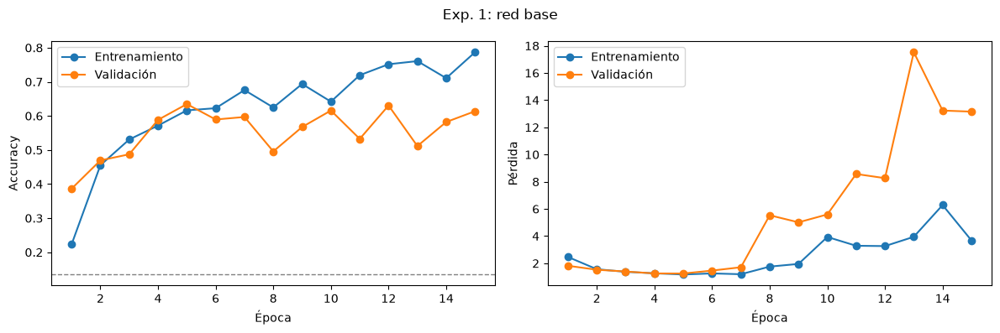

In [ ]:
curvas(hist1, "Exp. 1: red base")

**Accuracy y learning rate, época a época.** En todos los experimentos mostramos también cómo cambia el learning rate durante el entrenamiento, porque ayuda a entender las curvas. Las líneas de puntos marcan cada vez que ReduceLROnPlateau lo divide entre 2.

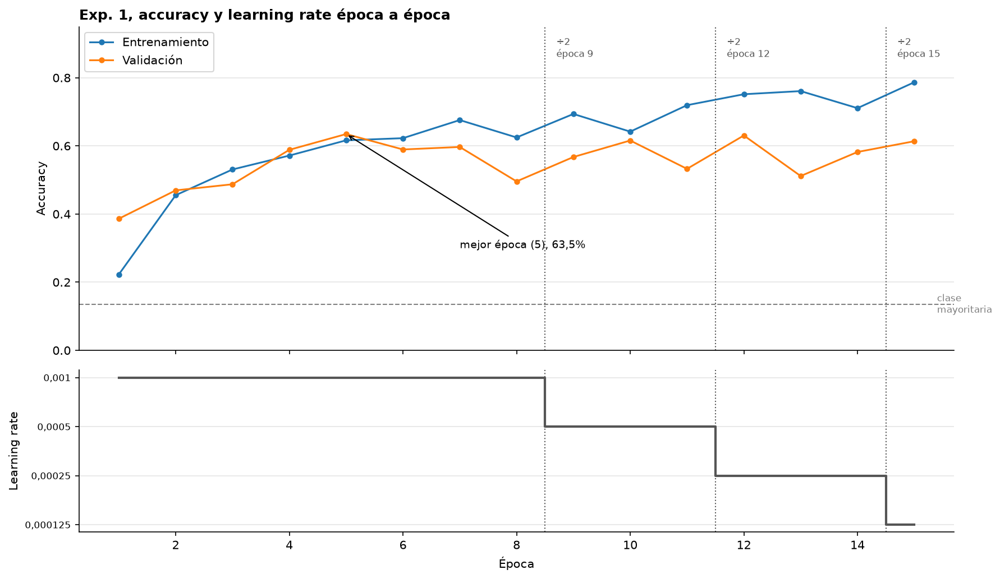

In [ ]:
# @title Gráfico de la accuracy y el learning rate del Exp. 1, época a época
def grafico_lr(historial, titulo, archivo):
    """Accuracy de entrenamiento y validación (arriba) y learning rate (abajo), con una línea en cada bajada."""
    h = historial.history
    epocas = np.arange(1, len(h["loss"]) + 1)
    lr = np.array(h["learning_rate"])
    bajadas = [e for e in epocas[1:] if lr[e - 1] < lr[e - 2]]            # épocas en que el lr se divide entre 2
    mejor = int(np.argmin(h["val_loss"])) + 1

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

    # Arriba, accuracy de entrenamiento y validación
    ax1.plot(epocas, h["accuracy"], marker="o", ms=4, label="Entrenamiento")
    ax1.plot(epocas, h["val_accuracy"], marker="o", ms=4, label="Validación")
    ax1.axhline(REF_MAYORITARIA, color="gray", ls="--", lw=1)
    ax1.text(epocas[-1] + 0.4, REF_MAYORITARIA, "clase\nmayoritaria", color="gray", fontsize=8, va="center")
    x_texto = mejor + 2 if mejor < len(epocas) / 2 else mejor - 12
    ax1.annotate(f"mejor época ({mejor}), {h['val_accuracy'][mejor - 1]:.1%}".replace(".", ","),
                 xy=(mejor, h["val_accuracy"][mejor - 1]), xytext=(max(1, x_texto), 0.3),
                 arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)
    ax1.set_ylabel("Accuracy"); ax1.set_ylim(0, 0.95); ax1.legend(loc="upper left")
    ax1.set_title(titulo, loc="left", weight="bold")

    # Abajo, learning rate (escala logarítmica, cada escalón es una división entre 2)
    ax2.step(epocas, lr, where="mid", color="#555555", lw=2)
    ax2.set_yscale("log"); ax2.set_ylabel("Learning rate"); ax2.set_xlabel("Época")
    valores_lr = sorted(set(lr), reverse=True)
    ax2.set_yticks(valores_lr)
    ax2.set_yticklabels([f"{v:.9f}".rstrip("0").replace(".", ",") for v in valores_lr], fontsize=8)
    ax2.minorticks_off()
    if len(valores_lr) == 1:
        ax2.set_ylim(valores_lr[0] / 3, valores_lr[0] * 3)

    # Líneas verticales en cada bajada del learning rate
    for e in bajadas:
        for ax in (ax1, ax2):
            ax.axvline(e - 0.5, color="#555555", ls=":", lw=1)
        ax1.text(e - 0.3, 0.92, f"÷2\népoca {e}", fontsize=8, color="#555555", va="top")
    for ax in (ax1, ax2):
        ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    fig.savefig(FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()


grafico_lr(hist1, "Exp. 1, accuracy y learning rate época a época", "exp1_learning_rate.png")

**Qué muestran las curvas.**

* **Épocas 1 a 5, la red aprende.** La accuracy de entrenamiento y la de validación suben juntas, y la pérdida de validación baja hasta su mínimo (1,25) en la **época 5**, con un 63,5 % de acierto en validación.
* **A partir de la época 6 hay sobreajuste.** La accuracy de entrenamiento sigue subiendo (hasta el 79 %), pero la de validación se estanca y oscila entre el 50 % y el 63 %, y la pérdida de validación **se dispara** (de 1,25 a más de 17). La red está memorizando las fotos de entrenamiento y, cuando se equivoca con fotos nuevas, lo hace con mucha seguridad, que es lo que más penaliza la pérdida.
* **El entrenamiento es inestable.** Incluso la pérdida de entrenamiento sube desde la época 8, a pesar de que ReduceLROnPlateau baja el learning rate tres veces (de 0,001 a 0,000125). Es un síntoma de la enorme capa densa, cuyos 12,8 millones de pesos hacen que cada paso del optimizador cambie mucho la red.
* **EarlyStopping** paró en la época 15, tras 10 épocas sin mejorar, y recuperó los pesos de la época 5.

#### Evaluación y siguiente prueba experimental

Exp. 1: red base
Accuracy: 63.5% · F1 macro: 0.581 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.562     0.180     0.273        50
                 Charlock      0.873     0.714     0.786        77
                 Cleavers      0.793     0.442     0.568        52
         Common Chickweed      0.700     0.677     0.689       124
             Common wheat      0.667     0.146     0.240        41
                  Fat Hen      0.576     0.716     0.638        95
         Loose Silky-bent      0.622     0.797     0.699       128
                    Maize      0.707     0.592     0.644        49
        Scentless Mayweed      0.478     0.854     0.613       103
          Shepherds Purse      0.769     0.385     0.513        52
Small-flowered Cranesbill      0.747     0.779     0.763        95
               Sugar beet      0.556     0.536     0.545        84

                 accuracy

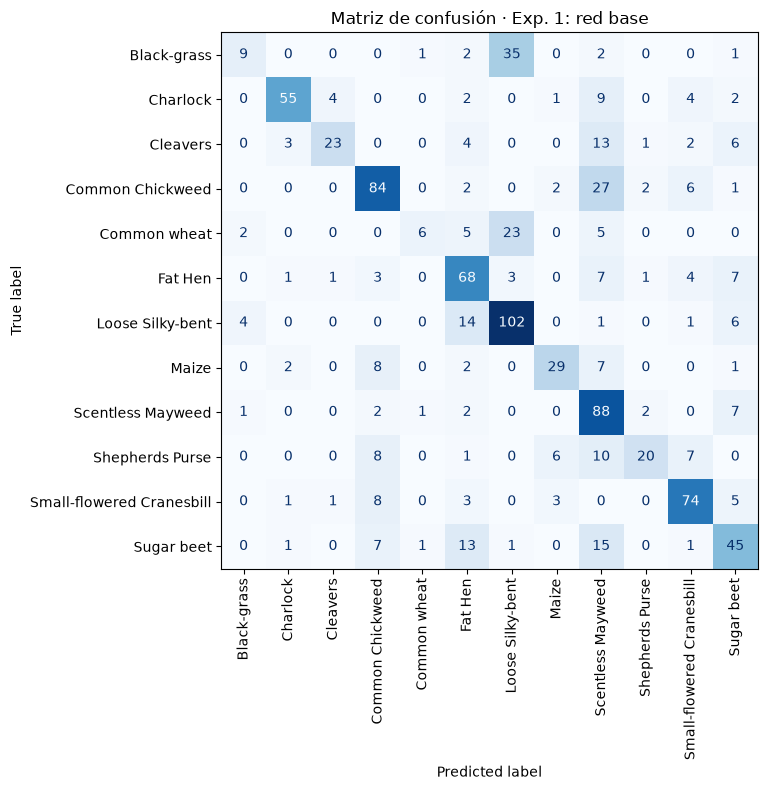

In [ ]:
res_exp1 = evaluar(exp1, titulo="Exp. 1: red base")

**Resultado.** **63,5 % de accuracy** y **F1 macro de 0,581**, muy por encima de las referencias (8,3 % al azar y 13,5 % respondiendo siempre la clase mayoritaria). La red base **sí aprende** a distinguir especies, aunque con muchos errores.

**Qué especies van bien y cuáles mal** (informe por clase y matriz de confusión).

* Las especies de **hoja ancha** que mejor se reconocen son *Charlock* (F1 0,79), *Small-flowered Cranesbill* (0,76) y *Common Chickweed* (0,69). *Loose Silky-bent* también llega a 0,70, pero porque recibe las fotos de las otras gramíneas.
* Las peores son las **dos gramíneas minoritarias**, *Common wheat* (F1 0,24) y *Black-grass* (0,27). La matriz de confusión muestra por qué, ya que **23 de las 41 fotos de *Common wheat* y 35 de las 50 de *Black-grass* se clasifican como *Loose Silky-bent***, la otra gramínea, que es además la especie con más imágenes. Es exactamente lo que anticipaba la inspección (apartados 2.2 y 2.3), es decir, especies casi idénticas y desbalanceo a favor de la mayoritaria.
* *Scentless Mayweed* recibe 96 predicciones erróneas, sobre todo de *Common Chickweed* (27), *Sugar beet* (15), *Cleavers* (13) y *Shepherds Purse* (10). La red la usa como respuesta "por defecto" para plantas pequeñas.
* El F1 macro (0,581) está por debajo de la accuracy (0,635) precisamente porque penaliza estos fallos en las especies con pocas fotos.

**Variabilidad.** El 63,5 % no es un número exacto, porque si se entrena la misma red otra vez, el resultado puede ser bastante distinto. Es justo lo que nos ha pasado en el grupo de trabajo, ya que la misma red (misma arquitectura, misma semilla 4096 y mismas fotos) se entrenó también en el experimento individual del Exp. 4, en otro equipo.

| Equipo | Mejor época | Accuracy en validación |
|---|---|---|
| Mac (este cuaderno) | 5 | **63,5 %** |
| Windows con GPU NVIDIA, Keras con backend PyTorch (experimento individual del Exp. 4, patience 5) | 7 | **73,5 %** |

Son **10 puntos de diferencia** con la misma red y el motivo es que la semilla fija el punto de partida (pesos iniciales, partición y orden de los datos), pero no garantiza que todo el entrenamiento sea idéntico, por estos motivos.

* Las GPU hacen millones de sumas en paralelo y no siempre en el mismo orden, y cada orden redondea de forma un poco distinta. Además, Metal (Mac), NVIDIA y PyTorch calculan de manera diferente.
* Esas diferencias minúsculas se acumulan época a época y el entrenamiento acaba siguiendo **otro camino**.
* Como esta red es **muy inestable** (la pérdida de validación salta de 1,25 a más de 17), un camino algo distinto lleva a una **mejor época** distinta y con otro resultado.

Por eso, las cifras de un solo entrenamiento deben tomarse como **orientativas**, porque las diferencias de pocos puntos entre experimentos pueden deberse al azar y no a la técnica que se añade.

**Siguiente prueba experimental.** El problema principal es el **sobreajuste**, porque la red memoriza las 3.800 fotos de entrenamiento y deja de mejorar en validación a partir de la época 5. La primera técnica de regularización a probar es el **data augmentation** (Exp. 2), ya que al transformar las fotos al azar en cada época, la red no puede memorizarlas y tiene que aprender la forma de las plantas. Además, las rotaciones y el zoom deberían ayudar con las gramíneas, cuyas hojas finas aparecen en todas las orientaciones.

### 4.2 Experimento 2, con data augmentation

**Responsable.** Alfredo

#### Arquitectura y entrenamiento

El Exp. 2 es **la misma red del Exp. 1** con una sola diferencia, y es que delante de la primera convolución se añade el bloque de **data augmentation** del apartado 3.4 (volteo horizontal, rotación, zoom y traslación al azar).

* Las capas de augmentation forman parte del modelo, pero **solo actúan durante el entrenamiento**. Al evaluar o predecir, Keras las desactiva y la red ve las fotos de validación tal cual.
* No añaden parámetros, así que la red sigue teniendo **12,9 millones**, y la capa densa sigue siendo el 99 % del total.
* Se entrena con el mismo protocolo (`entrenar()`) y los mismos datos normalizados (`train_ds`, `val_ds`).

Como en cada época la red ve versiones distintas de cada foto, ya no puede memorizarlas. Esperamos que aprenda **más despacio** (necesitará más épocas) pero que la validación siga mejorando durante más tiempo.

In [ ]:
keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en cada ejecución

exp2 = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    # Data augmentation (apartado 3.4): solo se aplica durante el entrenamiento
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    # Resto de la red, igual que en el Exp. 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="exp2_augmentation")

exp2.summary()

Model: "exp2_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,980 (49.36 MB)

 Trainable params: 12,939,980 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

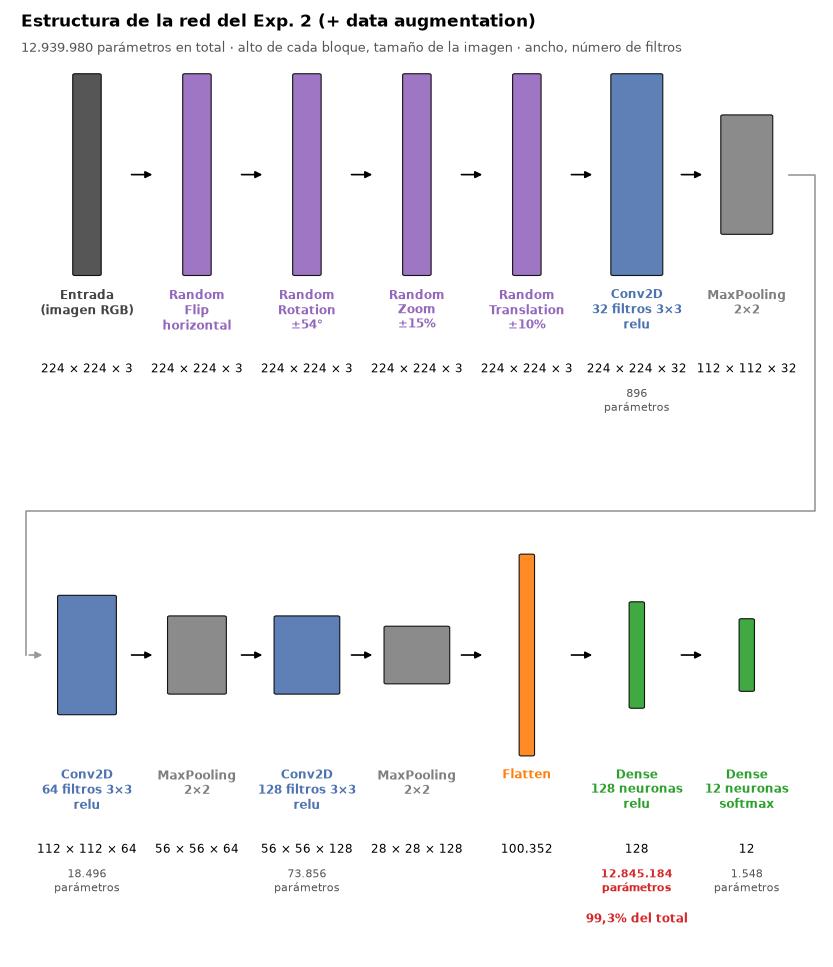

In [ ]:
# @title Diagrama: estructura de la red del Exp. 2
# Usa la función dibujar_red() definida en el diagrama del Exp. 1
dibujar_red(exp2, "Estructura de la red del Exp. 2 (+ data augmentation)", "exp2_estructura_red.png")

Recordamos que el **data augmentation** (apartado 3.4) consiste en transformar **al azar** cada foto de entrenamiento en cada época, sin crear imágenes nuevas en disco, de modo que la red nunca ve exactamente la misma imagen dos veces.

* **Volteo horizontal** (`RandomFlip`). Refleja la foto de izquierda a derecha, la mitad de las veces.
* **Rotación** (`RandomRotation`). Gira la foto hasta ±54°.
* **Zoom** (`RandomZoom`). Acerca o aleja hasta un 15 %.
* **Traslación** (`RandomTranslation`). Desplaza la foto hasta un 10 % en vertical y en horizontal.

Como las fotos están tomadas desde arriba, una planta girada, desplazada o vista algo más de cerca sigue siendo de la misma especie. Así la red tiene que aprender la forma de las plantas en lugar de memorizar cada foto.

En el diagrama, esas transformaciones son las **cuatro capas moradas**. No cambian el tamaño de la imagen (siguen siendo 224 × 224 × 3) ni tienen parámetros que aprender, y solo actúan durante el entrenamiento. A partir de ahí, la red es **idéntica a la del Exp. 1**, con los mismos **12,9 millones de parámetros** y el mismo problema, ya que el 99 % están en la capa densa que sigue a `Flatten`.

**Modelo ya entrenado.** El modelo de este experimento (`exp2_augmentation.keras`, 155 MB) también es demasiado grande para GitHub, así que está disponible en [Google Drive](https://drive.google.com/file/d/1TQ40K0kxwuPwt1lW9evOB3k6jYR0PrpP/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia1/` junto a su historial (`exp2_augmentation_historial.json`), y la función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, la red se entrena de nuevo (en un Mac M4 Pro tarda unos 2 minutos).

In [ ]:
exp2, hist2 = entrenar(exp2, "exp2_augmentation")

Epoch 1/40
119/119 - 549s - 5s/step - accuracy: 0.2658 - loss: 2.1814 - val_accuracy: 0.4147 - val_loss: 1.8054 - learning_rate: 0.0010
Epoch 2/40
119/119 - 541s - 5s/step - accuracy: 0.4521 - loss: 1.5814 - val_accuracy: 0.5905 - val_loss: 1.2933 - learning_rate: 0.0010
Epoch 3/40
119/119 - 541s - 5s/step - accuracy: 0.5179 - loss: 1.3840 - val_accuracy: 0.6305 - val_loss: 1.1745 - learning_rate: 0.0010
Epoch 4/40
119/119 - 580s - 5s/step - accuracy: 0.5687 - loss: 1.2628 - val_accuracy: 0.6484 - val_loss: 1.1039 - learning_rate: 0.0010
Epoch 5/40
119/119 - 495s - 4s/step - accuracy: 0.5808 - loss: 1.2100 - val_accuracy: 0.6253 - val_loss: 1.1827 - learning_rate: 0.0010
Epoch 6/40
119/119 - 516s - 4s/step - accuracy: 0.6126 - loss: 1.1208 - val_accuracy: 0.6695 - val_loss: 0.9930 - learning_rate: 0.0010
Epoch 7/40
119/119 - 511s - 4s/step - accuracy: 0.6361 - loss: 1.0685 - val_accuracy: 0.7158 - val_loss: 0.9443 - learning_rate: 0.0010
Epoch 8/40
119/119 - 570s - 5s/step - accuracy: 

#### Monitorización del entrenamiento

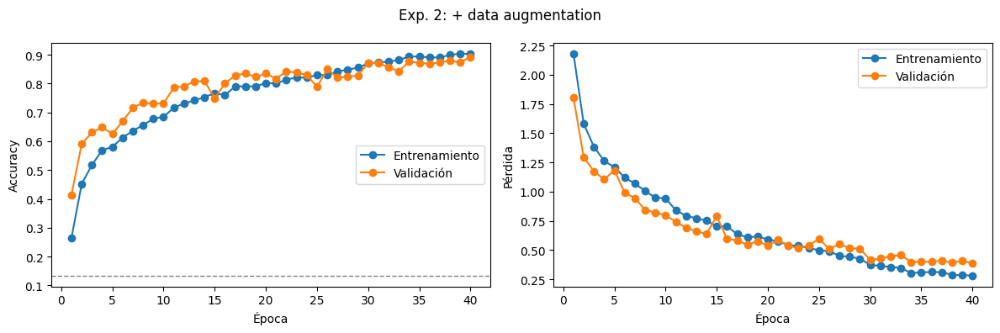

In [ ]:
curvas(hist2, "Exp. 2: + data augmentation")

**Accuracy y learning rate, época a época.** Como en los experimentos anteriores, las líneas de puntos marcan cada vez que ReduceLROnPlateau divide el learning rate entre 2.

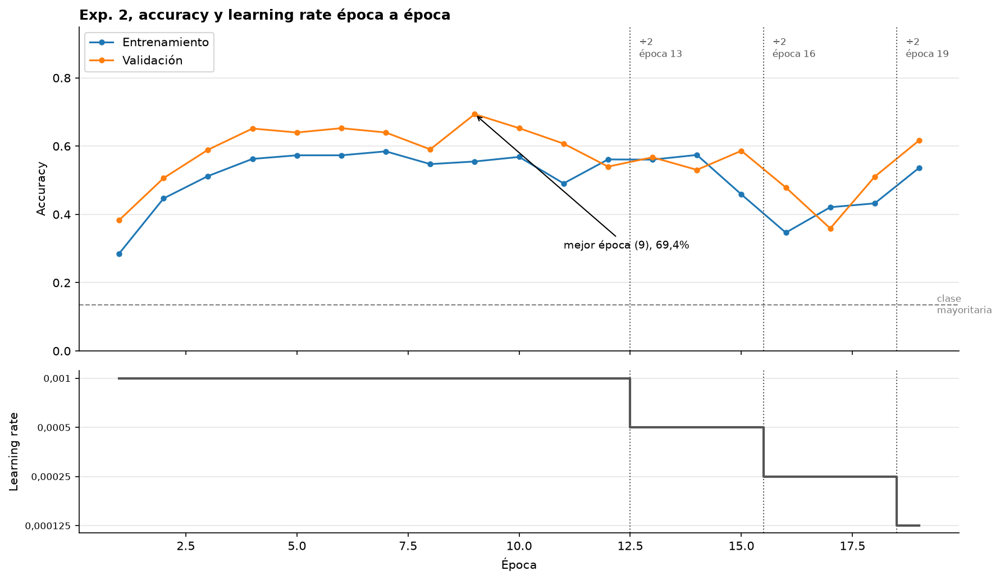

In [ ]:
# @title Gráfico de la accuracy y el learning rate del Exp. 2, época a época
# Usa la función grafico_lr() definida en el Exp. 1
grafico_lr(hist2, "Exp. 2, accuracy y learning rate época a época", "exp2_learning_rate.png")

**Qué muestran las curvas.**

* **Épocas 1 a 9, la red aprende y ya no memoriza.** La pérdida de validación baja hasta su mínimo (**1,00**) en la **época 9**, con un **69,4 %** de acierto. A diferencia del Exp. 1, las curvas de entrenamiento y validación van juntas, porque el data augmentation ha eliminado el sobreajuste.
* **La accuracy de entrenamiento queda por debajo de la de validación** (57 % frente a 65 % en la época 6). No es un error, ya que la red se entrena con fotos giradas, desplazadas y ampliadas, que son más difíciles que las fotos originales de validación.
* **A partir de la época 10, el entrenamiento se descontrola.** Esta vez no es sobreajuste, porque **también empeora el entrenamiento**. Su pérdida sube de 1,3 a más de 7 y su accuracy cae hasta el 35 % en la época 16. Los pasos del optimizador son demasiado grandes y la red "se sale del camino". Es la misma inestabilidad que ya se veía en el Exp. 1 y viene de la enorme capa densa de 12,8 millones de pesos.
* **ReduceLROnPlateau** bajó el learning rate tres veces (de 0,001 a 0,000125) y la red empezaba a recuperarse (61,7 % en la época 19), pero **EarlyStopping** paró justo en la época 19, tras 10 épocas sin mejorar, y recuperó los pesos de la época 9.

**Comparación con otro entrenamiento de la misma red.** En el experimento individual del Exp. 4, entrenada en un equipo con Windows y GPU NVIDIA, esta misma red no se descontroló. Entrenó las 40 épocas, seguía mejorando al final y llegó al **89,9 %**. Confirma lo que vimos en el Exp. 1 (63,5 % en el Mac frente a 73,5 % en Windows), que con esta arquitectura el resultado depende mucho del camino que siga el entrenamiento.

#### Evaluación y siguiente prueba experimental

Exp. 2: + data augmentation
Accuracy: 69.4% · F1 macro: 0.658 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.684     0.260     0.377        50
                 Charlock      0.727     0.831     0.776        77
                 Cleavers      0.607     0.712     0.655        52
         Common Chickweed      0.989     0.742     0.848       124
             Common wheat      0.575     0.561     0.568        41
                  Fat Hen      0.680     0.537     0.600        95
         Loose Silky-bent      0.661     0.945     0.778       128
                    Maize      0.893     0.510     0.649        49
        Scentless Mayweed      0.608     0.738     0.667       103
          Shepherds Purse      0.420     0.654     0.511        52
Small-flowered Cranesbill      0.878     0.684     0.769        95
               Sugar beet      0.699     0.690     0.695        84

              

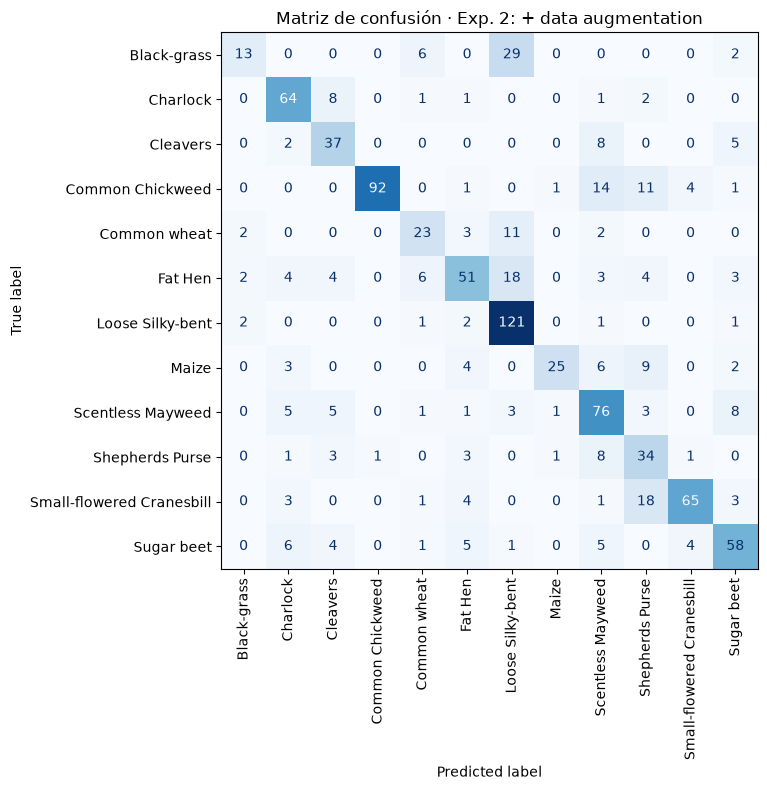

In [ ]:
res_exp2 = evaluar(exp2, titulo="Exp. 2: + data augmentation")

**Resultado.** **69,4 % de accuracy** y **F1 macro de 0,658**, frente al 63,5 % y 0,581 del Exp. 1.

| Experimento | Mejor época | Accuracy | F1 macro |
|---|---|---|---|
| Exp. 1 (red base) | 5 | 63,5 % | 0,581 |
| Exp. 2 (+ data augmentation) | 9 | **69,4 %** | **0,658** |

El data augmentation mejora unos **6 puntos** de accuracy y casi **8 centésimas** de F1 macro. El F1 macro sube más que la accuracy porque la mejora se concentra en especies minoritarias.

**Qué especies mejoran y cuáles no** (informe por clase y matriz de confusión).

* ***Common wheat* es la especie que más mejora.** Su F1 pasa de 0,24 a **0,57**. Ahora acierta 23 de sus 41 fotos y solo 11 se confunden con *Loose Silky-bent* (antes eran 23). Las rotaciones ayudan a reconocer sus hojas finas en cualquier orientación.
* ***Black-grass* apenas mejora** (F1 de 0,27 a 0,38). **29 de sus 50 fotos siguen clasificándose como *Loose Silky-bent***. Las dos gramíneas son casi idénticas a 224 × 224 y la red sigue prefiriendo la especie con más fotos.
* ***Loose Silky-bent* se ha convertido en la respuesta "por defecto"**. Acierta el 94,5 % de sus fotos, pero recibe **62 predicciones erróneas** de otras especies (29 de *Black-grass*, 18 de *Fat Hen*, 11 de *Common wheat*). Por eso su precisión es solo de 0,66.
* ***Shepherds Purse* tiene la peor precisión** (0,42). Recibe 47 fotos de otras especies, sobre todo de *Small-flowered Cranesbill* (18) y *Common Chickweed* (11), plantas pequeñas que se le parecen en sus primeras hojas.
* *Maize* solo acierta la mitad de sus fotos (25 de 49), aunque cuando la red dice *Maize* casi siempre acierta (precisión 0,89).

**Siguiente prueba experimental.** El data augmentation ha resuelto el **sobreajuste**, pero ha dejado al descubierto el otro problema de esta red, un **entrenamiento inestable**, en el que incluso la pérdida de entrenamiento se dispara. La siguiente técnica de la cadena es **Batch Normalization** (Exp. 3), que normaliza las salidas de cada capa en cada lote para que sus valores no se descontrolen y el entrenamiento sea más estable. Es justo lo que necesita esta red. Sin embargo, con una capa densa tan grande y un learning rate de 0,001, existe el riesgo de que el entrenamiento se descontrole todavía más al principio. Lo comprobaremos en el Exp. 3.

### 4.3 Experimento 3, con batch normalization

**Responsable.** Raúl

#### Arquitectura y entrenamiento

El Exp. 3 es **la red del Exp. 2** (con data augmentation) a la que se añade **Batch Normalization** en los tres bloques convolucionales, en la misma posición que el notebook común, es decir, **después de cada convolución y antes de la ReLU**.

Recordamos que **Batch Normalization** normaliza, en cada lote de 32 imágenes, las salidas de la capa anterior para que tengan media 0 y desviación 1, y después las reescala con dos parámetros que la red aprende. Así los valores que pasan de una capa a otra no se descontrolan, y el entrenamiento suele ser **más estable y más rápido**. Es justo lo que le faltaba al Exp. 2, cuya pérdida de entrenamiento se disparó a partir de la época 10.

* La convolución se escribe **sin activación** y la ReLU pasa a una capa `Activation("relu")` propia, para poder colocar el BatchNorm entre ambas. No es una capa nueva, sino la misma ReLU que ya llevaban las convoluciones de los Exp. 1 y 2, ahora separada (en el diagrama, los bloques amarillos).
* Cada BatchNorm añade 4 valores por filtro (2 que se aprenden y 2 medias que se calculan), es decir, apenas **900 parámetros más** sobre los 12,9 millones.
* Se entrena con **el mismo protocolo** que los experimentos anteriores (Adam con learning rate 0,001).

**Qué hace la ReLU.** Es una función de activación muy sencilla. A cada valor que sale del BatchNorm le aplica una regla, si es negativo lo convierte en 0 y si es positivo lo deja igual (ReLU(−3) = 0 y ReLU(5) = 5). Cada filtro da valores altos donde encuentra su patrón (un borde, una mancha verde…) y valores bajos o negativos donde no lo encuentra, así que la ReLU se queda solo con lo que el filtro ha encontrado. Es la función más usada en las CNN porque es muy rápida de calcular y no frena el aprendizaje, como sí hacían funciones más antiguas (la sigmoide o la tangente hiperbólica).

**Qué pasaría sin ellas.** Una convolución y un BatchNorm solo hacen sumas y multiplicaciones. Sin la ReLU, tres convoluciones seguidas equivaldrían casi a una sola operación de ese tipo, y la red perdería la capacidad de combinar patrones simples (bordes) en formas cada vez más complejas (hojas, plantas). Solo quedaría algo de no linealidad en los `MaxPooling2D` y en la capa densa del final, así que la red aprendería mucho peor. No lo hemos probado, pero es la razón de que todas las CNN lleven una función de activación después de cada convolución.

In [ ]:
keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en cada ejecución

exp3 = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    # Data augmentation (igual que en el Exp. 2)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    # Bloques convolucionales: convolución → BatchNorm → ReLU → MaxPooling
    layers.Conv2D(32, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    # Clasificador, igual que en los Exp. 1 y 2
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="exp3_batchnorm")

exp3.summary()

Model: "exp3_batchnorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,876 (49.37 MB)

 Trainable params: 12,940,428 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

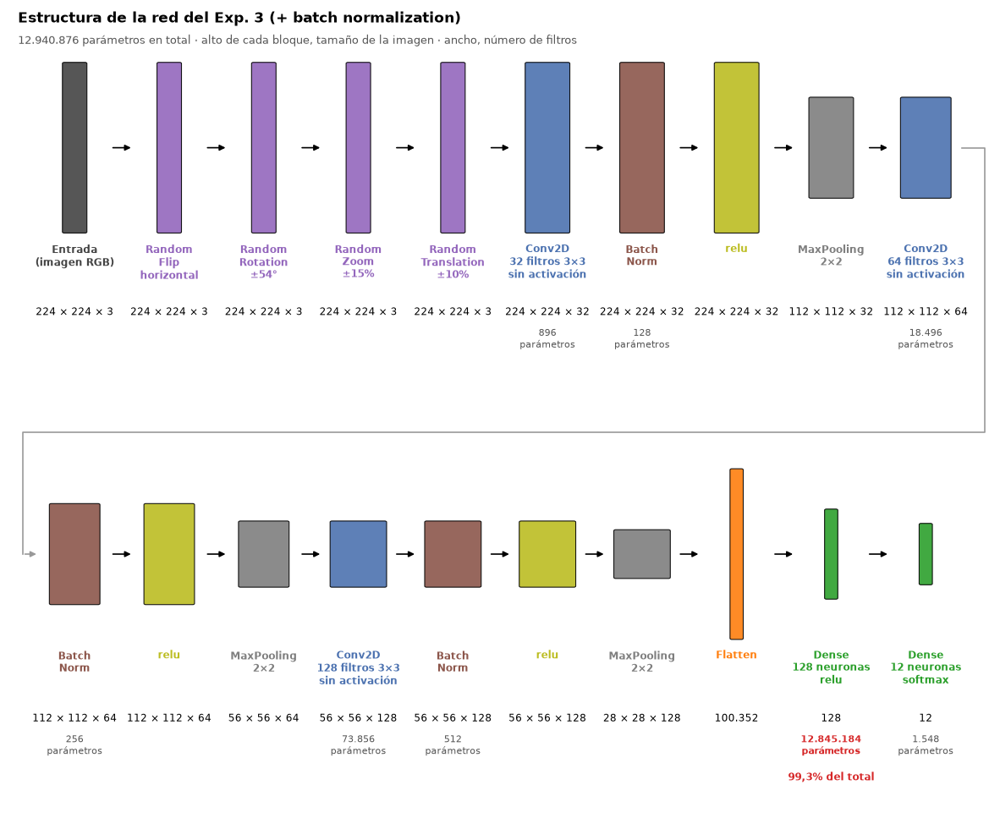

In [ ]:
# @title Diagrama: estructura de la red del Exp. 3
# Usa la función dibujar_red() definida en el diagrama del Exp. 1
dibujar_red(exp3, "Estructura de la red del Exp. 3 (+ batch normalization)", "exp3_estructura_red.png")

En el diagrama, las capas marrones son los **BatchNorm** y las amarillas, las **ReLU**, que ahora van en su propia capa. El resto es igual que en el Exp. 2, con el data augmentation al principio (en morado) y la misma capa densa con el 99 % de los parámetros.

**Modelo ya entrenado.** El modelo de este experimento (`exp3_batchnorm.keras`, 155 MB) también es demasiado grande para GitHub, así que está disponible en [Google Drive](https://drive.google.com/file/d/1x_kpbs1VHIbjeFeL5top0fQ5l4uTqt77/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia1/` junto a su historial (`exp3_batchnorm_historial.json`), y la función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, la red se entrena de nuevo (en un Mac M4 Pro tarda unos 7 minutos).

In [ ]:
exp3, hist3 = entrenar(exp3, "exp3_batchnorm")

Epoch 1/40


119/119 - 13s - 112ms/step - accuracy: 0.1437 - loss: 46.6449 - val_accuracy: 0.1063 - val_loss: 9.3929 - learning_rate: 0.0010


Epoch 2/40


119/119 - 11s - 89ms/step - accuracy: 0.2039 - loss: 12.5707 - val_accuracy: 0.1347 - val_loss: 9.6134 - learning_rate: 0.0010


Epoch 3/40


119/119 - 11s - 90ms/step - accuracy: 0.2782 - loss: 10.0796 - val_accuracy: 0.1737 - val_loss: 6.1810 - learning_rate: 0.0010


... (71 outputs left out)

119/119 - 11s - 90ms/step - accuracy: 0.7184 - loss: 1.3362 - val_accuracy: 0.7168 - val_loss: 1.3925 - learning_rate: 1.5625e-05


Epoch 40/40


119/119 - 11s - 89ms/step - accuracy: 0.7226 - loss: 1.3098 - val_accuracy: 0.7105 - val_loss: 1.4210 - learning_rate: 1.5625e-05


Tiempo de entrenamiento: 7.1 min


#### Monitorización del entrenamiento

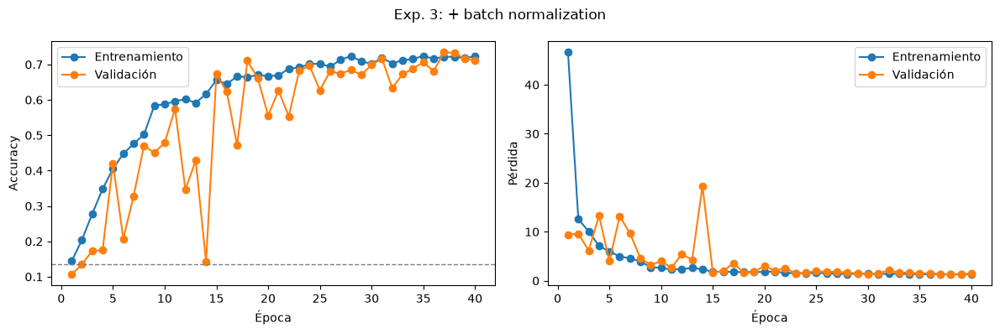

In [ ]:
curvas(hist3, "Exp. 3: + batch normalization")

**Accuracy y learning rate, época a época.** Como en los experimentos anteriores, las líneas de puntos marcan cada vez que ReduceLROnPlateau divide el learning rate entre 2. En este experimento es la clave para entender lo que ocurre. Con el learning rate inicial (0,001) la validación da saltos enormes, y la red solo empieza a aprender de forma estable a medida que se va reduciendo.

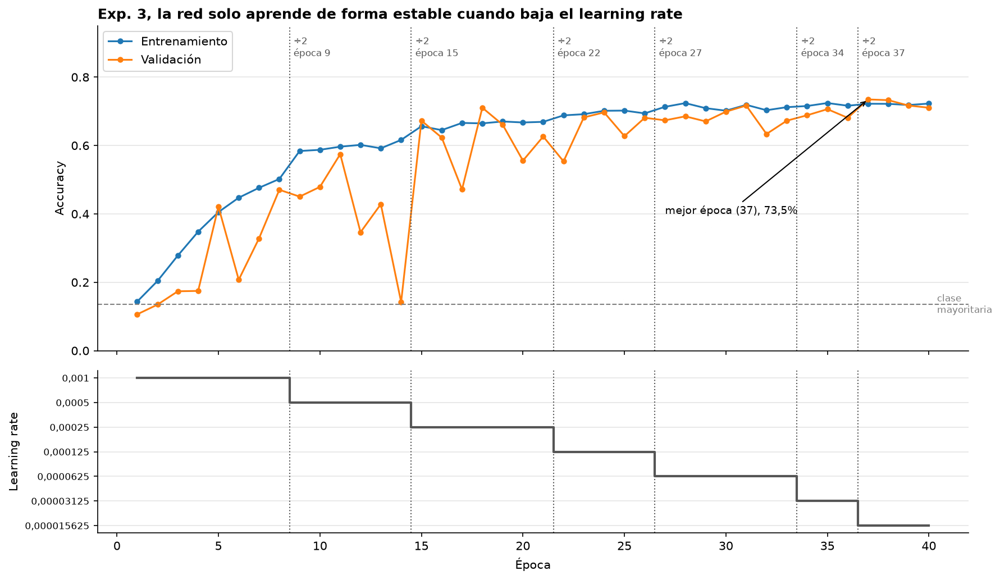

In [ ]:
# @title Gráfico de la accuracy y el learning rate del Exp. 3, época a época
h = hist3.history
epocas = np.arange(1, len(h["loss"]) + 1)
lr = np.array(h["learning_rate"])
bajadas = [e for e in epocas[1:] if lr[e - 1] < lr[e - 2]]            # épocas en que el lr se divide entre 2
mejor = int(np.argmin(h["val_loss"])) + 1

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# Arriba, accuracy de entrenamiento y validación
ax1.plot(epocas, h["accuracy"], marker="o", ms=4, label="Entrenamiento")
ax1.plot(epocas, h["val_accuracy"], marker="o", ms=4, label="Validación")
ax1.axhline(REF_MAYORITARIA, color="gray", ls="--", lw=1)
ax1.text(epocas[-1] + 0.4, REF_MAYORITARIA, "clase\nmayoritaria", color="gray", fontsize=8, va="center")
ax1.annotate(f"mejor época ({mejor}), {h['val_accuracy'][mejor - 1]:.1%}".replace(".", ","),
             xy=(mejor, h["val_accuracy"][mejor - 1]), xytext=(mejor - 10, 0.40),
             arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)
ax1.set_ylabel("Accuracy"); ax1.set_ylim(0, 0.95); ax1.legend(loc="upper left")
ax1.set_title("Exp. 3, la red solo aprende de forma estable cuando baja el learning rate", loc="left", weight="bold")

# Abajo, learning rate (escala logarítmica, cada escalón es una división entre 2)
ax2.step(epocas, lr, where="mid", color="#555555", lw=2)
ax2.set_yscale("log"); ax2.set_ylabel("Learning rate"); ax2.set_xlabel("Época")
valores_lr = sorted(set(lr), reverse=True)
ax2.set_yticks(valores_lr)
ax2.set_yticklabels([f"{v:.9f}".rstrip("0").replace(".", ",") for v in valores_lr], fontsize=8)
ax2.minorticks_off()

# Líneas verticales en cada bajada del learning rate
for e in bajadas:
    for ax in (ax1, ax2):
        ax.axvline(e - 0.5, color="#555555", ls=":", lw=1)
    ax1.text(e - 0.3, 0.92, f"÷2\népoca {e}", fontsize=8, color="#555555", va="top")
for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURAS / "exp3_learning_rate.png", dpi=150, bbox_inches="tight")
plt.show()


**Qué muestran las curvas.**

* **Épocas 1 a 8, un arranque caótico.** La pérdida de entrenamiento empieza en **46,6** (en el Exp. 2 empezaba en 2,2) y en las cuatro primeras épocas la accuracy de validación se queda entre el 11 % y el 17 %, al nivel de las referencias. Parece que la red **ha colapsado**, porque con BatchNorm y learning rate 0,001, los pasos del optimizador son demasiado grandes para la enorme capa densa.
* **La validación da saltos enormes mientras el learning rate es alto.** Pasa del 42 % al 21 % de una época a otra, y en la época 14 cae al **14 %**, con una pérdida de 19,3. Además de los pasos demasiado grandes, influye el propio BatchNorm. Al entrenar normaliza con las medias de cada lote, pero al validar usa unas medias acumuladas durante el entrenamiento. Si los pesos cambian muy deprisa, esas medias van por detrás y la validación se descoloca.
* **La red se recupera cuando baja el learning rate.** ReduceLROnPlateau lo divide entre 2 **seis veces**. La secuencia es 0,001 → 0,0005 (época 9) → 0,00025 (época 15) → 0,000125 (época 22) → 0,0000625 (época 27) → 0,00003125 (época 34) → 0,000015625 (época 37). A partir de la época 15 las curvas se estabilizan y suben poco a poco.
* **La mejor época es la 37** (73,5 %, pérdida de validación 1,31), con un learning rate **64 veces menor** que el inicial. El entrenamiento llegó al **límite de 40 épocas** sin que EarlyStopping lo parara, y la red todavía mejoraba despacio.
* **No hay sobreajuste.** Al final, la accuracy de entrenamiento (72 %) y la de validación (71–73 %) van juntas.

**Por qué la red no se ha quedado en el colapso. La importancia de la patience 10.** Durante el entrenamiento hubo varias rachas de entre 3 y 6 épocas seguidas sin mejorar la pérdida de validación antes de un nuevo avance (por ejemplo, de la época 31 a la 36, justo antes de la mejor época). Con **patience 5**, el valor del notebook común, este mismo entrenamiento se habría parado en la **época 28** y se habría quedado con los pesos de la época 23 (**68,2 %**), 5 puntos por debajo del resultado final. Y con un arranque solo un poco peor, se habría cortado en las primeras épocas, cuando la red apenas superaba a la clase mayoritaria, y habría parecido que esta arquitectura no funciona con BatchNorm. Con **patience 10**, la red ha tenido tiempo de llegar a las bajadas del learning rate y recuperarse, **sin necesidad de cambiar su diseño**. El colapso no era definitivo, sino un arranque muy malo. Es un buen ejemplo de por qué elegimos patience 10 en el protocolo.

#### Evaluación y siguiente prueba experimental

Exp. 3: + batch normalization
Accuracy: 73.5% · F1 macro: 0.698 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.375     0.300     0.333        50
                 Charlock      0.731     0.883     0.800        77
                 Cleavers      0.526     0.788     0.631        52
         Common Chickweed      0.897     0.774     0.831       124
             Common wheat      0.531     0.634     0.578        41
                  Fat Hen      0.779     0.853     0.814        95
         Loose Silky-bent      0.786     0.633     0.701       128
                    Maize      0.695     0.837     0.759        49
        Scentless Mayweed      0.779     0.786     0.783       103
          Shepherds Purse      0.667     0.462     0.545        52
Small-flowered Cranesbill      0.890     0.937     0.913        95
               Sugar beet      0.714     0.655     0.683        84

            

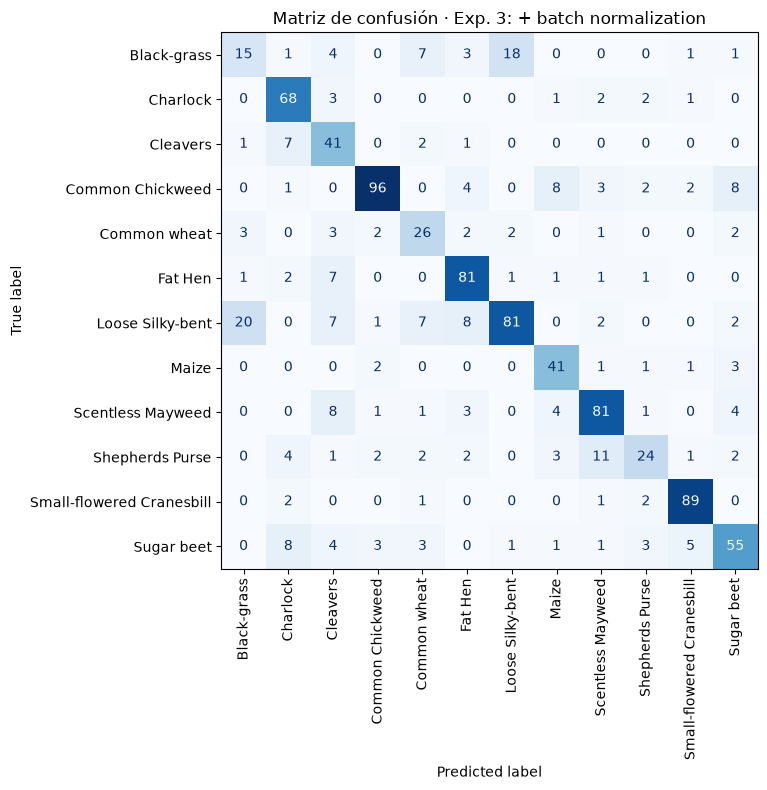

In [ ]:
res_exp3 = evaluar(exp3, titulo="Exp. 3: + batch normalization")

**Resultado.** **73,5 % de accuracy** y **F1 macro de 0,698**, el mejor resultado de la cadena hasta ahora.

| Experimento | Mejor época | Accuracy | F1 macro |
|---|---|---|---|
| Exp. 1 (red base) | 5 | 63,5 % | 0,581 |
| Exp. 2 (+ data augmentation) | 9 | 69,4 % | 0,658 |
| Exp. 3 (+ batch normalization) | 37 | **73,5 %** | **0,698** |

El BatchNorm mejora **4 puntos** de accuracy y 4 centésimas de F1 macro respecto al Exp. 2. Pero ha necesitado 37 épocas, frente a las 9 del Exp. 2, y solo ha aprendido bien cuando el learning rate ya había bajado mucho.

**Qué especies mejoran y cuáles no** (informe por clase y matriz de confusión).

* **Mejoran mucho tres especies de hoja ancha**, *Small-flowered Cranesbill* (F1 de 0,77 a **0,91**, acierta 89 de 95), *Fat Hen* (de 0,60 a **0,81**, acierta 81 de 95, antes 51) y *Maize* (de 0,65 a **0,76**, acierta 41 de 49, antes 25).
* ***Loose Silky-bent* deja de ser la respuesta "por defecto"**. Recibe 22 predicciones erróneas (antes 62). A cambio, ahora acierta menos fotos propias, 81 de 128 (antes 121).
* **Las gramíneas siguen sin distinguirse, pero ahora el error va en los dos sentidos.** 18 fotos de *Black-grass* se clasifican como *Loose Silky-bent* y 20 de *Loose Silky-bent* como *Black-grass*. La red ya no favorece a la especie mayoritaria, pero sigue sin encontrar la diferencia entre ellas. *Black-grass* sigue siendo la peor especie (F1 0,33) y *Common wheat* se queda igual (0,58).
* ***Shepherds Purse*** solo reconoce 24 de sus 52 fotos, y 11 se confunden con *Scentless Mayweed*, otra planta pequeña de hojas finas.

**Siguiente prueba experimental.** La siguiente técnica de la cadena es **Dropout** (Exp. 4), que apaga al azar una parte de las neuronas en cada paso del entrenamiento para que la red no dependa de unas pocas. Hay que tener en cuenta que el Dropout es una técnica contra el **sobreajuste**, y esta red ya no sobreajusta (entrenamiento y validación van juntos). Su problema ahora es que **aprende despacio y de forma inestable**, y terminó en el límite de 40 épocas cuando aún mejoraba. Por eso es posible que el Dropout no mejore el resultado o que la red necesite todavía más épocas. Lo comprobaremos en el Exp. 4.

### 4.4 Experimento 4, con Dropout

**Responsable.** Raúl

#### Arquitectura y entrenamiento

El Exp. 4 es **la red del Exp. 3** (data augmentation + BatchNorm) a la que se añade una capa **Dropout** entre la capa densa de 128 neuronas y la capa de salida, en la misma posición que el notebook común.

Recordamos que el **Dropout** apaga al azar una parte de las neuronas en cada paso del entrenamiento. Con una tasa de 0,3, cada neurona de la capa densa tiene un 30 % de probabilidad de quedar a 0 en cada lote. Así la red no puede depender de unas pocas neuronas concretas y tiene que repartir lo que aprende entre todas. Como el data augmentation, **solo actúa durante el entrenamiento**, y al evaluar se usan todas las neuronas.

* **Posición.** Antes de la capa de salida, el sitio clásico del Dropout. Es donde más actúa en esta red, porque la capa densa concentra el 99 % de los parámetros.
* **Tasa 0,3 en lugar del 0,5 del notebook común.** En el experimento individual del Exp. 4 (`Experimento_4_CNN_Dropout.ipynb`, presentado en la introducción del apartado 4) se compararon varias opciones, cada una con 3 semillas distintas.

| Dropout | Accuracy media en validación | Variación entre semillas |
|---|---|---|
| Sin dropout | 86,2 % | ±4,5 |
| **0,3 antes de la salida** | **88,1 %** | **±1,1** |
| 0,5 antes de la salida | 86,4 % | ±5,3 |
| 0,25 tras cada bloque convolucional + 0,5 antes de la salida | 79,8 % | ±9,8 |

  Con 0,3 se obtuvo la mejor media y, sobre todo, el entrenamiento más **estable**; con 0,5 el resultado fue igual que sin dropout, y añadirlo también en las convoluciones empeoró la red. Ese experimento se hizo con otra arquitectura (con GlobalAveragePooling), así que aquí comprobamos si la conclusión se mantiene en la red que decidimos en el grupo de prácticas, la que usa la capa `Flatten`.
* El Dropout **no añade parámetros**, así que la red sigue teniendo 12,9 millones. Se entrena con el mismo protocolo que los experimentos anteriores.

In [ ]:
keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en cada ejecución

exp4 = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    # Data augmentation (igual que en el Exp. 2)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    # Bloques convolucionales con BatchNorm (igual que en el Exp. 3)
    layers.Conv2D(32, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    # Clasificador con Dropout antes de la capa de salida
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="exp4_dropout")

exp4.summary()

Model: "exp4_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_3 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,876 (49.37 MB)

 Trainable params: 12,940,428 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

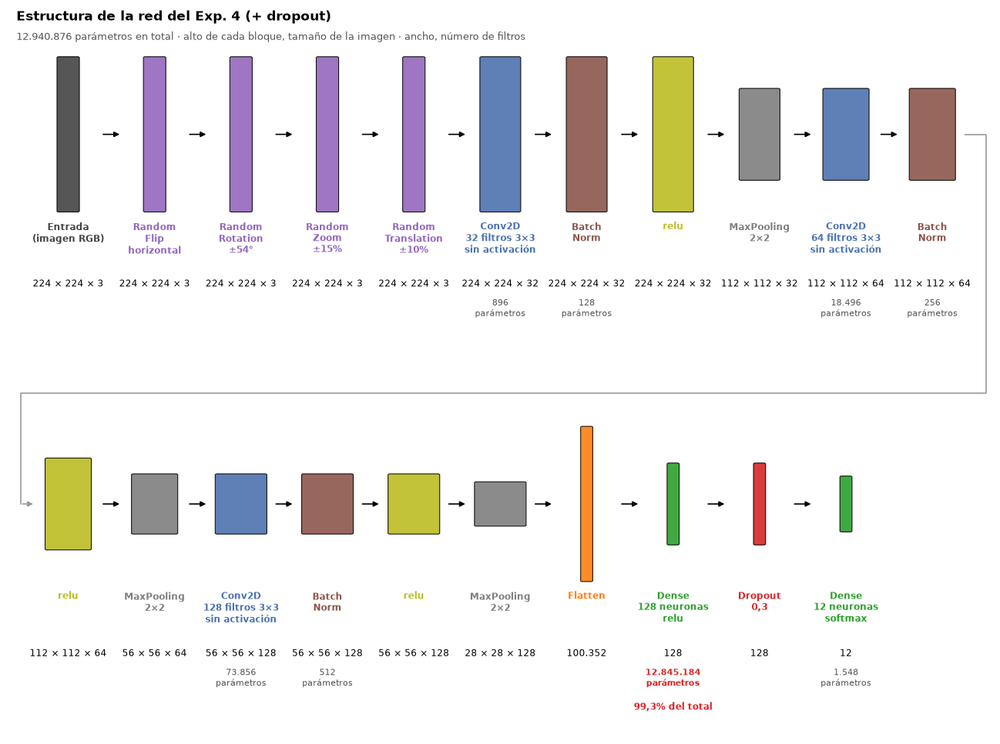

In [ ]:
# @title Diagrama: estructura de la red del Exp. 4
# Usa la función dibujar_red() definida en el diagrama del Exp. 1
dibujar_red(exp4, "Estructura de la red del Exp. 4 (+ dropout)", "exp4_estructura_red.png")

En el diagrama, la nueva capa es el **Dropout** (en rojo), entre las dos capas densas. No cambia el tamaño del vector (siguen siendo 128 valores) ni tiene parámetros, y solo pone a 0 al azar el 30 % de esos valores en cada paso del entrenamiento. El resto de la red es idéntico al Exp. 3.

**Modelo ya entrenado.** El modelo de este experimento (`exp4_dropout.keras`, 155 MB) también es demasiado grande para GitHub, así que está disponible en [Google Drive](https://drive.google.com/file/d/1q2t56rqnlL3NmGfTxcmIWMeW_q92eJuu/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia1/` junto a su historial (`exp4_dropout_historial.json`), y la función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, la red se entrena de nuevo (en un Mac M4 Pro tarda unos 7 minutos).

In [ ]:
exp4, hist4 = entrenar(exp4, "exp4_dropout")

Modelo ya entrenado: se carga exp4_dropout.keras. Registro del entrenamiento original:
       accuracy  val_accuracy      loss  val_loss learning_rate
época                                                          
1        0.1582        0.1347  165.0596  199.4331      1.00e-03
2        0.2742        0.1358  136.2789  134.3344      1.00e-03
3        0.3634        0.1653  107.4656  189.1325      1.00e-03
4        0.4361        0.2968   84.9784  101.6599      1.00e-03
5        0.4879        0.3442   73.3455  149.6267      1.00e-03
6        0.5118        0.6453   66.8539   31.8188      1.00e-03
7        0.5295        0.4747   59.3314   52.3386      1.00e-03
8        0.5555        0.3863   55.6814  144.1969      1.00e-03
9        0.5687        0.6379   48.8471   36.0251      1.00e-03
10       0.5945        0.6537   42.0552   31.1036      5.00e-04
11       0.6111        0.7695   37.8357   15.5719      5.00e-04
12       0.6255        0.6695   33.6975   38.7716      5.00e-04
13       0.6274  

#### Monitorización del entrenamiento

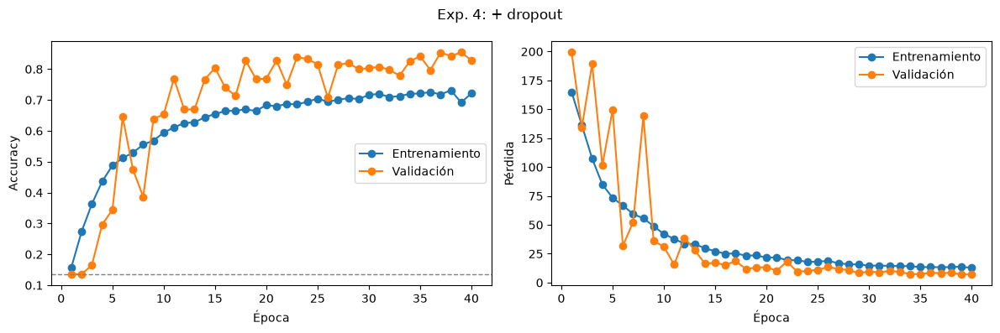

In [ ]:
curvas(hist4, "Exp. 4: + dropout")

**Accuracy y learning rate, época a época.** Como en los experimentos anteriores, las líneas de puntos marcan cada vez que ReduceLROnPlateau divide el learning rate entre 2.

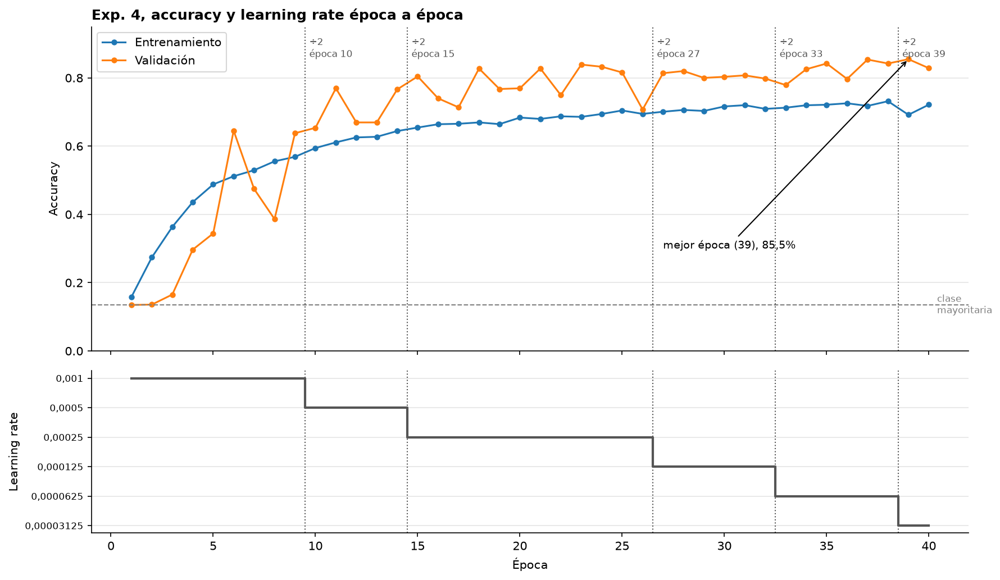

In [ ]:
# @title Gráfico de la accuracy y el learning rate del Exp. 4, época a época
# Usa la función grafico_lr() definida en el Exp. 1
grafico_lr(hist4, "Exp. 4, accuracy y learning rate época a época", "exp4_learning_rate.png")

**Qué muestran las curvas.**

* **El arranque vuelve a ser caótico**, como en el Exp. 3. La validación se queda entre el 13 % y el 34 % en las cinco primeras épocas y da saltos (del 65 % al 39 % entre las épocas 6 y 8).
* **Pero la red sale antes del caos.** En la época 11 ya llega al **77 %** y en la 15 al **80 %**, cuando el Exp. 3 estaba en el 57 % y el 67 %. Desde la época 18 la validación se mueve casi siempre entre el 75 % y el 85 %.
* **El learning rate vuelve a ser clave.** ReduceLROnPlateau lo divide entre 2 cinco veces (épocas 10, 15, 27, 33 y 39), y la **mejor época es la 39** (85,5 %), con un learning rate de 0,00003125. El entrenamiento llegó otra vez al **límite de 40 épocas**, todavía mejorando.
* **La accuracy de validación (78–85 % en las últimas épocas) queda muy por encima de la de entrenamiento (70–73 %).** No es un error, ya que durante el entrenamiento la red trabaja con fotos transformadas y con el 30 % de las neuronas de la capa densa apagadas, mientras que al validar ve las fotos originales y usa todas sus neuronas.
* **Las pérdidas son enormes** (165 en la primera época y todavía 7 en la mejor), aunque la red acierta el 85 %. La pérdida castiga mucho equivocarse con seguridad, y eso es lo que hace esta red, ya que en el **71 % de sus errores** da más de un 99 % de probabilidad a la especie equivocada. Es otro síntoma de la enorme capa densa, que produce salidas demasiado grandes.

#### Evaluación y siguiente prueba experimental

Exp. 4: + dropout
Accuracy: 85.5% · F1 macro: 0.836 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.564     0.440     0.494        50
                 Charlock      0.932     0.896     0.914        77
                 Cleavers      0.902     0.885     0.893        52
         Common Chickweed      0.874     0.895     0.884       124
             Common wheat      0.804     0.902     0.851        41
                  Fat Hen      0.918     0.937     0.927        95
         Loose Silky-bent      0.818     0.844     0.831       128
                    Maize      0.935     0.878     0.905        49
        Scentless Mayweed      0.758     0.913     0.828       103
          Shepherds Purse      0.879     0.558     0.682        52
Small-flowered Cranesbill      0.967     0.937     0.952        95
               Sugar beet      0.843     0.893     0.867        84

                 accurac

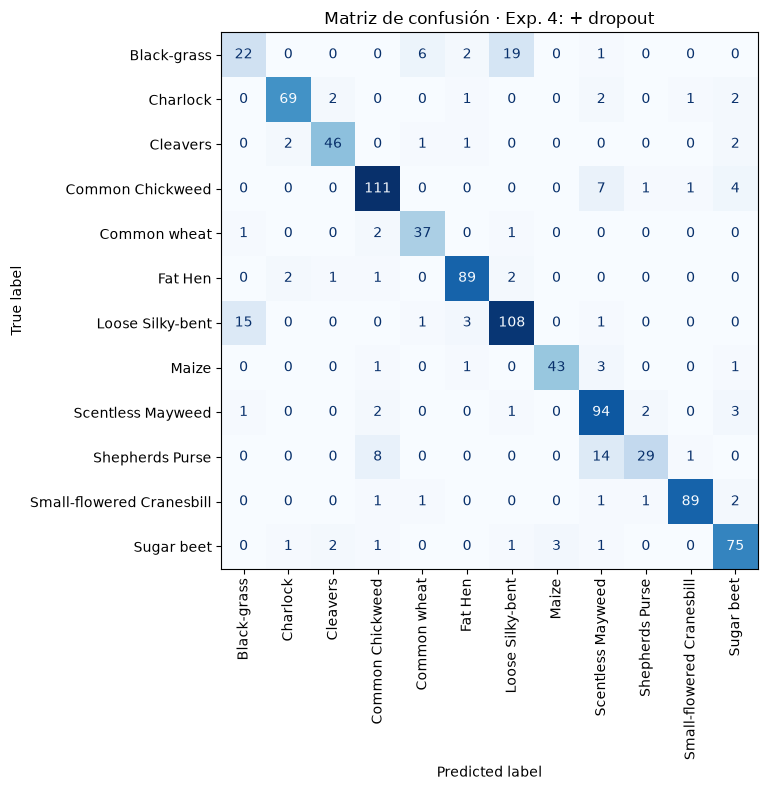

In [ ]:
res_exp4 = evaluar(exp4, titulo="Exp. 4: + dropout")

**Resultado.** **85,5 % de accuracy** y **F1 macro de 0,836**, el mayor salto de la cadena.

| Experimento | Mejor época | Accuracy | F1 macro |
|---|---|---|---|
| Exp. 1 (red base) | 5 | 63,5 % | 0,581 |
| Exp. 2 (+ data augmentation) | 9 | 69,4 % | 0,658 |
| Exp. 3 (+ batch normalization) | 37 | 73,5 % | 0,698 |
| Exp. 4 (+ dropout) | 39 | **85,5 %** | **0,836** |

El Dropout mejora **12 puntos** de accuracy y casi 14 centésimas de F1 macro respecto al Exp. 3. Es más de lo esperado, porque la red del Exp. 3 no sobreajustaba. Lo más probable es que el Dropout haya actuado sobre todo como **estabilizador**, como ya se vio en el experimento individual. Al apagar neuronas al azar, la enorme capa densa no puede depender de unas pocas combinaciones de valores, y la red sale antes del arranque caótico.

Aun así, conviene ser prudentes con la cifra exacta, porque es un solo entrenamiento, y en el experimento individual el mismo modelo con la misma semilla llegó a dar 81 % y 88 % en dos ejecuciones distintas.

**Qué especies mejoran y cuáles no** (informe por clase y matriz de confusión).

* **Mejoran casi todas.** Diez de las doce especies superan un F1 de 0,82, y *Small-flowered Cranesbill* (0,95), *Fat Hen* (0,93), *Charlock* (0,91) y *Maize* (0,91) pasan del 0,9.
* ***Common wheat* es la gran mejora.** Reconoce **37 de sus 41 fotos** (F1 de 0,58 a **0,85**) y solo 1 se confunde ya con *Loose Silky-bent* (antes 2).
* ***Black-grass* sigue siendo la peor especie** (F1 0,49), porque 19 de sus 50 fotos se clasifican como *Loose Silky-bent*, y 15 de *Loose Silky-bent* como *Black-grass*. Es la confusión que no ha resuelto ninguna técnica.
* ***Shepherds Purse*** solo reconoce 29 de 52 fotos, y 14 se confunden con *Scentless Mayweed* y 8 con *Common Chickweed*, plantas pequeñas que en sus primeras hojas se le parecen.

**Siguiente prueba experimental.** La última técnica de la cadena es la **regularización L2** (Exp. 5), que añade a la pérdida una penalización por tener pesos grandes. Encaja con el problema que muestran las curvas, porque la red da probabilidades de casi el 100 % incluso cuando se equivoca, porque los pesos de su capa densa producen salidas demasiado grandes. Al obligar a mantener los pesos pequeños, la L2 debería hacer la red **menos confiada en sus errores** y, quizá, más estable.

### 4.5 Experimento 5, con regularización L2

**Responsable.** Alfredo

#### Arquitectura y entrenamiento

El Exp. 5 es **la red del Exp. 4** (data augmentation + BatchNorm + Dropout) a la que se añade **regularización L2** en las tres convoluciones y en la capa densa de 128 neuronas, con el mismo valor que el notebook común, `regularizers.l2(0.001)`. Es el último experimento de la cadena.

Recordamos que la **regularización L2** (*weight decay*) suma a la pérdida una penalización proporcional al **cuadrado de los pesos**.

$$\text{pérdida total} = \text{entropía cruzada} + 0{,}001 \cdot \sum w^2$$

**Qué hace la L2, paso a paso.**

1. **Pone una "multa" a los pesos grandes.** Sin L2, el optimizador solo busca equivocarse lo menos posible y puede hacer crecer los pesos cuanto quiera. Con L2, cada peso suma a la pérdida 0,001 × su cuadrado, así que el optimizador busca un equilibrio, que es acertar, pero sin que los pesos crezcan. Un peso que apenas ayuda a acertar se va acercando a 0.
2. **Las salidas de la red son más moderadas.** Cada neurona suma los valores que recibe multiplicados por sus pesos. Con pesos grandes, esas sumas se disparan, y la capa softmax convierte números muy grandes en probabilidades extremas (un 99,9 % para una especie). Con pesos pequeños, las probabilidades son más moderadas y reflejan mejor cuándo la red duda.
3. **Es menos probable que la red memorice.** Para memorizar una foto concreta, la red tiene que reaccionar con mucha fuerza a detalles muy específicos (una piedrecita del suelo, el borde de la bandeja), y eso exige pesos grandes. Con pesos pequeños le cuesta "apostar fuerte" por esos detalles y tiende a fijarse en lo que se repite en muchas fotos, como la forma de las hojas. Por eso la L2 es una técnica contra el sobreajuste.

**A qué pesos se aplica.** La L2 se añade con `kernel_regularizer` en cuatro capas, igual que en el notebook común.

| Capa | Pesos penalizados |
|---|---|
| Conv2D de 32 filtros | 864 |
| Conv2D de 64 filtros | 18.432 |
| Conv2D de 128 filtros | 73.728 |
| Dense de 128 neuronas | 12.845.056 |
| **Total** | **12.938.080** (el 99,98 % de los parámetros de la red) |

* **Quedan fuera** la capa de salida (`Dense(12)`, 1.536 pesos), que es la que convierte las características en probabilidades; los *bias* de cada capa (364 valores), porque `kernel_regularizer` solo afecta a los pesos de las conexiones; y los parámetros del BatchNorm (896 valores). El data augmentation, las ReLU, el MaxPooling, el Flatten y el Dropout no tienen pesos.
* **Dentro de esas capas, la L2 no elige neuronas, sino que penaliza todos los pesos.** Como la multa es el **cuadrado** del peso, los grandes pagan mucho más que los pequeños (un peso de 2 cuesta 4, y uno de 0,1 cuesta 0,01). Por eso la L2 encoge sobre todo los pesos grandes, aunque casi nunca deja ninguno exactamente en 0 (eso lo hace la regularización L1).
* Como el 99 % de los pesos penalizados están en la `Dense(128)`, en nuestra red **la L2 actúa sobre todo en esa capa**.

**Por qué puede ayudar aquí. El problema de los pesos demasiado grandes.** La clave es que los pesos grandes **no cambian qué especie elige la red, sino lo segura que dice estar**.

La última capa da una puntuación a cada especie, y la softmax convierte esas puntuaciones en probabilidades. La softmax exagera las diferencias, porque cuanto más separadas están las puntuaciones, más extremas son las probabilidades. Por ejemplo, con tres especies sería así.

| | Especie A | Especie B | Especie C |
|---|---|---|---|
| Puntuaciones con pesos pequeños | 2 | 1,5 | 0,5 |
| → Probabilidades | **55 %** | 33 % | 12 % |
| Puntuaciones con pesos 10 veces mayores | 20 | 15 | 5 |
| → Probabilidades | **99,3 %** | 0,7 % | 0,0 % |

En los dos casos la red elige la especie A, así que acierta o falla igual. Pero con pesos pequeños dice "creo que es A, aunque podría ser B", y con pesos grandes dice "es A seguro". Si la foto era en realidad de la especie B, la red falla en los dos casos, pero de forma muy distinta. Con pesos pequeños dudaba (33 % para la correcta, pérdida de 1,1), y con pesos grandes se equivoca estando segurísima (0,7 %, pérdida de 5,0).

Eso es lo que pasaba en el Exp. 4, donde la red daba más de un 99 % de probabilidad a la especie equivocada en el **71 % de sus errores**. Tiene tres consecuencias.

1. **No se puede confiar en sus probabilidades.** La red dice un 99 % tanto cuando acierta como cuando se equivoca, así que no sirven para saber qué predicciones conviene revisar.
2. **La pérdida se dispara.** Cada error "seguro" cuenta muchísimo, y por eso la pérdida de validación del Exp. 4 era 7 con un 85 % de acierto.
3. **El entrenamiento es más inestable.** Los errores enormes producen correcciones enormes en los pesos, y la red avanza a saltos.

La L2 mantiene pequeños los pesos de la capa densa, así que las puntuaciones quedan menos separadas y las probabilidades son más moderadas. Por eso **esperamos que cambie sobre todo la seguridad de la red**, más que el número de aciertos.

**Cómo lo mediremos.**

* **La pérdida no es directamente comparable** con la de los experimentos anteriores, porque ahora incluye la multa por los pesos. Para comparar usamos la accuracy y el F1 macro.
* La L2 no añade parámetros, así que la red sigue teniendo 12,9 millones. Se entrena con el mismo protocolo.

In [ ]:
from keras import regularizers

keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en cada ejecución
L2 = 0.001                          # mismo valor que el notebook común

exp5 = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    # Data augmentation (igual que en el Exp. 2)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    # Bloques convolucionales con BatchNorm (Exp. 3) y ahora con L2
    layers.Conv2D(32, 3, padding="same", kernel_regularizer=regularizers.l2(L2)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", kernel_regularizer=regularizers.l2(L2)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", kernel_regularizer=regularizers.l2(L2)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    # Clasificador con L2 en la capa densa y Dropout (Exp. 4)
    layers.Flatten(),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(L2)),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="exp5_l2")

exp5.summary()

Model: "exp5_l2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_4 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_4               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_4 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_4            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,876 (49.37 MB)

 Trainable params: 12,940,428 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

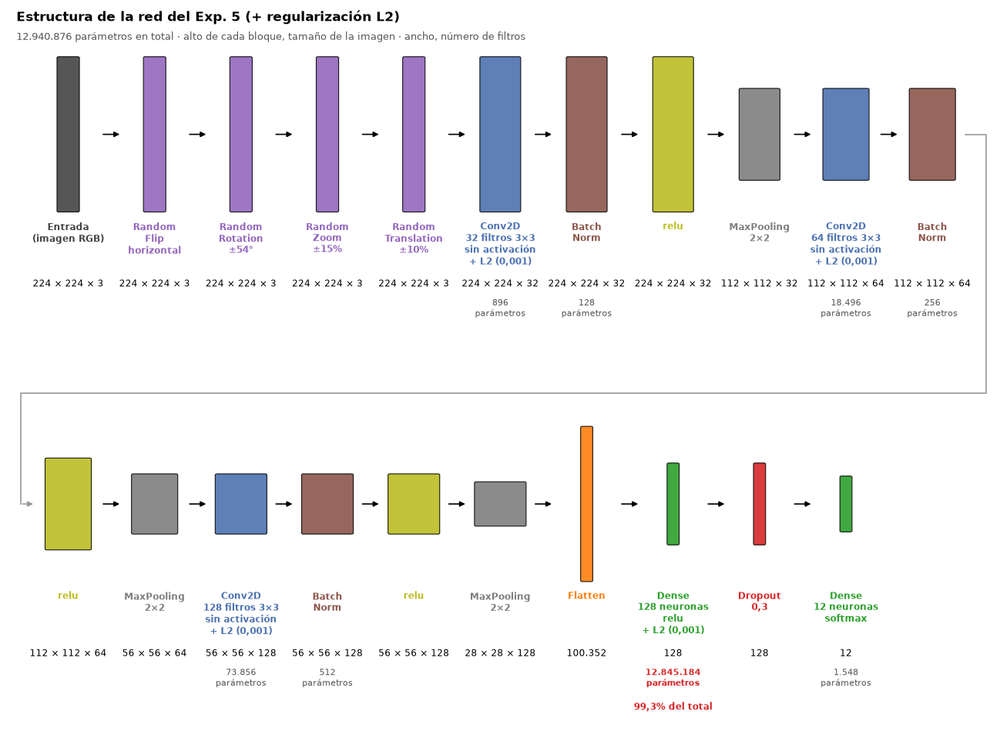

In [ ]:
# @title Diagrama: estructura de la red del Exp. 5
# Usa la función dibujar_red() definida en el diagrama del Exp. 1
dibujar_red(exp5, "Estructura de la red del Exp. 5 (+ regularización L2)", "exp5_estructura_red.png")

La estructura es **idéntica a la del Exp. 4**, porque la L2 no es una capa nueva, sino una penalización sobre los pesos de las capas que ya existían. En el diagrama se indica con **"+ L2 (0,001)"** bajo las tres convoluciones y la capa densa de 128 neuronas.

**Modelo ya entrenado.** El modelo de este experimento (`exp5_l2.keras`, 155 MB) también es demasiado grande para GitHub, así que está disponible en [Google Drive](https://drive.google.com/file/d/1QNA2UipqqVeKeq1_Ss0oGkQ38Wa--QKB/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia1/` junto a su historial (`exp5_l2_historial.json`), y la función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, la red se entrena de nuevo (en un Mac M4 Pro tarda unos 7 minutos).

In [ ]:
exp5, hist5 = entrenar(exp5, "exp5_l2")

Epoch 1/40


119/119 - 13s - 110ms/step - accuracy: 0.1618 - loss: 164.8499 - val_accuracy: 0.1347 - val_loss: 158.3733 - learning_rate: 0.0010


Epoch 2/40


119/119 - 11s - 91ms/step - accuracy: 0.2982 - loss: 120.9031 - val_accuracy: 0.1347 - val_loss: 156.3639 - learning_rate: 0.0010


Epoch 3/40


119/119 - 11s - 92ms/step - accuracy: 0.3895 - loss: 84.0705 - val_accuracy: 0.1726 - val_loss: 156.1770 - learning_rate: 0.0010


... (71 outputs left out)

119/119 - 11s - 93ms/step - accuracy: 0.7200 - loss: 1.6920 - val_accuracy: 0.8242 - val_loss: 1.3745 - learning_rate: 6.2500e-05


Epoch 40/40


119/119 - 11s - 95ms/step - accuracy: 0.7266 - loss: 1.6856 - val_accuracy: 0.8105 - val_loss: 1.3715 - learning_rate: 6.2500e-05


Tiempo de entrenamiento: 7.3 min


#### Monitorización del entrenamiento

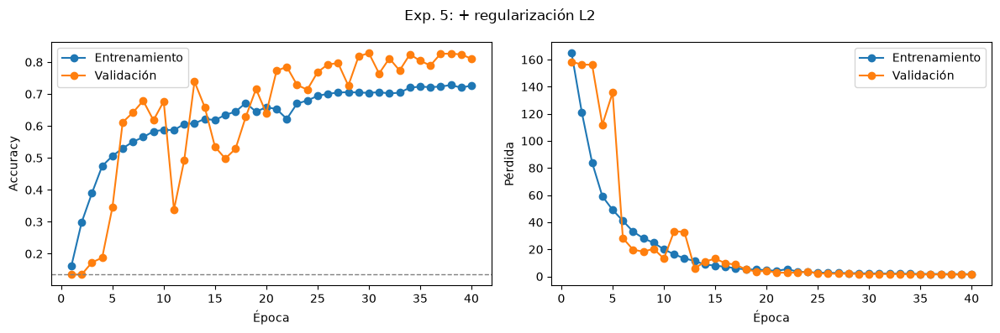

In [ ]:
curvas(hist5, "Exp. 5: + regularización L2")

**Accuracy y learning rate, época a época.** Como en los experimentos anteriores, las líneas de puntos marcan cada vez que ReduceLROnPlateau divide el learning rate entre 2.

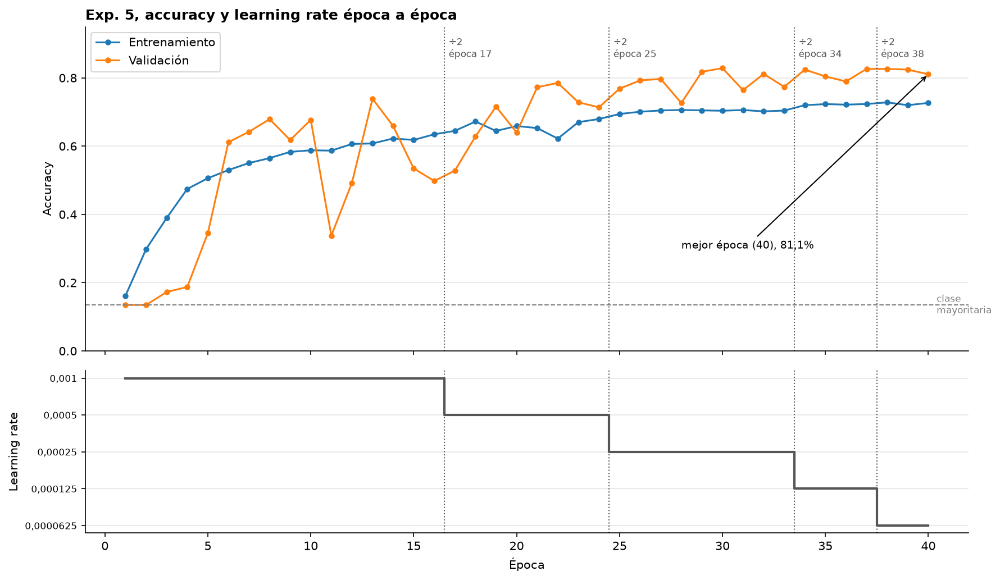

In [ ]:
# @title Gráfico de la accuracy y el learning rate del Exp. 5, época a época
# Usa la función grafico_lr() definida en el Exp. 1
grafico_lr(hist5, "Exp. 5, accuracy y learning rate época a época", "exp5_learning_rate.png")

**Qué muestran las curvas.**

* **El arranque es tan caótico como en los Exp. 3 y 4.** La validación se queda entre el 13 % y el 35 % en las cinco primeras épocas. En la época 6 ya llega al 61 %, pero hasta la 16 sigue dando saltos (del 74 % al 50 %).
* **La pérdida baja de forma mucho más ordenada.** Pasa de 158 a menos de 6 en la época 13 y termina en **1,37**, frente al 7 del Exp. 4. Parte de esa pérdida es la propia penalización L2 (unos 0,59 en la mejor época). La entropía cruzada sola (la pérdida menos la penalización), que es la medida comparable con el Exp. 4, es de **0,78 frente a 7,02**.
* **ReduceLROnPlateau actúa más tarde** (épocas 17, 25, 34 y 38), porque la pérdida de validación marca un nuevo mínimo cada pocas épocas, en parte porque los pesos se van haciendo más pequeños, y el learning rate se mantiene en 0,001 durante 16 épocas.
* **La mejor época es la 40** (81,1 %), la última. EarlyStopping elige la época con **menor pérdida de validación**, no con mayor accuracy, y por eso no se queda con la época 30, que llegó al 82,8 %. Otra vez se llegó al límite de 40 épocas.
* Como en el Exp. 4, la accuracy de validación (79–83 % en las últimas épocas) queda por encima de la de entrenamiento (72–73 %), porque al entrenar actúan el data augmentation y el Dropout.

#### Evaluación

Exp. 5: + regularización L2
Accuracy: 81.1% · F1 macro: 0.799 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.385     0.600     0.469        50
                 Charlock      0.928     0.831     0.877        77
                 Cleavers      0.978     0.846     0.907        52
         Common Chickweed      0.785     0.944     0.857       124
             Common wheat      0.795     0.854     0.824        41
                  Fat Hen      0.916     0.916     0.916        95
         Loose Silky-bent      0.798     0.617     0.696       128
                    Maize      0.955     0.857     0.903        49
        Scentless Mayweed      0.741     0.806     0.772       103
          Shepherds Purse      0.913     0.404     0.560        52
Small-flowered Cranesbill      0.899     0.937     0.918        95
               Sugar beet      0.849     0.940     0.893        84

              

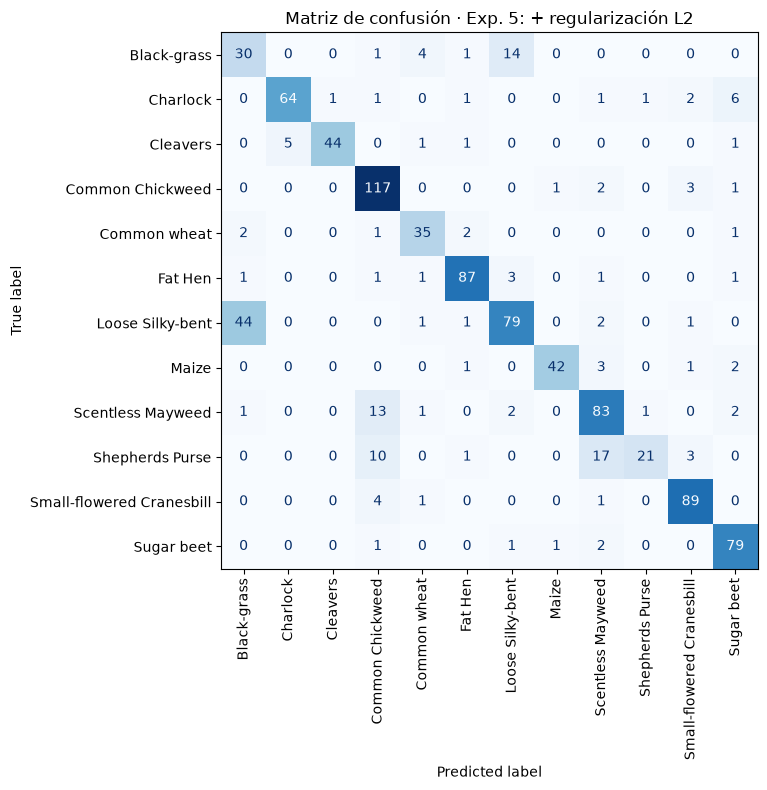

In [ ]:
res_exp5 = evaluar(exp5, titulo="Exp. 5: + regularización L2")

**Resultado.** **81,1 % de accuracy** y **F1 macro de 0,799**. Es la **primera técnica que empeora el resultado**, con 4,4 puntos de accuracy y casi 4 centésimas de F1 macro por debajo del Exp. 4.

| Experimento | Mejor época | Accuracy | F1 macro |
|---|---|---|---|
| Exp. 1 (red base) | 5 | 63,5 % | 0,581 |
| Exp. 2 (+ data augmentation) | 9 | 69,4 % | 0,658 |
| Exp. 3 (+ batch normalization) | 37 | 73,5 % | 0,698 |
| Exp. 4 (+ dropout) | 39 | **85,5 %** | **0,836** |
| Exp. 5 (+ regularización L2) | 40 | 81,1 % | 0,799 |

**La L2 sí ha hecho lo que esperábamos.** El objetivo era que la red dejara de estar tan segura cuando se equivoca, y lo ha conseguido.

| | Exp. 4 | Exp. 5 |
|---|---|---|
| Errores con más de un 99 % de seguridad | 71 % | **7 %** |
| Seguridad media en los errores | 94 % | **71 %** |
| Entropía cruzada en validación | 7,02 | **0,78** |

Es decir, la red del Exp. 5 es más **prudente**, y sus probabilidades reflejan mejor cuándo duda. Pero esa prudencia no se ha traducido en más aciertos, como anticipaba el ejemplo de las tres especies. Los pesos más pequeños cambian sobre todo la seguridad de la red, no qué especie elige.

**Dónde pierde aciertos** (informe por clase y matriz de confusión).

* **La confusión entre gramíneas cambia de sentido.** Ahora **44 de las 128 fotos de *Loose Silky-bent* se clasifican como *Black-grass*** (en el Exp. 4 eran 15). *Black-grass* reconoce más fotos propias (30 de 50, antes 22), pero recibe 48 fotos de otras especies, y su F1 se queda en 0,47. Solo esta confusión explica la mayor parte de la caída.
* ***Shepherds Purse* empeora.** Reconoce 21 de 52 fotos (antes 29). 17 se confunden con *Scentless Mayweed* y 10 con *Common Chickweed*.
* El resto de especies se mantiene en niveles parecidos al Exp. 4, como *Common wheat* (35 de 41), *Sugar beet* (79 de 84) y *Common Chickweed* (117 de 124).

**Cuidado con la conclusión.** Es un solo entrenamiento, y ya vimos en el Exp. 1 y en el experimento individual del Exp. 4 que la misma red puede variar varios puntos de una ejecución a otra. Una diferencia de 4 puntos, concentrada sobre todo en la confusión entre dos gramíneas casi idénticas, puede deberse en parte al azar. Lo que sí es claro es el efecto de la L2 sobre la seguridad de la red. Con estos datos, **el modelo con mejor accuracy y F1 macro de la cadena es el del Exp. 4**, y el del Exp. 5 es el mejor calibrado. La elección del modelo final se hace en el apartado 4.6.

### 4.6 Modelo final de la Estrategia 1

**Responsable.** Juan José

Reunimos los cinco experimentos de la cadena para elegir el **modelo final** de la red desde cero, que es el que se comparará con las redes preentrenadas en el apartado 6. Todos se han evaluado sobre las mismas 950 fotos de validación, con las mismas funciones.

In [ ]:
# Resumen de la cadena de experimentos
cadena = [
    ("Exp. 1", "Red base", exp1, hist1, res_exp1),
    ("Exp. 2", "+ Data augmentation", exp2, hist2, res_exp2),
    ("Exp. 3", "+ Batch normalization", exp3, hist3, res_exp3),
    ("Exp. 4", "+ Dropout (0,3)", exp4, hist4, res_exp4),
    ("Exp. 5", "+ Regularización L2 (0,001)", exp5, hist5, res_exp5),
]
resumen = pd.DataFrame([{
    "Experimento": exp,
    "Técnica añadida": tecnica,
    "Parámetros": f"{modelo.count_params():,}".replace(",", "."),
    "Épocas": len(h.history["loss"]),
    "Mejor época": int(np.argmin(h.history["val_loss"])) + 1,
    "Accuracy": f"{r['accuracy']:.1%}".replace(".", ","),
    "F1 macro": f"{r['f1_macro']:.3f}".replace(".", ","),
} for exp, tecnica, modelo, h, r in cadena]).set_index("Experimento")

# Cambio de accuracy respecto al experimento anterior
acc = [r["accuracy"] for *_, r in cadena]
resumen["Cambio de accuracy"] = ["—"] + [f"{(b - a) * 100:+.1f} puntos".replace(".", ",") for a, b in zip(acc, acc[1:])]

# Se resalta la fila del modelo elegido (el de mejor accuracy y F1 macro)
mejor = cadena[int(np.argmax([r["f1_macro"] + r["accuracy"] for *_, r in cadena]))][0]
resumen.style.apply(lambda fila: ["background-color: #e8dff5; font-weight: bold" if fila.name == mejor else ""
                                  for _ in fila], axis=1)

,Técnica añadida,Parámetros,Épocas,Mejor época,Accuracy,F1 macro,Cambio de accuracy
Experimento,,,,,,,
Exp. 1,Red base,12.939.980,15,5,"63,5%","0,581",—
Exp. 2,+ Data augmentation,12.939.980,19,9,"69,4%","0,658","+5,9 puntos"
Exp. 3,+ Batch normalization,12.940.876,40,37,"73,5%","0,698","+4,1 puntos"
Exp. 4,"+ Dropout (0,3)",12.940.876,40,39,"85,5%","0,836","+12,0 puntos"
Exp. 5,"+ Regularización L2 (0,001)",12.940.876,40,40,"81,1%","0,799","-4,4 puntos"


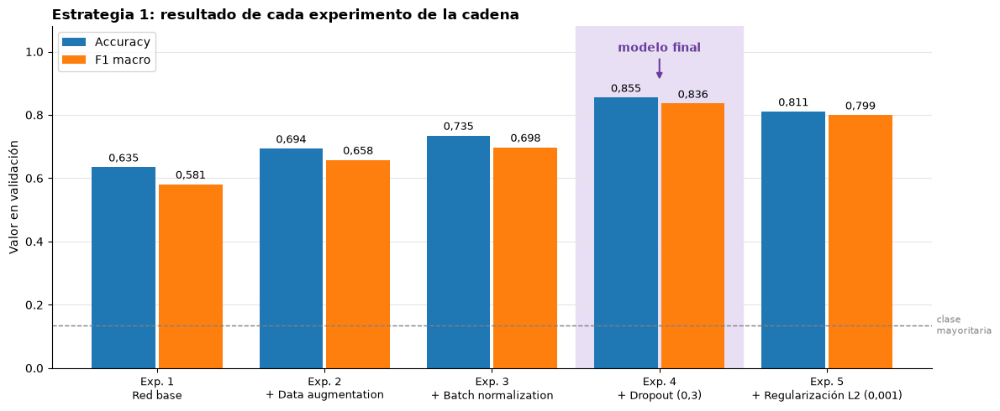

In [ ]:
# @title Gráfico: accuracy y F1 macro de cada experimento
nombres = [f"{exp}\n{tecnica}" for exp, tecnica, *_ in cadena]
acc = [r["accuracy"] for *_, r in cadena]
f1 = [r["f1_macro"] for *_, r in cadena]
x = np.arange(len(cadena))
ancho = 0.38

fig, ax = plt.subplots(figsize=(12, 5))
barras_acc = ax.bar(x - ancho / 2 - 0.01, acc, ancho, label="Accuracy")
barras_f1 = ax.bar(x + ancho / 2 + 0.01, f1, ancho, label="F1 macro")
for barras in (barras_acc, barras_f1):
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}".replace(".", ","),
                ha="center", va="bottom", fontsize=9)
ax.axhline(REF_MAYORITARIA, color="gray", ls="--", lw=1)
ax.text(1.005, REF_MAYORITARIA, "clase\nmayoritaria", color="gray", fontsize=8, va="center",
        transform=ax.get_yaxis_transform())

elegido = 3   # Exp. 4
ax.axvspan(elegido - 0.5, elegido + 0.5, color="#e8dff5", zorder=0)   # mismo color que su fila en la tabla
ax.annotate("modelo final", xy=(elegido, max(acc[elegido], f1[elegido]) + 0.05), xytext=(elegido, 1.0),
            ha="center", fontsize=10, weight="bold", color="#6a3d9a",
            arrowprops=dict(arrowstyle="-|>", color="#6a3d9a", lw=1.5))
ax.set_xticks(x); ax.set_xticklabels(nombres, fontsize=9)
ax.set_ylim(0, 1.08); ax.set_ylabel("Valor en validación")
ax.set_title("Estrategia 1: resultado de cada experimento de la cadena", loc="left", weight="bold")
ax.legend(loc="upper left")
ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURAS / "estrategia1_resumen_experimentos.png", dpi=150, bbox_inches="tight")
plt.show()

#### Resumen de lo que ha pasado en cada experimento

| Experimento | Qué se añade | Accuracy | F1 macro | Cambio respecto al anterior | Qué ha pasado |
|---|---|---|---|---|---|
| Exp. 1 | Red base | 63,5 % | 0,581 | — | Sobreajuste desde la época 5 (la red memoriza las fotos de entrenamiento) |
| Exp. 2 | + Data augmentation | 69,4 % | 0,658 | +5,9 puntos | Desaparece el sobreajuste, pero el entrenamiento se descontrola a partir de la época 10 |
| Exp. 3 | + Batch normalization | 73,5 % | 0,698 | +4,1 puntos | Arranque caótico; la red solo aprende de forma estable cuando baja el learning rate |
| **Exp. 4** | **+ Dropout (0,3)** | **85,5 %** ✔ | **0,836** ✔ | **+12,0 puntos** | **La mayor mejora, porque el Dropout estabiliza la enorme capa densa** |
| Exp. 5 | + Regularización L2 (0,001) | 81,1 % | 0,799 | **−4,4 puntos** | La red es más prudente (errores con más de un 99 % de confianza, del 71 % al 7 %), pero acierta menos |

Cada técnica de la cadena mejoró el resultado **excepto la última**. La L2 hace que la red se equivoque con menos seguridad, pero confunde más *Loose Silky-bent* con *Black-grass* y pierde 4,4 puntos de accuracy y 0,037 de F1 macro.

#### Por qué elegimos el Exp. 4

**El modelo final de la Estrategia 1 es el del Exp. 4** (data augmentation + BatchNorm + Dropout 0,3, sin L2).

* Tiene la **mejor accuracy (85,5 %) y el mejor F1 macro (0,836)** de toda la cadena. Son las dos métricas que fijamos para comparar todos los modelos, y el F1 macro asegura que la elección no depende solo de las especies con más fotos.
* Es el mismo criterio que usaremos en la Estrategia 2, donde el enunciado pide quedarse con la red preentrenada *"que mayor precisión proporcione"*. Así la comparación del apartado 6 es coherente.
* La regularización L2 se ha probado y su efecto se ha analizado, pero **no se incluye en el modelo final porque no mejora el rendimiento** (81,1 % y 0,799 frente a 85,5 % y 0,836). Probar una técnica y descartarla con datos también forma parte de justificar empíricamente la arquitectura final.
* Eso no significa que la L2 no aportara nada. **Corrigió el exceso de confianza de la red**, porque los errores con más de un 99 % de seguridad bajaron del 71 % al 7 % y la entropía cruzada en validación (que no solo mide si la red acierta, sino con qué seguridad), de 7,02 a 0,78. Es decir, el Exp. 5 se equivoca algo más, pero cuando se equivoca lo "sabe", y sus probabilidades son mucho más fiables. Si lo importante fuera detectar las fotos dudosas para revisarlas a mano, el Exp. 5 sería una opción razonable. Como el criterio fijado es la accuracy y el F1 macro, elegimos el Exp. 4.

#### Limitaciones del modelo final

* **Un solo entrenamiento por experimento.** Ya vimos en el Exp. 1 que la misma red puede variar varios puntos de una ejecución a otra. La ventaja del Exp. 4 sobre el Exp. 5 (4,4 puntos) es real en este entrenamiento, pero no podemos asegurar que se repita siempre.
* **El modelo se elige y se evalúa con las mismas fotos de validación**, porque las de `test/` no tienen etiqueta. Eso favorece un poco al modelo elegido. Lo mismo ocurrirá con la red preentrenada que elijamos en la Estrategia 2, así que la comparación sigue siendo justa.
* **Sigue sin distinguir bien las gramíneas.** *Black-grass* es la peor especie (F1 0,49), con 19 de sus 50 fotos clasificadas como *Loose Silky-bent*.
* La red llegó al límite de 40 épocas todavía mejorando y conserva la enorme capa densa de 12,8 millones de parámetros, que es la causa de su entrenamiento inestable.

In [ ]:
# Modelo final de la Estrategia 1: se usará en la comparación del apartado 6
modelo_final_e1, res_final_e1 = exp4, res_exp4
print(f"Modelo final de la Estrategia 1: {modelo_final_e1.name} · "
      f"accuracy {res_final_e1['accuracy']:.1%} · F1 macro {res_final_e1['f1_macro']:.3f} · "
      f"{modelo_final_e1.count_params():,} parámetros".replace(",", "."))

Modelo final de la Estrategia 1: exp4_dropout · accuracy 85.5% · F1 macro 0.836 · 12.940.876 parámetros


#### Prueba adicional. ¿Mejora el Exp. 4 con más épocas?

El Exp. 4 llegó al límite de 40 épocas cuando todavía mejoraba un poco. Para comprobar cuánto margen le quedaba, entrenamos **la misma arquitectura desde cero**, con la misma semilla y el mismo protocolo, pero con un límite de **100 épocas**. EarlyStopping (patience 10) sigue activo, así que el entrenamiento parará antes si la red deja de mejorar.

In [ ]:
keras.utils.set_random_seed(SEED)
exp4_100 = keras.models.clone_model(exp4)   # misma arquitectura que el Exp. 4 (con la misma semilla, los pesos iniciales son los mismos)
exp4_100, hist4_100 = entrenar(exp4_100, "exp4_dropout_100_epocas", max_epocas=100)

Epoch 1/100


119/119 - 12s - 102ms/step - accuracy: 0.1582 - loss: 165.0596 - val_accuracy: 0.1347 - val_loss: 199.4331 - learning_rate: 0.0010


Epoch 2/100


119/119 - 10s - 87ms/step - accuracy: 0.2742 - loss: 136.2789 - val_accuracy: 0.1358 - val_loss: 134.3344 - learning_rate: 0.0010


Epoch 3/100


119/119 - 10s - 87ms/step - accuracy: 0.3634 - loss: 107.4656 - val_accuracy: 0.1653 - val_loss: 189.1325 - learning_rate: 0.0010


... (103 outputs left out)

119/119 - 10s - 88ms/step - accuracy: 0.7334 - loss: 12.2197 - val_accuracy: 0.8453 - val_loss: 7.0362 - learning_rate: 3.9063e-06


Epoch 56/100


119/119 - 10s - 87ms/step - accuracy: 0.7208 - loss: 12.3129 - val_accuracy: 0.8505 - val_loss: 6.9787 - learning_rate: 1.9531e-06


Tiempo de entrenamiento: 9.7 min


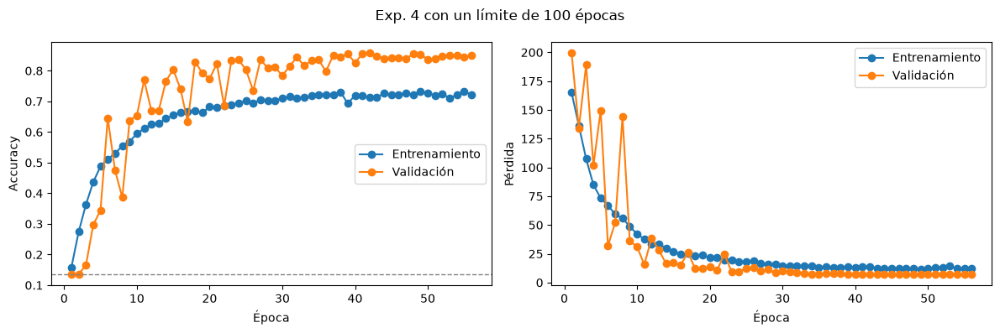

In [ ]:
curvas(hist4_100, "Exp. 4 con un límite de 100 épocas")

Exp. 4 con un límite de 100 épocas
Accuracy: 84.1% · F1 macro: 0.829 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.443     0.540     0.486        50
                 Charlock      0.923     0.935     0.929        77
                 Cleavers      0.855     0.904     0.879        52
         Common Chickweed      0.895     0.895     0.895       124
             Common wheat      0.804     0.902     0.851        41
                  Fat Hen      0.908     0.937     0.922        95
         Loose Silky-bent      0.840     0.695     0.761       128
                    Maize      0.935     0.878     0.905        49
        Scentless Mayweed      0.774     0.864     0.817       103
          Shepherds Purse      0.882     0.577     0.698        52
Small-flowered Cranesbill      0.978     0.947     0.963        95
               Sugar beet      0.789     0.893     0.838        84

       

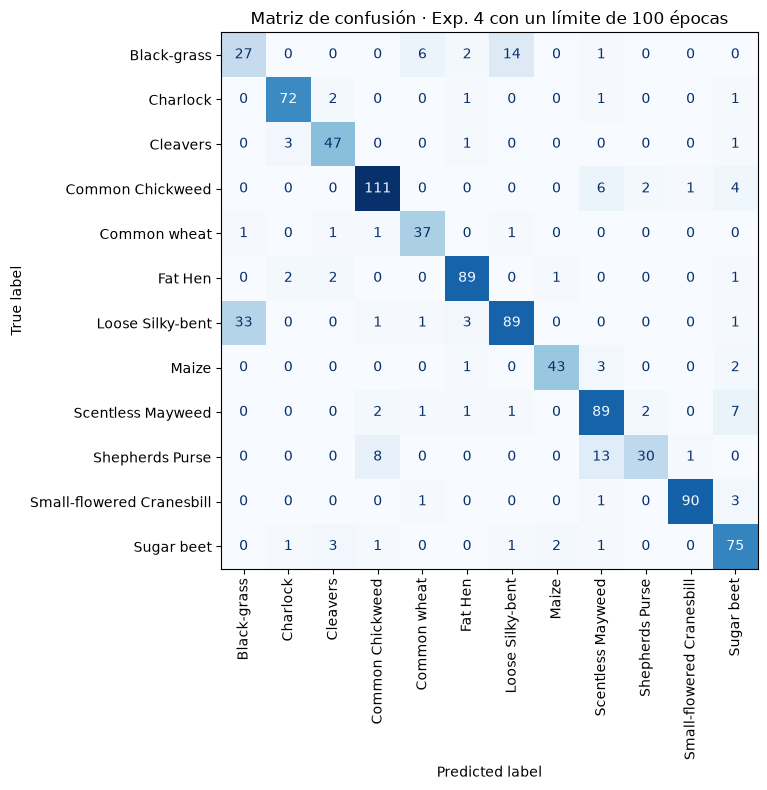

In [ ]:
res_exp4_100 = evaluar(exp4_100, titulo="Exp. 4 con un límite de 100 épocas")

**Resultado. Más épocas no mejoran la red.**

| | Límite de épocas | Épocas entrenadas | Mejor época | Accuracy | F1 macro |
|---|---|---|---|---|---|
| Exp. 4 | 40 | 40 | 39 | **85,5 %** | **0,836** |
| Exp. 4 con más épocas | 100 | 56 | 46 | 84,1 % | 0,829 |

* **EarlyStopping paró en la época 56**, muy lejos del límite de 100, porque después de la época 46, la red pasó 10 épocas sin mejorar la pérdida de validación.
* **A partir de la época 40 la red ya no aprende nada nuevo.** ReduceLROnPlateau siguió bajando el learning rate hasta 0,000002 (500 veces menos que el inicial), y la validación se quedó oscilando entre el 82 % y el 86 %. Esos pasos son ya tan pequeños que apenas cambian los pesos.
* **El resultado es prácticamente el mismo** (84,1 % frente a 85,5 %). La diferencia de 1,4 puntos está dentro de la variación normal entre dos entrenamientos de la misma red, como vimos en el Exp. 1.

**Conclusión.** El Exp. 4 ya había llegado a su techo en las 40 épocas. Con esta arquitectura y estos datos, la red no puede pasar de un 85 % aproximadamente, por muchas épocas que se entrene. **Mantenemos el Exp. 4 original como modelo final de la Estrategia 1.**

### 4.7 Comprobación con las fotos de test de Kaggle

**Responsable.** Juan José

Las 794 imágenes de `test/` **no tienen etiqueta**, y por eso no las hemos usado en ningún momento del cuaderno (apartado 3.1). Kaggle sí conoce la especie de cada una, porque era el conjunto con el que puntuaba la competición. La competición cerró en 2018, pero Kaggle sigue aceptando **envíos fuera de plazo**, que se puntúan igual aunque no entran en la clasificación.

Como comprobación final, predijimos la especie de esas 794 fotos con nuestro modelo final (Exp. 4) y con el mejor modelo de la Estrategia 2, que se presenta en el apartado 5 (InceptionResNetV2 con fine-tuning), y enviamos las dos predicciones a Kaggle. Kaggle las puntúa con el F1 micro, que en este caso equivale a la accuracy. Son fotos que **ningún modelo había visto nunca**, ni para entrenar ni para elegir el modelo.

**El código de esta prueba no se ha añadido al cuaderno**, porque el envío a Kaggle se hace fuera de él y con la cuenta de un miembro del grupo. Para asegurarnos de que el resultado es comparable, comprobamos antes que ese código lee las fotos igual que el cuaderno, ya que con él la validación vuelve a dar exactamente 85,5 % y 91,7 %.

| Modelo | Validación (950 fotos) | **Test de Kaggle (794 fotos nuevas)** |
|---|---|---|
| Exp. 4, nuestra red con todas las mejoras salvo la L2 (data augmentation, BatchNorm y Dropout) | 85,5 % | **86,9 %** |
| InceptionResNetV2 con fine-tuning (apartado 5) | 91,7 % | **90,9 %** |
| Diferencia entre las dos | 6,2 puntos | **4,0 puntos** |

**Qué significa.**

* **Nuestra red no ha aprendido las fotos de memoria.** Una red que memoriza acierta mucho con las fotos de entrenamiento y bastante menos con fotos nuevas. Es lo que le pasaba al Exp. 1, que llegó al 79 % en entrenamiento y se quedó en el 63,5 % en validación. El Exp. 4, en cambio, acierta el 86,9 % de 794 fotos que nunca vio, incluso algo más que en validación. Eso indica que ha aprendido rasgos generales de cada especie, como la forma de las hojas, y no los detalles de cada foto concreta. Es justo lo que buscábamos con el data augmentation, el BatchNorm y el Dropout.
* **La validación era una buena estimación.** Elegimos el modelo final con las mismas 950 fotos con las que lo evaluamos, y eso podía favorecerlo (lo señalamos como limitación en el apartado 7.5). Con fotos nuevas, el resultado cambia menos de 1,5 puntos en los dos modelos, así que esa elección no ha inflado las cifras.
* **La red preentrenada sigue siendo mejor**, aunque por 4,0 puntos en lugar de 6,2. La conclusión del apartado 6 se mantiene, pero la ventaja real es algo menor de lo que indicaba la validación.
* **Las gramíneas siguen siendo el punto débil.** En el test, el Exp. 4 solo respondió *Black-grass* 7 veces e InceptionResNetV2, 18, cuando por la proporción de esta especie en el dataset (5,5 %) cabría esperar unas 44.

## 5. Estrategia 2, redes preentrenadas

En esta estrategia no entrenamos una red desde cero, sino que partimos de redes que ya han aprendido a reconocer imágenes con **ImageNet** (1,2 millones de fotos de 1.000 categorías) y las adaptamos a nuestras 12 especies. Comparamos dos arquitecturas preentrenadas.

* **InceptionResNetV2**, elegida por ser la de **mayor acierto en ImageNet** de las que propone el enunciado (80,3 % de acierto top-1).
* **MobileNetV2**, elegida por ser la de **menor tamaño**. Con muy pocos parámetros consigue un acierto sorprendente (71,3 %), y por eso merece la pena analizarla.

**Qué es el transfer learning (aprendizaje por transferencia).** Consiste en **reutilizar lo que una red aprendió en una tarea para resolver otra distinta**. Es como un botánico que ya sabe reconocer miles de plantas y aprende a distinguir nuestras 12 especies con pocas fotos, porque no tiene que aprender desde cero qué es una hoja, un borde o una textura.

Funciona porque las capas de una CNN aprenden cosas cada vez más específicas, como vimos con los bloques convolucionales en el apartado 4.1.

* Las **primeras capas** detectan bordes, colores y texturas. Sirven para cualquier foto, sea un perro, una taza o una plántula.
* Las **capas intermedias** combinan esos rasgos en formas (curvas, puntas, contornos), que también son bastante generales.
* Las **últimas capas** combinan las formas en conceptos propios de ImageNet (orejas de perro, ruedas de coche…), y la capa de salida da la probabilidad de cada una de sus 1.000 categorías.

En el transfer learning nos quedamos con todo lo general, que es la mayor parte de la red, y solo cambiamos lo específico. La gran ventaja es que con pocas fotos se consigue mucho, porque la red no tiene que aprender a ver, solo a usar lo que ya sabe para distinguir nuestras especies. Por eso es la técnica habitual cuando hay pocos datos, como aquí (3.800 fotos frente a 1,2 millones).

En sentido amplio, toda esta estrategia es transfer learning. En el cuaderno, como es habitual, llamamos **transfer learning** a la primera fase, en la que la red base no cambia, y **fine-tuning** a la segunda, en la que se reajustan sus últimas capas.

**¿Por qué hay que entrenarlas si ya están preentrenadas?** "Preentrenada" significa que la red ya aprendió a ver con ImageNet, **pero nunca ha visto nuestras plantas**.

* Las 1.000 categorías de ImageNet son perros, coches, tazas, etc.; ninguna es una de nuestras 12 especies. Por eso se quita la capa de salida original (1.000 neuronas) y se pone una **nueva de 12 neuronas, con pesos al azar**. Hasta que no se entrena, esa capa no sabe nada y respondería como tirar un dado.
* Lo que sí se aprovecha es todo lo anterior a esa capa, porque la red ya sabe detectar bordes, texturas, formas de hojas, etc. Por eso basta con entrenar **muchos menos parámetros** (en el transfer learning, solo la cabeza nueva), y con solo 3.800 fotos se pueden obtener buenos resultados.

Con cada una se hacen dos fases, y **las dos son entrenamientos con nuestras fotos**.

1. **Transfer learning.** La red base se **congela** (sus pesos no cambian) y solo se entrena una cabeza nueva que clasifica las 12 especies. La red base actúa como un extractor de características ya entrenado, que sabe detectar bordes, texturas y formas, y la cabeza aprende a usar esas características para distinguir nuestras plantas.
2. **Fine-tuning.** Partiendo del mejor modelo del transfer learning, se **descongelan las últimas capas** de la red base y se reentrenan con un learning rate muy pequeño, para ajustar las características más específicas a nuestras fotos sin destruir lo aprendido con ImageNet.

**Diseño común de las dos redes.**

* **Imágenes de 224 × 224**, las mismas que en la Estrategia 1. Es el tamaño original de MobileNetV2; InceptionResNetV2 se diseñó para 299 × 299, pero admite cualquier tamaño a partir de 75 × 75, y así las dos estrategias reciben exactamente las mismas imágenes.
* **Preprocesado de cada red.** Las dos redes se entrenaron en ImageNet con píxeles entre −1 y 1 (es lo que hace su función `preprocess_input`). Como nuestros datos ya llegan normalizados entre 0 y 1 (apartado 3.3), una capa `Rescaling(2, offset=−1)` los pasa a ese rango.
* **Regularización.**
  * **Data augmentation**, el mismo de la Estrategia 1, solo en entrenamiento.
  * **Batch normalization.** Las dos redes ya lo incluyen. Sus capas BatchNorm se mantienen siempre **congeladas y en modo inferencia**, también en el fine-tuning, para no estropear sus estadísticas aprendidas con ImageNet usando lotes de solo 32 fotos.
  * **Dropout 0,3** antes de la capa de salida, el mismo valor que en la Estrategia 1 (Exp. 4).
  * **No usamos L2.** En la Estrategia 1 redujo el acierto (Exp. 5), y aquí la única capa nueva que se entrena desde cero es la de salida.
* **Cabeza nueva.** `GlobalAveragePooling2D` (resume cada mapa de características en un solo valor) → `Dropout(0,3)` → `Dense(12, softmax)`.
* **Protocolo.** El **transfer learning** usa el mismo protocolo que la Estrategia 1 (Adam con learning rate 0,001, hasta 40 épocas, EarlyStopping con patience 10 y ReduceLROnPlateau). El **fine-tuning** usa un learning rate **100 veces menor (0,00001)** y hasta 20 épocas, porque parte de un modelo ya entrenado y solo debe hacer ajustes pequeños.
* Los modelos se guardan en `resultados/estrategia2/` y, como en la Estrategia 1, si ya existen se cargan en lugar de entrenarlos de nuevo.

In [ ]:
RESULTADOS_E2 = BASE_FOLDER.parent / "resultados" / "estrategia2"
RESULTADOS_E2.mkdir(parents=True, exist_ok=True)
LR_FINE_TUNING = 1e-5
MAX_EPOCAS_FT = 20


def crear_preentrenada(clase_red, nombre):
    """Red preentrenada en ImageNet, con la base congelada y una cabeza nueva para las 12 especies."""
    base = clase_red(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    base.trainable = False                                   # transfer learning: la base no se entrena

    entradas = layers.Input(shape=(*IMG_SIZE, 3))
    # Data augmentation (igual que en la Estrategia 1)
    x = layers.RandomFlip("horizontal")(entradas)
    x = layers.RandomRotation(0.15)(x)
    x = layers.RandomZoom(0.15)(x)
    x = layers.RandomTranslation(height_factor=0.1, width_factor=0.1)(x)
    # Preprocesado de la red: de [0, 1] a [-1, 1], como su preprocess_input
    x = layers.Rescaling(2.0, offset=-1.0, name="preprocesado")(x)
    x = base(x, training=False)                              # BatchNorm de la base en modo inferencia
    # Cabeza nueva
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(NUM_CLASES, activation="softmax")(x)
    return keras.Model(entradas, salidas, name=nombre)


def parametros_entrenables(modelo):
    return int(sum(np.prod(w.shape) for w in modelo.trainable_weights))


def preparar_fine_tuning(modelo, primera_capa):
    """Descongela la base desde `primera_capa` hasta el final, salvo las capas BatchNorm."""
    base = next(c for c in modelo.layers if isinstance(c, keras.Model))
    base.trainable = True
    descongelar = False
    for capa in base.layers:
        descongelar = descongelar or capa.name == primera_capa
        capa.trainable = descongelar and not isinstance(capa, layers.BatchNormalization)
    entrenables = parametros_entrenables(modelo)
    print(f"Fine-tuning de {base.name} desde la capa {primera_capa}: "
          f"{entrenables:,} parámetros entrenables de {modelo.count_params():,} "
          f"({entrenables / modelo.count_params():.1%})".replace(",", "."))
    return modelo


def curvas_fases(hist_tl, hist_ft, titulo=""):
    # Curvas del transfer learning y del fine-tuning seguidas, separadas por una línea
    h = {k: hist_tl.history[k] + hist_ft.history[k] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
    corte = len(hist_tl.history["loss"]) + 0.5
    epocas = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nombre in zip(axes, ["accuracy", "loss"], ["Accuracy", "Pérdida"]):
        ax.plot(epocas, h[metrica], marker="o", ms=4, label="Entrenamiento")
        ax.plot(epocas, h["val_" + metrica], marker="o", ms=4, label="Validación")
        ax.axvline(corte, color="#555555", ls=":", lw=1.2)
        ax.text(corte - 0.3, 0.98, "transfer learning", transform=ax.get_xaxis_transform(),
                ha="right", va="top", fontsize=8, color="#555555")
        ax.text(corte + 0.3, 0.98, "fine-tuning", transform=ax.get_xaxis_transform(),
                ha="left", va="top", fontsize=8, color="#555555")
        ax.set_xlabel("Época"); ax.set_ylabel(nombre); ax.legend(loc="center right")
    axes[0].axhline(REF_MAYORITARIA, color="gray", ls="--", lw=1)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

**Cómo se comparan nuestra red y las dos preentrenadas antes de entrenar.** La tabla siguiente resume sus características. Las cifras de ImageNet son las publicadas en la documentación de Keras (https://keras.io/api/applications/); el resto se calcula con los modelos tal como los usamos aquí, con la cabeza de 12 especies.

In [ ]:
from keras.applications import InceptionResNetV2, MobileNetV2

keras.utils.set_random_seed(SEED)
irv2 = crear_preentrenada(InceptionResNetV2, "inceptionresnetv2")
mnv2 = crear_preentrenada(MobileNetV2, "mobilenetv2")


def capas_con_pesos(modelo):
    # Capas convolucionales y densas (las que hacen el trabajo de la red), contando las de dentro de la base
    capas = []
    for c in modelo.layers:
        capas += c.layers if isinstance(c, keras.Model) else [c]
    return sum(isinstance(c, (layers.Conv2D, layers.DepthwiseConv2D, layers.Dense)) for c in capas)


def mapa_final(modelo):
    base = next((c for c in modelo.layers if isinstance(c, keras.Model)), None)
    forma = base.output.shape if base is not None else next(c for c in modelo.layers if isinstance(c, layers.Flatten)).input.shape
    return " × ".join(str(d) for d in forma[1:])


comparacion = pd.DataFrame([
    {"Red": "Nuestra red (Exp. 4)", "Origen": "Diseñada y entrenada desde cero", "Año": "2026",
     "Acierto en ImageNet (top-1)": "—", "modelo": exp4},
    {"Red": "InceptionResNetV2", "Origen": "Preentrenada en ImageNet", "Año": "2016",
     "Acierto en ImageNet (top-1)": "80,3 %", "modelo": irv2},
    {"Red": "MobileNetV2", "Origen": "Preentrenada en ImageNet", "Año": "2018",
     "Acierto en ImageNet (top-1)": "71,3 %", "modelo": mnv2},
])
comparacion["Capas convolucionales y densas"] = [capas_con_pesos(m) for m in comparacion["modelo"]]
comparacion["Parámetros"] = [f"{m.count_params():,}".replace(",", ".") for m in comparacion["modelo"]]
comparacion["Peso de los parámetros"] = [f"{m.count_params() * 4 / 1e6:.0f} MB" for m in comparacion["modelo"]]
comparacion["Parámetros entrenables en transfer learning"] = [
    f"{parametros_entrenables(m):,}".replace(",", ".") for m in comparacion["modelo"]]
comparacion["Mapa final antes de clasificar"] = [mapa_final(m) for m in comparacion["modelo"]]
comparacion.drop(columns="modelo").set_index("Red").T

Red,Nuestra red (Exp. 4),InceptionResNetV2,MobileNetV2
Origen,Diseñada y entrenada desde cero,Preentrenada en ImageNet,Preentrenada en ImageNet
Año,2026,2016,2018
Acierto en ImageNet (top-1),—,"80,3 %","71,3 %"
Capas convolucionales y densas,5,245,53
Parámetros,12.940.876,54.355.180,2.273.356
Peso de los parámetros,52 MB,217 MB,9 MB
Parámetros entrenables en transfer learning,12.940.428,18.444,15.372
Mapa final antes de clasificar,28 × 28 × 128,5 × 5 × 1536,7 × 7 × 1280


**Qué muestra la tabla.**

* **InceptionResNetV2 es 4 veces más grande que nuestra red** (54 millones de parámetros frente a 13) y tiene más de 240 capas convolucionales frente a nuestras 3. Combina dos ideas, los módulos *Inception*, que aplican filtros de varios tamaños en paralelo, y las conexiones *residuales* de ResNet, que permiten entrenar redes muy profundas.
* **MobileNetV2 es casi 6 veces más pequeña que nuestra red** (2,3 millones de parámetros) a pesar de ser mucho más profunda. Usa convoluciones *separables en profundidad* (*depthwise separable*), que hacen el mismo trabajo que una convolución normal con muchas menos operaciones. Está pensada para móviles.
* **Dónde están los parámetros.** En nuestra red, el 99 % están en la capa densa que sigue a `Flatten`. Las preentrenadas usan `GlobalAveragePooling`, que resume cada mapa final en un solo número, así que su cabeza para 12 especies es diminuta. En el transfer learning solo se entrenan 18.444 parámetros de InceptionResNetV2 y 15.372 de MobileNetV2.
* **Lo que no está en la tabla y es lo más importante.** Las dos preentrenadas llegan sabiendo reconocer formas y texturas aprendidas con 1,2 millones de fotos, mientras que nuestra red aprendió todo con 3.800.

### 5.1 InceptionResNetV2

**Responsable.** Juan José

#### Transfer learning

La red base (54,3 millones de parámetros) se congela y solo se entrena la cabeza nueva. La celda siguiente muestra la estructura, con el data augmentation y el preprocesado, la red base completa como un único bloque (`inceptionresnetv2`) y la cabeza nueva.

In [ ]:
irv2.summary()
print(f"Parámetros entrenables: {parametros_entrenables(irv2):,}".replace(",", "."))

Model: "inceptionresnetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_5 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_5               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_5 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_5            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesado (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_resnet_v2             │ (None, 5, 5, 1536)     │    54,336,736 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 12)             │        18,444 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,355,180 (207.35 MB)

 Trainable params: 18,444 (72.05 KB)

 Non-trainable params: 54,336,736 (207.28 MB)

Parámetros entrenables: 18.444


**Modelo ya entrenado.** El modelo de esta fase (`irv2_transfer_learning.keras`, 220 MB) está disponible en [Google Drive](https://drive.google.com/file/d/1IUBhxV0XeAqWUqG-dZdS70SF0irgK-Vd/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia2/` junto a su historial (`irv2_transfer_learning_historial.json`). La función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, se entrena de nuevo (en un Mac M4 Pro tarda unos 13 minutos).

In [ ]:
irv2_tl, hist_irv2_tl = entrenar(irv2, "irv2_transfer_learning", carpeta=RESULTADOS_E2)

Epoch 1/40


119/119 - 31s - 260ms/step - accuracy: 0.3097 - loss: 2.0691 - val_accuracy: 0.5021 - val_loss: 1.4684 - learning_rate: 0.0010


Epoch 2/40


119/119 - 17s - 147ms/step - accuracy: 0.4708 - loss: 1.5458 - val_accuracy: 0.5821 - val_loss: 1.2713 - learning_rate: 0.0010


Epoch 3/40


119/119 - 17s - 146ms/step - accuracy: 0.5429 - loss: 1.3656 - val_accuracy: 0.6147 - val_loss: 1.1612 - learning_rate: 0.0010


... (71 outputs left out)

119/119 - 33s - 281ms/step - accuracy: 0.7113 - loss: 0.8442 - val_accuracy: 0.7800 - val_loss: 0.6828 - learning_rate: 1.2500e-04


Epoch 40/40


119/119 - 35s - 292ms/step - accuracy: 0.7121 - loss: 0.8348 - val_accuracy: 0.7747 - val_loss: 0.6914 - learning_rate: 1.2500e-04


Tiempo de entrenamiento: 12.9 min


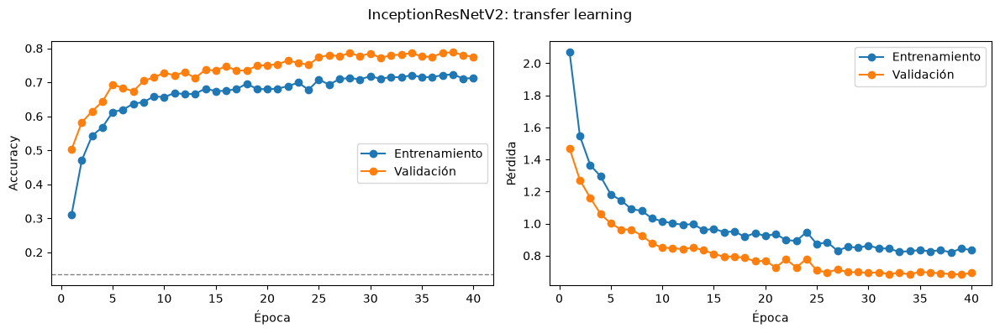

In [ ]:
curvas(hist_irv2_tl, "InceptionResNetV2: transfer learning")

InceptionResNetV2: transfer learning
Accuracy: 78.6% · F1 macro: 0.764 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.654     0.340     0.447        50
                 Charlock      0.767     0.896     0.826        77
                 Cleavers      0.851     0.769     0.808        52
         Common Chickweed      0.746     0.782     0.764       124
             Common wheat      0.795     0.756     0.775        41
                  Fat Hen      0.694     0.716     0.705        95
         Loose Silky-bent      0.753     0.906     0.823       128
                    Maize      0.918     0.918     0.918        49
        Scentless Mayweed      0.733     0.825     0.776       103
          Shepherds Purse      0.913     0.404     0.560        52
Small-flowered Cranesbill      0.875     0.958     0.915        95
               Sugar beet      0.905     0.798     0.848        84

     

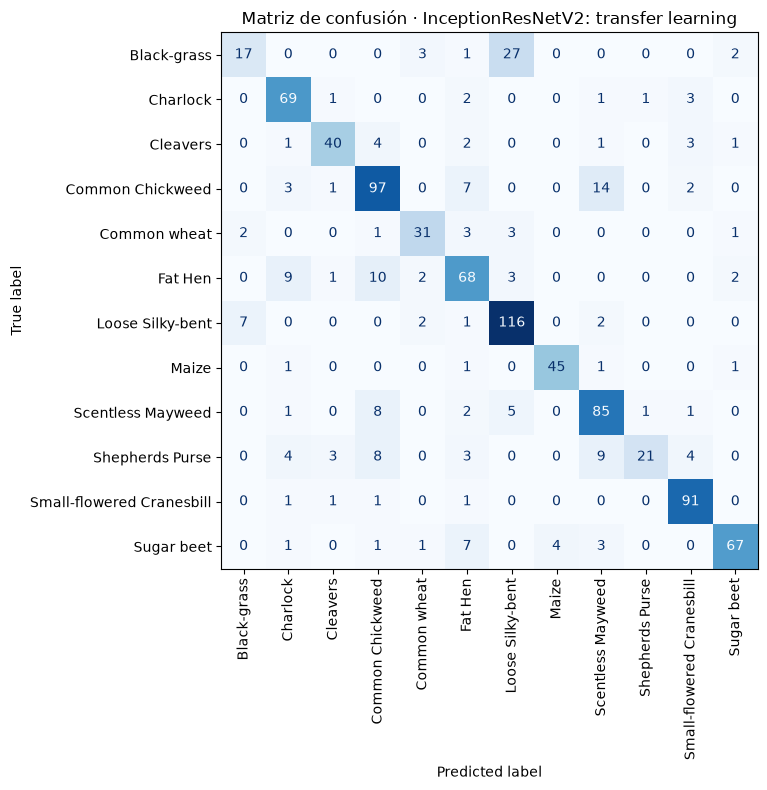

In [ ]:
res_irv2_tl = evaluar(irv2_tl, titulo="InceptionResNetV2: transfer learning")

**Qué muestran las curvas y la evaluación del transfer learning.**

* **La red aprende muy rápido al principio.** Ya en la primera época acierta el 50 % de la validación, porque la cabeza nueva solo tiene que aprender a combinar características que la red base ya sabe extraer. Después sube despacio hasta el **78,6 %** (mejor época 34, F1 macro **0,764**). Tardó 12,9 minutos y llegó al límite de 40 épocas.
* **El entrenamiento es estable**, sin los saltos de la Estrategia 1, y **no hay sobreajuste**. La accuracy de entrenamiento (72 %) queda por debajo de la de validación por el data augmentation y el Dropout.
* **Se queda por debajo de nuestra red del Exp. 4 (85,5 %).** Las características de ImageNet son genéricas (objetos, animales, escenas), y las plántulas vistas desde arriba sobre gravilla se parecen poco a esas fotos. Con la base congelada, la cabeza (solo 18.444 parámetros) no puede crear características nuevas, solo combinar las que ya existen.
* **Sus errores son prudentes.** Ninguno tiene más de un 99 % de seguridad, frente al 71 % del Exp. 4. Con la base congelada y una sola capa nueva, las salidas no llegan a esos extremos.
* Las especies más difíciles son *Black-grass* (17 de 50; 27 se confunden con *Loose Silky-bent*), *Shepherds Purse* (21 de 52, con errores repartidos entre seis especies) y *Fat Hen* (68 de 95).

Es justo lo que justifica el fine-tuning, porque hay que adaptar las últimas capas de la red base para que detecten patrones propios de nuestras plantas.

#### Fine-tuning

Partimos del mejor modelo del transfer learning y descongelamos la **última etapa** de la red base, desde el bloque `mixed_7a` hasta el final. Es la última etapa, que reduce los mapas a 5 × 5, trabaja con ellos y detecta los patrones más específicos, los que más dependen de las fotos con las que se entrenó. Las primeras capas, que detectan bordes y texturas generales, siguen congeladas, igual que todas las capas BatchNorm.

In [ ]:
irv2_tl = preparar_fine_tuning(irv2_tl, "mixed_7a")

Fine-tuning de inception_resnet_v2 desde la capa mixed_7a: 23.550.284 parámetros entrenables de 54.355.180 (43.3%)


**Modelo ya entrenado.** El modelo de esta fase (`irv2_fine_tuning.keras`, 409 MB) está disponible en [Google Drive](https://drive.google.com/file/d/1ksolBaWmL7tgd1zLD7zyf5ZmXphW4IzY/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia2/` junto a su historial (`irv2_fine_tuning_historial.json`). La función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, se entrena de nuevo (en un Mac M4 Pro tarda unos 13 minutos).

In [ ]:
irv2_ft, hist_irv2_ft = entrenar(irv2_tl, "irv2_fine_tuning", carpeta=RESULTADOS_E2,
                                 lr=LR_FINE_TUNING, max_epocas=MAX_EPOCAS_FT)

Epoch 1/20


119/119 - 127s - 1s/step - accuracy: 0.7668 - loss: 0.6861 - val_accuracy: 0.8253 - val_loss: 0.5283 - learning_rate: 1.0000e-05


Epoch 2/20


119/119 - 67s - 564ms/step - accuracy: 0.8139 - loss: 0.5387 - val_accuracy: 0.8421 - val_loss: 0.4510 - learning_rate: 1.0000e-05


Epoch 3/20


119/119 - 57s - 483ms/step - accuracy: 0.8345 - loss: 0.4593 - val_accuracy: 0.8632 - val_loss: 0.4181 - learning_rate: 1.0000e-05


... (31 outputs left out)

119/119 - 30s - 252ms/step - accuracy: 0.9455 - loss: 0.1450 - val_accuracy: 0.9168 - val_loss: 0.2749 - learning_rate: 1.0000e-05


Epoch 20/20


119/119 - 30s - 252ms/step - accuracy: 0.9547 - loss: 0.1315 - val_accuracy: 0.9116 - val_loss: 0.2952 - learning_rate: 1.0000e-05


Tiempo de entrenamiento: 12.5 min


#### Monitorización y evaluación

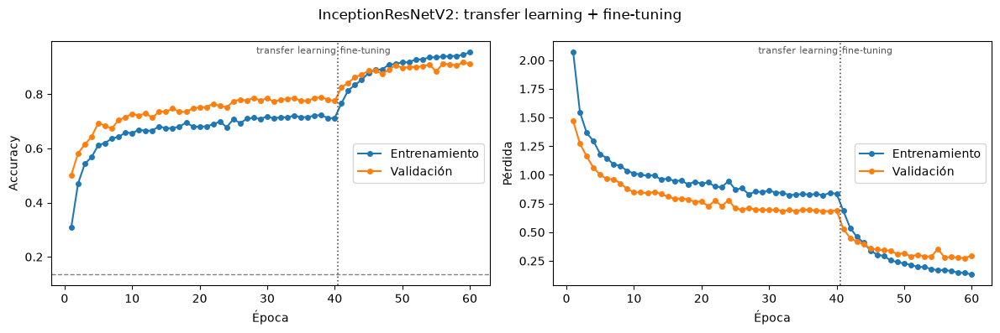

In [ ]:
curvas_fases(hist_irv2_tl, hist_irv2_ft, "InceptionResNetV2: transfer learning + fine-tuning")

InceptionResNetV2: fine-tuning
Accuracy: 91.7% · F1 macro: 0.907 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.636     0.560     0.596        50
                 Charlock      0.961     0.961     0.961        77
                 Cleavers      0.926     0.962     0.943        52
         Common Chickweed      0.943     0.927     0.935       124
             Common wheat      0.944     0.829     0.883        41
                  Fat Hen      0.911     0.968     0.939        95
         Loose Silky-bent      0.837     0.883     0.859       128
                    Maize      0.979     0.959     0.969        49
        Scentless Mayweed      0.925     0.951     0.938       103
          Shepherds Purse      0.957     0.865     0.909        52
Small-flowered Cranesbill      1.000     0.979     0.989        95
               Sugar beet      0.943     0.976     0.959        84

           

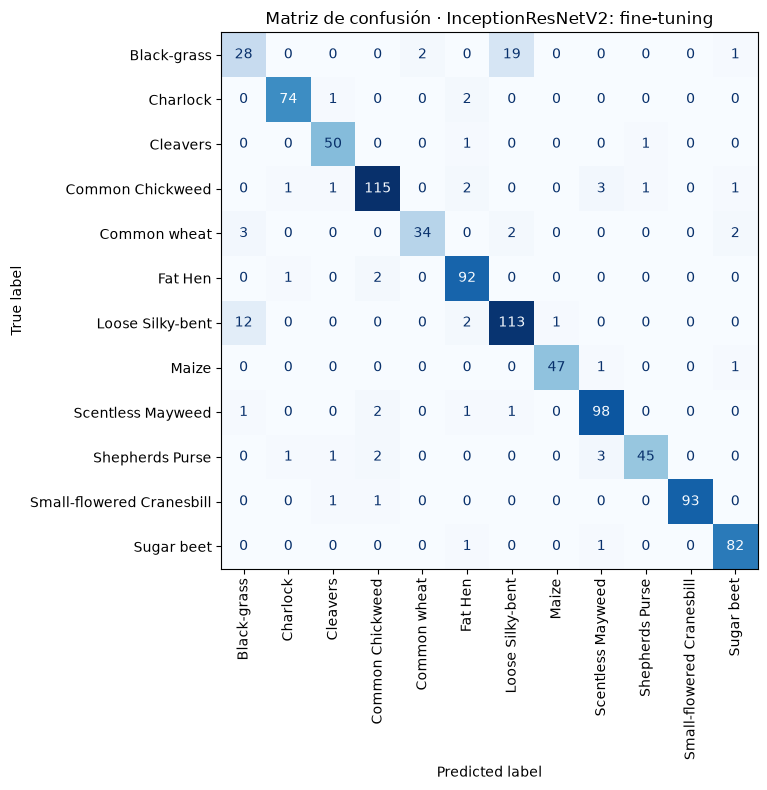

In [ ]:
res_irv2_ft = evaluar(irv2_ft, titulo="InceptionResNetV2: fine-tuning")

**Qué muestran las curvas y la evaluación del fine-tuning.**

* **El salto es inmediato.** En la primera época de fine-tuning la validación pasa del 78,6 % al **82,5 %**, y sigue subiendo casi sin interrupciones hasta el **91,7 %** en la época 19 (F1 macro **0,907**). Se descongelaron 23,6 millones de parámetros (el 43 % de la red) y tardó 12,5 minutos.
* **El learning rate nunca tuvo que bajar.** Con 0,00001 la pérdida de validación mejoró casi en cada época, y la red **seguía mejorando al llegar al límite de 20 épocas**. Con más épocas probablemente habría ganado algo más.
* **Aparece una pequeña diferencia entre entrenamiento (94,6 %) y validación (91,7 %).** Dentro de la Estrategia 2, es la primera vez que el entrenamiento supera a la validación. Al reentrenar 23,6 millones de parámetros con 3.800 fotos, la red empieza a ajustarse algo a las fotos de entrenamiento. Con 3 puntos de diferencia no es un problema, pero indica que no convendría descongelar mucho más.
* **Mejoran todas las especies.** *Shepherds Purse* pasa de 21 a **45 de 52** fotos (F1 de 0,56 a 0,91), y *Small-flowered Cranesbill* (0,99), *Maize* (0,97), *Charlock* y *Sugar beet* (0,96) quedan casi perfectas.
* **La confusión entre gramíneas sigue siendo el punto débil**, aunque menor. *Black-grass* reconoce 28 de 50 fotos (F1 0,60; 19 se confunden con *Loose Silky-bent*) y 12 fotos de *Loose Silky-bent* se clasifican como *Black-grass*.
* **Los errores siguen siendo prudentes.** Solo el 6 % tienen más de un 99 % de seguridad.

### 5.2 MobileNetV2

**Responsable.** Juan José

#### Transfer learning

Mismo procedimiento que con InceptionResNetV2. La red base (2,3 millones de parámetros) se congela y solo se entrena la cabeza nueva.

In [ ]:
mnv2.summary()
print(f"Parámetros entrenables: {parametros_entrenables(mnv2):,}".replace(",", "."))

Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_6 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_6               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_6 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_6            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesado (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Parámetros entrenables: 15.372


**Modelo ya entrenado.** El modelo de esta fase (`mnv2_transfer_learning.keras`, 10 MB) está disponible en [Google Drive](https://drive.google.com/file/d/1sXokGx8VHIcvSYTTF3ROcrLOvvGu-6PV/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia2/` junto a su historial (`mnv2_transfer_learning_historial.json`). La función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, se entrena de nuevo (en un Mac M4 Pro tarda unos 6 minutos).

In [ ]:
mnv2_tl, hist_mnv2_tl = entrenar(mnv2, "mnv2_transfer_learning", carpeta=RESULTADOS_E2)

Epoch 1/40


119/119 - 15s - 130ms/step - accuracy: 0.3918 - loss: 1.8490 - val_accuracy: 0.6105 - val_loss: 1.1857 - learning_rate: 0.0010


Epoch 2/40


119/119 - 8s - 65ms/step - accuracy: 0.5918 - loss: 1.1835 - val_accuracy: 0.6758 - val_loss: 0.9746 - learning_rate: 0.0010


Epoch 3/40


119/119 - 11s - 90ms/step - accuracy: 0.6650 - loss: 0.9931 - val_accuracy: 0.7053 - val_loss: 0.8734 - learning_rate: 0.0010


... (71 outputs left out)

119/119 - 8s - 64ms/step - accuracy: 0.8134 - loss: 0.5525 - val_accuracy: 0.7758 - val_loss: 0.6003 - learning_rate: 6.2500e-05


Epoch 40/40


119/119 - 11s - 95ms/step - accuracy: 0.8155 - loss: 0.5435 - val_accuracy: 0.7789 - val_loss: 0.6108 - learning_rate: 6.2500e-05


Tiempo de entrenamiento: 6.2 min


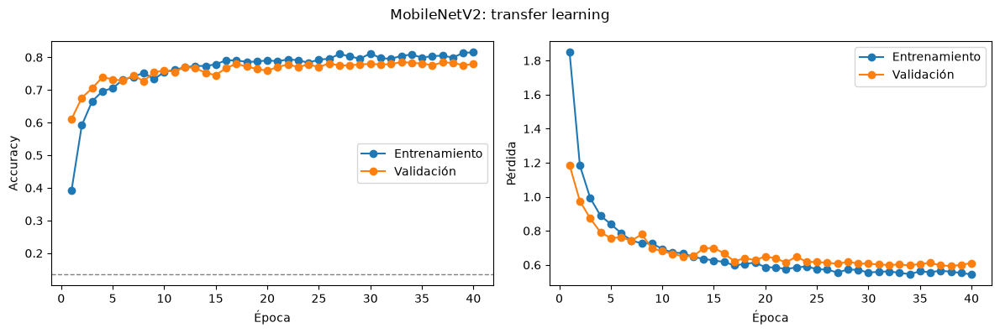

In [ ]:
curvas(hist_mnv2_tl, "MobileNetV2: transfer learning")

MobileNetV2: transfer learning
Accuracy: 78.3% · F1 macro: 0.760 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.516     0.320     0.395        50
                 Charlock      0.959     0.922     0.940        77
                 Cleavers      0.658     0.923     0.768        52
         Common Chickweed      0.906     0.621     0.737       124
             Common wheat      0.714     0.732     0.723        41
                  Fat Hen      0.771     0.779     0.775        95
         Loose Silky-bent      0.724     0.859     0.786       128
                    Maize      0.978     0.898     0.936        49
        Scentless Mayweed      0.715     0.854     0.779       103
          Shepherds Purse      0.742     0.442     0.554        52
Small-flowered Cranesbill      0.955     0.884     0.918        95
               Sugar beet      0.718     0.940     0.814        84

           

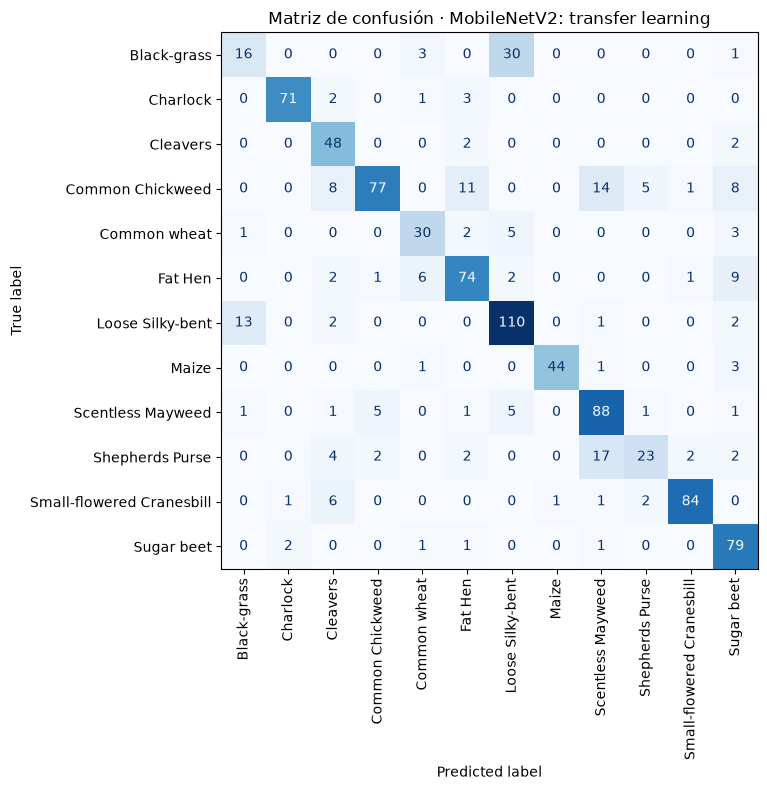

In [ ]:
res_mnv2_tl = evaluar(mnv2_tl, titulo="MobileNetV2: transfer learning")

**Qué muestran las curvas y la evaluación del transfer learning.**

* **Arranca todavía más rápido que InceptionResNetV2**, con un 61 % de acierto en la primera época. Llega al **78,3 %** en la época 38 (F1 macro **0,760**), prácticamente lo mismo que InceptionResNetV2 (78,6 %) con una red base **24 veces más pequeña**, y en la mitad de tiempo (6,2 minutos).
* El entrenamiento es estable y sin sobreajuste (80 % en entrenamiento, 78 % en validación). ReduceLROnPlateau bajó el learning rate en las épocas 16, 21, 26 y 38, y la validación apenas se movió desde la época 17, porque la cabeza ya había sacado casi todo lo que podía de las características congeladas.
* Como con InceptionResNetV2, se queda **por debajo de nuestra red del Exp. 4** y sus errores son prudentes (ninguno con más de un 99 % de seguridad). Las peores especies vuelven a ser *Black-grass* (F1 0,40) y *Shepherds Purse* (0,55).

#### Fine-tuning

Como en InceptionResNetV2, descongelamos la **última etapa** de la red base, desde el bloque `block_13_expand` hasta el final, la etapa que reduce los mapas a 7 × 7 y trabaja con ellos. En MobileNetV2 esa etapa concentra la mayoría de los parámetros, porque sus últimas capas son las que tienen más filtros. Las capas BatchNorm siguen congeladas.

In [ ]:
mnv2_tl = preparar_fine_tuning(mnv2_tl, "block_13_expand")

Fine-tuning de mobilenetv2_1.00_224 desde la capa block_13_expand: 1.678.732 parámetros entrenables de 2.273.356 (73.8%)


**Modelo ya entrenado.** El modelo de esta fase (`mnv2_fine_tuning.keras`, 23 MB) está disponible en [Google Drive](https://drive.google.com/file/d/1njI-oQEe2rxpf4bnXd8sjkfhUUa6GaMA/view?usp=sharing). Para no volver a entrenarlo, descárgalo en `resultados/estrategia2/` junto a su historial (`mnv2_fine_tuning_historial.json`). La función `entrenar()` lo cargará y mostrará el registro del entrenamiento original. Si no están los dos ficheros, se entrena de nuevo (en un Mac M4 Pro tarda unos 3 minutos).

In [ ]:
mnv2_ft, hist_mnv2_ft = entrenar(mnv2_tl, "mnv2_fine_tuning", carpeta=RESULTADOS_E2,
                                 lr=LR_FINE_TUNING, max_epocas=MAX_EPOCAS_FT)

Epoch 1/20


119/119 - 15s - 126ms/step - accuracy: 0.8108 - loss: 0.5355 - val_accuracy: 0.7863 - val_loss: 0.5611 - learning_rate: 1.0000e-05


Epoch 2/20


119/119 - 10s - 80ms/step - accuracy: 0.8197 - loss: 0.4862 - val_accuracy: 0.8168 - val_loss: 0.5065 - learning_rate: 1.0000e-05


Epoch 3/20


119/119 - 10s - 82ms/step - accuracy: 0.8376 - loss: 0.4524 - val_accuracy: 0.8189 - val_loss: 0.4785 - learning_rate: 1.0000e-05


... (31 outputs left out)

119/119 - 9s - 78ms/step - accuracy: 0.9097 - loss: 0.2457 - val_accuracy: 0.8821 - val_loss: 0.3363 - learning_rate: 1.0000e-05


Epoch 20/20


119/119 - 9s - 78ms/step - accuracy: 0.9129 - loss: 0.2406 - val_accuracy: 0.8642 - val_loss: 0.3804 - learning_rate: 1.0000e-05


Tiempo de entrenamiento: 3.2 min


#### Monitorización y evaluación

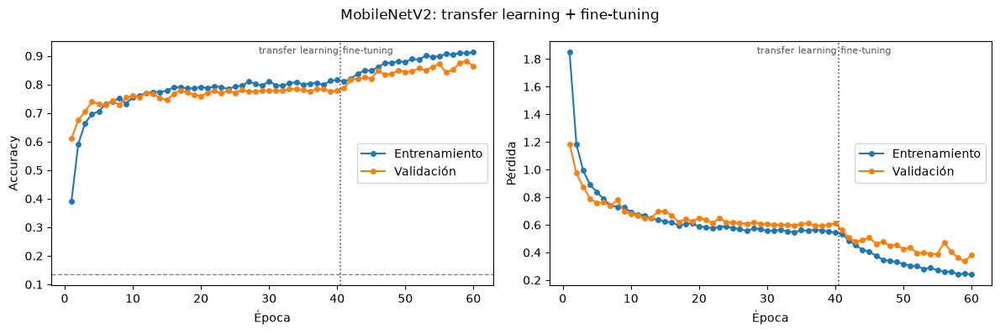

In [ ]:
curvas_fases(hist_mnv2_tl, hist_mnv2_ft, "MobileNetV2: transfer learning + fine-tuning")

MobileNetV2: fine-tuning
Accuracy: 88.2% · F1 macro: 0.869 (referencias: azar 8.3%, clase mayoritaria 13.5%)

                           precision    recall  f1-score   support

              Black-grass      0.558     0.480     0.516        50
                 Charlock      1.000     0.935     0.966        77
                 Cleavers      1.000     0.904     0.949        52
         Common Chickweed      0.938     0.855     0.895       124
             Common wheat      0.868     0.805     0.835        41
                  Fat Hen      0.899     0.937     0.918        95
         Loose Silky-bent      0.790     0.883     0.834       128
                    Maize      0.959     0.959     0.959        49
        Scentless Mayweed      0.797     0.951     0.867       103
          Shepherds Purse      0.921     0.673     0.778        52
Small-flowered Cranesbill      1.000     0.989     0.995        95
               Sugar beet      0.879     0.952     0.914        84

                 

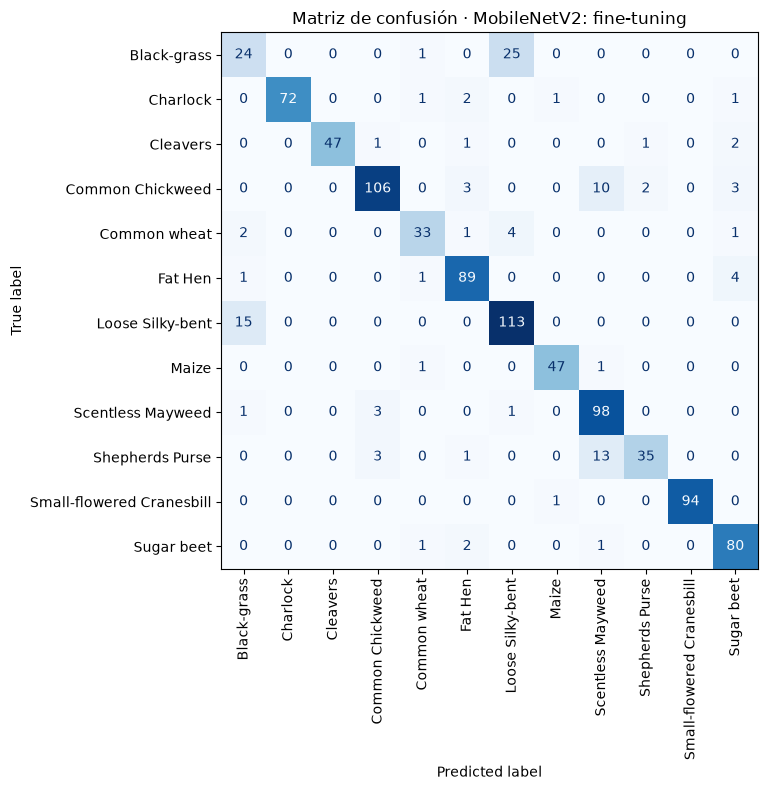

In [ ]:
res_mnv2_ft = evaluar(mnv2_ft, titulo="MobileNetV2: fine-tuning")

**Qué muestran las curvas y la evaluación del fine-tuning.**

* **El fine-tuning sube la red del 78,3 % al 88,2 %** (mejor época 19, F1 macro **0,869**). Se descongeló 1,7 millones de parámetros (el 74 % de la red) y tardó solo 3,2 minutos.
* **La validación oscila más que en InceptionResNetV2** (entre el 83 % y el 88 % desde la época 6), pero la tendencia es claramente ascendente y, como en InceptionResNetV2, **seguía mejorando al llegar a las 20 épocas**. La diferencia entre entrenamiento (91 %) y validación (88 %) es de 3 puntos, igual que en InceptionResNetV2.
* **Las especies de hoja ancha quedan casi perfectas**, como *Small-flowered Cranesbill* (F1 0,99), *Charlock* (0,97), *Maize* (0,96) y *Cleavers* (0,95).
* **Los puntos débiles son los mismos**, *Black-grass* (24 de 50; 25 se confunden con *Loose Silky-bent*) y *Shepherds Purse* (35 de 52; 13 se confunden con *Scentless Mayweed*).

**Lo sorprendente de MobileNetV2.** Con **2,3 millones de parámetros** (casi 6 veces menos que nuestra red y 24 veces menos que InceptionResNetV2), **supera a nuestra red del Exp. 4** (88,2 % frente a 85,5 %) y se queda solo 3,5 puntos por debajo de InceptionResNetV2. Entre las dos fases tardó 9,4 minutos, frente a los 25,4 minutos de InceptionResNetV2. Es el efecto de un buen diseño (las convoluciones separables) más el conocimiento previo de ImageNet.

### 5.3 Selección de la red preentrenada con mayor precisión

El enunciado pide quedarse con la red preentrenada que mayor precisión proporcione. Reunimos las cuatro versiones entrenadas, evaluadas sobre las mismas 950 fotos de validación.

In [ ]:
resumen_e2 = [
    ("InceptionResNetV2", "Transfer learning", hist_irv2_tl, res_irv2_tl, irv2_ft),
    ("InceptionResNetV2", "+ Fine-tuning", hist_irv2_ft, res_irv2_ft, irv2_ft),
    ("MobileNetV2", "Transfer learning", hist_mnv2_tl, res_mnv2_tl, mnv2_ft),
    ("MobileNetV2", "+ Fine-tuning", hist_mnv2_ft, res_mnv2_ft, mnv2_ft),
]
tabla_e2 = pd.DataFrame([{
    "Red": red, "Fase": fase,
    "Épocas": len(h.history["loss"]),
    "Mejor época": int(np.argmin(h.history["val_loss"])) + 1,
    "Accuracy": f"{r['accuracy']:.1%}".replace(".", ","),
    "F1 macro": f"{r['f1_macro']:.3f}".replace(".", ","),
} for red, fase, h, r, _ in resumen_e2]).set_index(["Red", "Fase"])

# La mejor versión (mayor accuracy; en caso de empate, mayor F1 macro) es la red preentrenada elegida
i_mejor = max(range(len(resumen_e2)), key=lambda i: (resumen_e2[i][3]["accuracy"], resumen_e2[i][3]["f1_macro"]))
red_e2, fase_e2, _, res_final_e2, modelo_final_e2 = resumen_e2[i_mejor]
print(f"Red preentrenada elegida: {red_e2} ({fase_e2.lower().lstrip('+ ')}) · accuracy {res_final_e2['accuracy']:.1%} · "
      f"F1 macro {res_final_e2['f1_macro']:.3f}")
tabla_e2.style.apply(lambda fila: ["background-color: #e8dff5; font-weight: bold" if fila.name == (red_e2, fase_e2) else ""
                                   for _ in fila], axis=1)

Red preentrenada elegida: InceptionResNetV2 (fine-tuning) · accuracy 91.7% · F1 macro 0.907


**Elegimos InceptionResNetV2 con fine-tuning**, con un **91,7 % de accuracy** y un **F1 macro de 0,907**.

* Es la versión con **mayor precisión** de las cuatro, que es el criterio que fija el enunciado, y también la de mejor F1 macro.
* Supera a MobileNetV2 con fine-tuning en **3,5 puntos de accuracy** y 0,038 de F1 macro, y tiene un F1 mejor en 9 de las 12 especies. En *Charlock*, *Cleavers* y *Small-flowered Cranesbill*, MobileNetV2 queda ligeramente por encima (menos de 0,01).
* **El fine-tuning es imprescindible en las dos redes.** Solo con transfer learning ninguna llegaba al nivel de nuestra red desde cero (78,6 % y 78,3 % frente a 85,5 %). Al adaptar sus últimas capas a nuestras fotos, mejoran 13 y 10 puntos.

**Limitaciones.**

* Como en la Estrategia 1, es **un solo entrenamiento por versión** y la elección se hace con las mismas fotos de validación con las que se evalúa.
* Las dos redes **seguían mejorando al terminar las 20 épocas de fine-tuning**, así que sus resultados no son el máximo que podrían alcanzar.
* **MobileNetV2 es una alternativa muy razonable** si importan el tamaño o la velocidad. Con 24 veces menos parámetros, pierde solo 3,5 puntos y entrena casi 3 veces más rápido.

La red elegida se guarda como `modelo_final_e2` y se compara con el modelo final de la Estrategia 1 en el apartado 6.

## 6. Comparación de las dos estrategias

**Responsable.** Juan José

Comparamos el **modelo final de cada estrategia**, elegidos con el mismo criterio (mayor accuracy y F1 macro en validación).

* **Estrategia 1.** Nuestra red desde cero del **Exp. 4** (data augmentation + BatchNorm + Dropout 0,3).
* **Estrategia 2.** **InceptionResNetV2 con fine-tuning**.

Incluimos también **MobileNetV2 con fine-tuning** como referencia, porque es la red más ligera de las tres. Todas se evalúan sobre las mismas 950 fotos de validación.

### 6.1 Métricas globales y coste

In [ ]:
from sklearn.metrics import f1_score


def predicciones(modelo, datos=None):
    # Etiquetas reales, especie predicha y seguridad de cada predicción (probabilidad más alta)
    datos = val_ds if datos is None else datos
    y_real, probs = [], []
    for x, y in datos:
        y_real.append(y.numpy())
        probs.append(modelo.predict_on_batch(x))
    probs = np.concatenate(probs)
    return np.concatenate(y_real), probs.argmax(axis=1), probs.max(axis=1)


finalistas = [
    ("Estrategia 1: nuestra red (Exp. 4)", modelo_final_e1, "≈ 7"),
    (f"Estrategia 2: {red_e2} + fine-tuning", modelo_final_e2, "25,4"),
    ("Referencia: MobileNetV2 + fine-tuning", mnv2_ft, "9,4"),
]
filas, f1_especie = [], {}
for nombre, modelo, minutos in finalistas:
    y_real, y_pred, seguridad = predicciones(modelo)
    errores = y_pred != y_real
    f1_especie[nombre] = f1_score(y_real, y_pred, average=None)
    filas.append({
        "Modelo": nombre,
        "Accuracy": f"{(~errores).mean():.1%}".replace(".", ","),
        "F1 macro": f"{f1_especie[nombre].mean():.3f}".replace(".", ","),
        "Fotos mal clasificadas (de 950)": int(errores.sum()),
        "Errores con más de un 99 % de seguridad": f"{(seguridad[errores] > 0.99).mean():.0%}",
        "Parámetros": f"{modelo.count_params():,}".replace(",", "."),
        "Parámetros entrenados en la última fase": f"{parametros_entrenables(modelo):,}".replace(",", "."),
        "Tiempo de entrenamiento (min)": minutos,
    })
comparacion_final = pd.DataFrame(filas).set_index("Modelo")
comparacion_final.T.style.apply(
    lambda col: ["background-color: #e8dff5; font-weight: bold" if col.name.startswith("Estrategia 2") else "" for _ in col])

Modelo,Estrategia 1: nuestra red (Exp. 4),Estrategia 2: InceptionResNetV2 + fine-tuning,Referencia: MobileNetV2 + fine-tuning
Accuracy,"85,5%","91,7%","88,2%"
F1 macro,"0,836","0,907","0,869"
Fotos mal clasificadas (de 950),138,79,112
Errores con más de un 99 % de seguridad,71%,6%,1%
Parámetros,12.940.876,54.355.180,2.273.356
Parámetros entrenados en la última fase,12.940.428,23.550.284,1.678.732
Tiempo de entrenamiento (min),≈ 7,"25,4","9,4"


Los tiempos son los de entrenamiento en un Mac M4 Pro. En la Estrategia 2 suman las dos fases, transfer learning y fine-tuning.

### 6.2 Comparación por especie

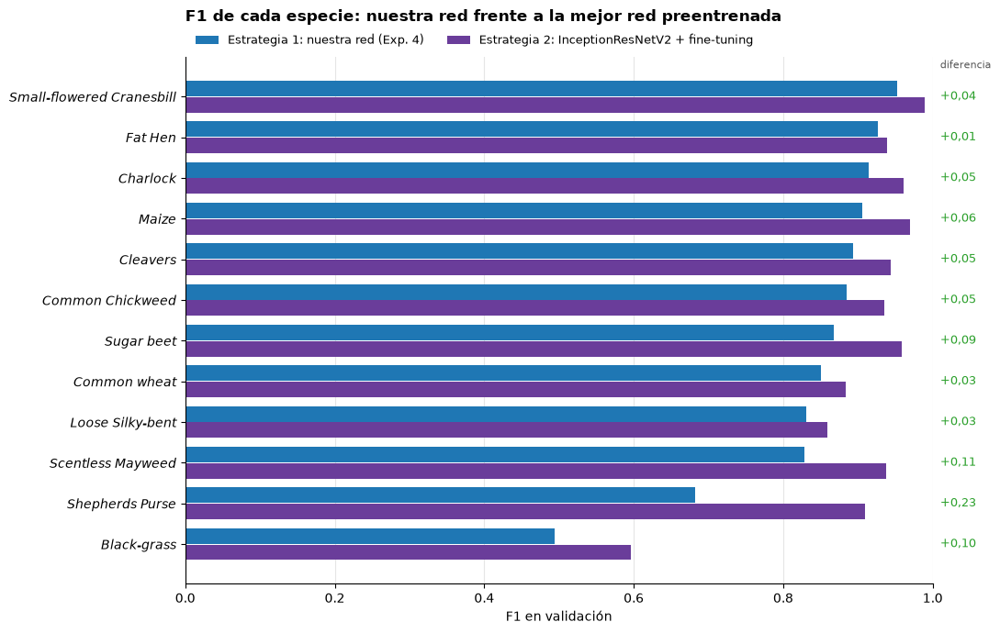

In [ ]:
# @title Gráfico: F1 de cada especie con el modelo final de cada estrategia
FIGURAS = BASE_FOLDER.parent / "resultados" / "figuras"
e1, e2 = finalistas[0][0], finalistas[1][0]
orden = np.argsort(f1_especie[e1])                        # de la especie más difícil a la más fácil para nuestra red
y = np.arange(NUM_CLASES)
alto = 0.38

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y + alto / 2 + 0.01, f1_especie[e1][orden], alto, label="Estrategia 1: nuestra red (Exp. 4)", color="#1f77b4")
ax.barh(y - alto / 2 - 0.01, f1_especie[e2][orden], alto, label=f"Estrategia 2: {red_e2} + fine-tuning", color="#6a3d9a")
for i, k in enumerate(orden):
    dif = f1_especie[e2][k] - f1_especie[e1][k]
    ax.text(1.01, i, f"{dif:+.2f}".replace(".", ","), va="center", fontsize=9,
            color="#2ca02c" if dif > 0 else "#d62728", transform=ax.get_yaxis_transform())
ax.text(1.01, NUM_CLASES - 0.3, "diferencia", fontsize=8, color="#555555", transform=ax.get_yaxis_transform())
ax.set_yticks(y); ax.set_yticklabels([CLASES[k] for k in orden], fontstyle="italic")
ax.set_xlim(0, 1); ax.set_xlabel("F1 en validación")
ax.set_title("F1 de cada especie: nuestra red frente a la mejor red preentrenada", loc="left", weight="bold", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
ax.grid(axis="x", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURAS / "comparacion_f1_por_especie.png", dpi=150, bbox_inches="tight")
plt.show()

**Cómo leer el gráfico.** Cada especie tiene dos barras, la azul con el F1 de nuestra red (Exp. 4) y la morada con el de InceptionResNetV2, y a la derecha la diferencia entre las dos. La red preentrenada es mejor en las 12 especies, pero **la mejora no es igual en todas, y es mayor justo en las más difíciles para nuestra red**. *Shepherds Purse* sube de 0,68 a 0,91 (+0,23), *Scentless Mayweed* +0,11 y *Black-grass* +0,10, mientras que en las que ya reconocíamos bien la ganancia es pequeña (*Fat Hen* +0,01, *Small-flowered Cranesbill* +0,04).

**Nuestra hipótesis sobre el motivo.** Las especies fáciles se distinguen por rasgos gruesos, como hojas anchas y redondeadas, que nuestra red aprende sin problema con 3.800 fotos. Las difíciles son plantas pequeñas o de hojas finas que solo se diferencian en detalles, como el borde de la hoja, su textura o cómo se ramifica. Para captar esos detalles hacen falta muchos filtros finos y muy variados, y nuestra red no tiene fotos suficientes para aprenderlos, mientras que InceptionResNetV2 ya los trae aprendidos de 1,2 millones de imágenes. *Black-grass* mejora menos porque su problema es distinto. A 224 × 224 píxeles es casi idéntica a *Loose Silky-bent*, así que ni siquiera esos detalles bastan para separarlas.

### 6.3 Qué muestra la comparación

**La Estrategia 2 gana con claridad.** InceptionResNetV2 con fine-tuning acierta el **91,7 %** frente al **85,5 %** de nuestra red, es decir, **6,2 puntos más** de accuracy y 0,071 más de F1 macro. Dicho de otra forma, se equivoca en **79 fotos de 950 frente a 138**, un 43 % menos de errores.

**Es mejor en las 12 especies**, y la ventaja es mayor justo donde nuestra red tenía más problemas.

* ***Shepherds Purse*** (+0,23 de F1) y ***Scentless Mayweed*** (+0,11), plantas pequeñas de hojas finas que nuestra red confundía entre sí. Distinguirlas exige detalles finos de forma y textura, que es lo que la red preentrenada ya sabía detectar.
* ***Black-grass*** (+0,10) mejora, pero **sigue siendo la peor especie en las dos estrategias** (F1 0,49 y 0,60). Su confusión con *Loose Silky-bent* no la resuelve ninguna red, porque a 224 × 224 píxeles las dos gramíneas son casi idénticas. Parece un límite de los datos más que del modelo.
* Donde nuestra red ya funcionaba bien, la diferencia es pequeña (*Fat Hen* +0,01, *Small-flowered Cranesbill* +0,04).

**Sus probabilidades son mucho más fiables.** Solo el 6 % de sus errores tienen más de un 99 % de seguridad, frente al 71 % de nuestra red. Si el modelo se usara en el campo, sus dudas servirían para saber qué fotos conviene revisar a mano. Si hubiéramos elegido el Exp. 5 (con L2) como modelo final, esta diferencia casi desaparecería, porque la L2 bajó ese porcentaje al **7 %**, prácticamente igual que InceptionResNetV2. A cambio, nuestra red acertaría menos (81,1 % frente a 85,5 %), y la distancia con InceptionResNetV2 pasaría de 6,2 a 10,6 puntos. Es decir, el exceso de confianza de nuestra red se debe sobre todo a que el modelo elegido no lleva L2, no a que sea una red desde cero.

**El precio es el tamaño y el tiempo.** InceptionResNetV2 tiene 4 veces más parámetros que nuestra red (54 millones frente a 13) y tardó unas 3,5 veces más en entrenarse (25 minutos frente a unos 7). En cambio, **MobileNetV2 con fine-tuning supera a nuestra red con casi 6 veces menos parámetros** (88,2 % con 2,3 millones), en 9 minutos.

**Por qué gana la Estrategia 2.** No es por tener más épocas ni más parámetros entrenables. La prueba del apartado 4.6 mostró que nuestra red ya estaba en su techo (con 100 épocas de límite se quedó en el 84,1 %), y MobileNetV2 la supera con muchos menos parámetros. La diferencia está en el **conocimiento previo**. Las redes preentrenadas aprendieron a ver con 1,2 millones de fotos, y solo tuvieron que adaptarse a nuestras plantas. Nuestra red tuvo que aprenderlo todo, desde los bordes hasta la forma de las hojas, con 3.800.

**¿Es fiable la diferencia?** Cada modelo se ha entrenado una sola vez, y la misma red puede variar unos puntos de un entrenamiento a otro (hasta unos 5 puntos entre semillas en el estudio previo del Dropout). Además, los dos modelos finales se eligieron con las mismas fotos con las que se comparan. Aun así, **6,2 puntos y una ventaja en las 12 especies** son una diferencia demasiado grande y consistente para deberse al azar.

## 7. Discusión y conclusiones

### 7.1 Resumen de resultados

**Responsable.** Juan José

| Estrategia | Modelo | Accuracy | F1 macro |
|---|---|---|---|
| Referencias | Azar / siempre la clase mayoritaria | 8,3 % / 13,5 % | — |
| 1. Desde cero | Exp. 1, red base | 63,5 % | 0,581 |
| 1. Desde cero | Exp. 2, + data augmentation | 69,4 % | 0,658 |
| 1. Desde cero | Exp. 3, + batch normalization | 73,5 % | 0,698 |
| 1. Desde cero | **Exp. 4, + dropout (modelo final)** | **85,5 %** | **0,836** |
| 1. Desde cero | Exp. 5, + regularización L2 | 81,1 % | 0,799 |
| 2. Preentrenadas | InceptionResNetV2, transfer learning | 78,6 % | 0,764 |
| 2. Preentrenadas | **InceptionResNetV2, fine-tuning (modelo final)** | **91,7 %** | **0,907** |
| 2. Preentrenadas | MobileNetV2, transfer learning | 78,3 % | 0,760 |
| 2. Preentrenadas | MobileNetV2, fine-tuning | 88,2 % | 0,869 |

**La mejor solución es InceptionResNetV2 con fine-tuning**, con un 91,7 % de acierto y un F1 macro de 0,907. Está 6,2 puntos por encima de nuestra mejor red desde cero y es mejor en las 12 especies.

### 7.2 Lo que hemos aprendido con la Estrategia 1

**Responsable.** Alfredo y Raúl

* **Cada técnica resolvió un problema distinto.** El data augmentation eliminó el sobreajuste de la red base. El BatchNorm mejoró el resultado, pero hizo el arranque caótico. El Dropout dio el mayor salto (+12 puntos), sobre todo porque estabilizó el entrenamiento.
* **No todas las técnicas mejoran siempre.** La L2 consiguió lo que se esperaba de ella, que la red se equivocara con menos seguridad, pero bajó el acierto 4,4 puntos. Por eso el modelo final es el Exp. 4 y no el último de la cadena.
* **El protocolo de entrenamiento importa tanto como la arquitectura.** Sin ReduceLROnPlateau, la red del Exp. 3 no habría salido del arranque caótico. Y con una patience de 5 en lugar de 10, se habría parado en la época 28 con un 68,2 %, 5 puntos menos. En el sondeo, con un arranque algo peor, se paró en la época 6 y pareció que la arquitectura no funcionaba con BatchNorm.
* **El punto débil de nuestra red es su capa densa**, con el 99 % de los parámetros. Es la causa del entrenamiento inestable y de las probabilidades exageradas, y limita lo que puede aprender. Con 100 épocas de límite no pasó del 84–85 %.

### 7.3 Lo que hemos aprendido con la Estrategia 2

**Responsable.** Juan José

* **Una red preentrenada no funciona bien "tal cual".** Con la base congelada (transfer learning), las dos redes se quedaron por debajo de nuestra red desde cero (78 % frente a 85,5 %), porque las características de ImageNet son demasiado genéricas para distinguir plántulas casi idénticas.
* **El fine-tuning es lo que marca la diferencia.** Al reentrenar las últimas capas con un learning rate muy pequeño, InceptionResNetV2 subió 13 puntos y MobileNetV2, 10.
* **Más grande no siempre es mucho mejor.** MobileNetV2, con 24 veces menos parámetros que InceptionResNetV2, se quedó solo 3,5 puntos por debajo, superó a nuestra red y entrenó casi 3 veces más rápido. Si el modelo tuviera que funcionar en un móvil o en una máquina agrícola, sería la opción más práctica.
* **Sin una red preentrenada, lo que hemos hecho en la Estrategia 1 es la mejor aproximación.** InceptionResNetV2 no aprendió a ver con nuestras 3.800 fotos, sino con los **1,2 millones de imágenes de ImageNet**, y ese entrenamiento inicial llevó días o semanas con muchas GPU. Nosotros solo hemos hecho el último ajuste, que en nuestro Mac tardó unos 25 minutos (en un ordenador sin GPU serían varias horas, según nuestra estimación). Si no existieran redes preentrenadas, no tendríamos ni las imágenes ni la capacidad de cálculo para conseguir algo parecido. Lo razonable sería justo lo que hicimos, una red pequeña entrenada desde cero y bien regularizada con data augmentation, BatchNorm y Dropout, que llega al 85,5 % (86,9 % con las fotos de test de Kaggle, apartado 4.7) entrenando unos 7 minutos.

### 7.4 ¿Se podría hacer fine-tuning de nuestra red?

**Responsable.** Raúl

Técnicamente sí, pero no tendría sentido. El fine-tuning sirve para adaptar a una tarea nueva lo que una red **aprendió en otro sitio** (aquí, con 1,2 millones de fotos de ImageNet). Nuestra red se entrenó entera con nuestras 3.800 fotos desde la primera época, así que no hay conocimiento de otro dataset que adaptar. Además, en la práctica ya hizo algo parecido. ReduceLROnPlateau bajó su learning rate hasta 0,00003, del mismo orden que el 0,00001 que usamos en el fine-tuning de las redes preentrenadas.

Lo que sí se podría hacer con nuestra red es **entrenarla más épocas**. El Exp. 4 llegó al límite de 40 épocas y seguía mejorando un poco, así que con más épocas quizá ganaría algún punto. Pero eso no es fine-tuning, es alargar el entrenamiento. Además, sería poco probable que se acercara al 91,7 % de InceptionResNetV2 con fine-tuning, porque lo que le falta a nuestra red no son épocas, sino ese conocimiento previo.

**Lo hemos comprobado** (prueba adicional del apartado 4.6). Entrenada desde cero con un límite de 100 épocas, la misma red se paró sola en la época 56 y acertó el **84,1 %**, prácticamente lo mismo que con 40 épocas (85,5 %). Después de la época 40 solo mejoró ligeramente la pérdida (mejor época 46), sin superar el acierto del Exp. 4. La distancia con InceptionResNetV2 (91,7 %) no se cierra entrenando más.

### 7.5 Limitaciones

**Responsable.** Carmen

* **Un solo entrenamiento por modelo.** La misma red puede variar unos puntos de un entrenamiento a otro, así que las diferencias pequeñas (como la de 4,4 puntos entre los Exp. 4 y 5) no son definitivas. Los 6,2 puntos entre las dos estrategias son más fiables, sobre todo porque InceptionResNetV2 es mejor en las 12 especies.
* **La validación se usa para elegir y para evaluar.** Las fotos de `test/` no tienen etiqueta, así que los modelos finales se eligieron y se compararon con las mismas 950 fotos. Eso da una estimación algo optimista, igual para las dos estrategias. La comprobación con las fotos de test de Kaggle (apartado 4.7) muestra que esa ventaja es pequeña, porque los resultados cambian menos de 1,5 puntos.
* **Las gramíneas siguen sin resolverse.** *Black-grass* es la peor especie con todos los modelos salvo la red base (Exp. 1). Incluso la mejor red confunde con *Loose Silky-bent* 19 de sus 50 fotos. Una posible causa es que a 224 × 224 píxeles se pierden los detalles finos que las distinguen, aunque casi la mitad de las fotos ya son más pequeñas que ese tamaño (apartado 7.6).
* **Los fine-tunings se cortaron en 20 épocas** cuando todavía mejoraban, así que las redes preentrenadas podrían rendir algo más.

### 7.6 Posibles mejoras

**Responsable.** Carmen

* **Imágenes de mayor resolución** para las gramíneas, cuyas diferencias están en detalles muy finos. Por ejemplo, 299 × 299, el tamaño original de InceptionResNetV2.
* **Más épocas de fine-tuning**, ya que las dos redes preentrenadas seguían mejorando.
* **Sustituir `Flatten` por `GlobalAveragePooling`** en nuestra red, como hacen las preentrenadas, para eliminar la enorme capa densa que causa su inestabilidad.
* **Dar más peso a las especies difíciles** durante el entrenamiento (por ejemplo, con `class_weight`) para mejorar *Black-grass*.
* **Repetir cada entrenamiento con varias semillas** y comparar medias, para que las conclusiones no dependan de una sola ejecución.

### 7.7 Conclusión final

**Responsable.** todo el grupo

Con 3.800 fotos, una red diseñada desde cero puede llegar a un 85 % de acierto si se combinan bien las técnicas de regularización y el protocolo de entrenamiento. Pero aprovechar lo que una red ya aprendió con millones de imágenes, y adaptarlo con fine-tuning, da un resultado claramente mejor (91,7 %) en todas las especies. **Para un problema con pocos datos como este, la estrategia recomendable es la red preentrenada con fine-tuning**, InceptionResNetV2 si lo que importa es el máximo acierto, y MobileNetV2 si importan el tamaño y la velocidad.

**Lo que nos llevamos como grupo.** Hemos aprendido mucho con esta práctica. Ver cada técnica en acción, con sus curvas, sus errores y sus resultados, nos ha ayudado a entender con mucha más claridad los conceptos de la asignatura, como el sobreajuste, la regularización, el papel del learning rate o el transfer learning. También nos ha mostrado lo mucho que depende el resultado de la arquitectura. Una red diseñada hace unos años con muchas más imágenes supera a la nuestra con poco esfuerzo, y creemos que el diseño de nuevas arquitecturas de redes neuronales seguirá revolucionando esta área de conocimiento.